In [ ]:

from google.colab import drive

drive.mount('/content/drive')

print("Google Drive connected successfully!")


Mounted at /content/drive
Google Drive connected successfully!


In [ ]:

import os

PROJECT_DIR = "/content/drive/MyDrive/AeroSense_AI"

folders = [
    "data",
    "notebooks",
    "results/deep_learning",
    "results/foundation_models",
    "models/deep_learning",
    "reports"
]

for folder in folders:
    os.makedirs(os.path.join(PROJECT_DIR, folder), exist_ok=True)

print("Project folders created successfully!")
print("Project location:", PROJECT_DIR)


Project folders created successfully!
Project location: /content/drive/MyDrive/AeroSense_AI


In [ ]:

import pandas as pd
from pathlib import Path

DATA_PATH = f"{PROJECT_DIR}/data/air_quality_hourly.parquet"

df = pd.read_parquet(DATA_PATH)

print("Dataset shape:", df.shape)
print("Stations:", df["station"].nunique())
print("Date range:", df["timestamp"].min(), "to", df["timestamp"].max())

display(df.head())


Dataset shape: (420768, 14)
Stations: 12
Date range: 2013-03-01 00:00:00 to 2017-02-28 23:00:00


,timestamp,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,2013-03-01 00:00:00,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2013-03-01 01:00:00,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,2013-03-01 02:00:00,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,2013-03-01 03:00:00,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,2013-03-01 04:00:00,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin


In [ ]:
!pip install -q numpy pandas pyarrow scikit-learn matplotlib seaborn joblib


In [ ]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not detected. You can still run on CPU.")


PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


In [ ]:

import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler

# Load dataset
df = pd.read_parquet(DATA_PATH)

df["timestamp"] = pd.to_datetime(df["timestamp"])
df = df.sort_values(["station", "timestamp"]).reset_index(drop=True)

# Start with one station for a reproducible prototype.
# We will expand to all 12 stations after validating the pipeline.
station_name = "Aotizhongxin"

station_df = (
    df[df["station"] == station_name]
    .sort_values("timestamp")
    .reset_index(drop=True)
)

# Selected numeric input variables
features = [
    "PM2.5", "PM10", "SO2", "NO2",
    "CO", "O3", "TEMP", "PRES",
    "DEWP", "RAIN", "WSPM"
]

target = "PM2.5"

# Handle missing values using past observations only.
station_df[features] = (
    station_df[features]
    .ffill()
)

# Remove initial rows that still contain missing values.
station_df = station_df.dropna(subset=features).reset_index(drop=True)

print("Station:", station_name)
print("Prepared shape:", station_df.shape)
print("Remaining missing values:", station_df[features].isna().sum().sum())


Station: Aotizhongxin
Prepared shape: (35064, 14)
Remaining missing values: 0


In [ ]:

from sklearn.preprocessing import StandardScaler

LOOKBACK = 24
HORIZONS = [1, 6, 24]

n = len(station_df)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

# Fit scalers using training data only.
feature_scaler = StandardScaler()
target_scaler = StandardScaler()

feature_scaler.fit(station_df.loc[:train_end-1, features])
target_scaler.fit(
    station_df.loc[:train_end-1, [target]]
)

X_scaled = feature_scaler.transform(station_df[features])
y_scaled = target_scaler.transform(station_df[[target]]).ravel()

def create_sequences(X, y, lookback, horizon):
    sequences, targets, target_indices = [], [], []

    for i in range(lookback, len(X) - horizon + 1):
        sequences.append(X[i-lookback:i])
        targets.append(y[i+horizon-1])
        target_indices.append(i+horizon-1)

    return (
        np.asarray(sequences, dtype=np.float32),
        np.asarray(targets, dtype=np.float32),
        np.asarray(target_indices)
    )

datasets = {}

for horizon in HORIZONS:
    X_seq, y_seq, indices = create_sequences(
        X_scaled, y_scaled, LOOKBACK, horizon
    )

    train_mask = indices < train_end
    val_mask = (indices >= train_end) & (indices < val_end)
    test_mask = indices >= val_end

    datasets[horizon] = {
        "X_train": X_seq[train_mask],
        "y_train": y_seq[train_mask],
        "X_val": X_seq[val_mask],
        "y_val": y_seq[val_mask],
        "X_test": X_seq[test_mask],
        "y_test": y_seq[test_mask],
    }

    print(
        f"\nHorizon: {horizon}h",
        "\nTrain:", datasets[horizon]["X_train"].shape,
        "\nValidation:", datasets[horizon]["X_val"].shape,
        "\nTest:", datasets[horizon]["X_test"].shape
    )



Horizon: 1h 
Train: (24520, 24, 11) 
Validation: (5260, 24, 11) 
Test: (5260, 24, 11)

Horizon: 6h 
Train: (24515, 24, 11) 
Validation: (5260, 24, 11) 
Test: (5260, 24, 11)

Horizon: 24h 
Train: (24497, 24, 11) 
Validation: (5260, 24, 11) 
Test: (5260, 24, 11)


In [ ]:
for horizon, data in datasets.items():
    assert len(data["X_train"]) > 0
    assert len(data["X_val"]) > 0
    assert len(data["X_test"]) > 0

print("All forecasting datasets are ready.")

All forecasting datasets are ready.


In [ ]:

import os
import time
import copy
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

print("PyTorch:", torch.__version__)


Device: cuda
GPU: Tesla T4
PyTorch: 2.14.1+cu130


In [ ]:

class LSTMModel(nn.Module):

    def __init__(self, input_size, hidden_size=64, num_layers=2, dropout=0.2):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout
        )

        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        output, _ = self.lstm(x)
        last_output = output[:, -1, :]
        return self.fc(last_output).squeeze(-1)


class GRUModel(nn.Module):

    def __init__(self, input_size, hidden_size=64, num_layers=2, dropout=0.2):
        super().__init__()

        self.gru = nn.GRU(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout
        )

        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        output, _ = self.gru(x)
        last_output = output[:, -1, :]
        return self.fc(last_output).squeeze(-1)


print("LSTM and GRU architectures defined successfully.")


LSTM and GRU architectures defined successfully.


In [ ]:

def train_model(model, train_loader, val_loader, epochs=40, patience=7):

    model = model.to(DEVICE)

    criterion = nn.MSELoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001,
        weight_decay=1e-5
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=3
    )

    best_loss = float("inf")
    best_weights = copy.deepcopy(model.state_dict())
    patience_counter = 0

    history = []

    for epoch in range(epochs):

        model.train()
        train_losses = []

        for xb, yb in train_loader:

            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)

            optimizer.zero_grad()

            predictions = model(xb)
            loss = criterion(predictions, yb)

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(), max_norm=1.0
            )

            optimizer.step()

            train_losses.append(loss.item())

        model.eval()
        val_losses = []

        with torch.no_grad():

            for xb, yb in val_loader:

                xb = xb.to(DEVICE)
                yb = yb.to(DEVICE)

                predictions = model(xb)
                loss = criterion(predictions, yb)

                val_losses.append(loss.item())

        train_loss = np.mean(train_losses)
        val_loss = np.mean(val_losses)

        scheduler.step(val_loss)

        history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "val_loss": val_loss
        })

        print(
            f"Epoch {epoch+1:02d}/{epochs} | "
            f"Train: {train_loss:.5f} | "
            f"Validation: {val_loss:.5f}"
        )

        if val_loss < best_loss:

            best_loss = val_loss
            best_weights = copy.deepcopy(model.state_dict())
            patience_counter = 0

        else:

            patience_counter += 1

        if patience_counter >= patience:
            print("Early stopping triggered.")
            break

    model.load_state_dict(best_weights)

    return model, pd.DataFrame(history)


In [ ]:

BATCH_SIZE = 256
EPOCHS = 40

INPUT_SIZE = len(features)

os.makedirs(f"{PROJECT_DIR}/models/deep_learning", exist_ok=True)
os.makedirs(f"{PROJECT_DIR}/results/deep_learning", exist_ok=True)

trained_models = {}
training_histories = {}

for horizon in HORIZONS:

    print("\n" + "=" * 65)
    print(f"FORECAST HORIZON: {horizon} HOURS")
    print("=" * 65)

    data = datasets[horizon]

    train_dataset = TensorDataset(
        torch.tensor(data["X_train"], dtype=torch.float32),
        torch.tensor(data["y_train"], dtype=torch.float32)
    )

    val_dataset = TensorDataset(
        torch.tensor(data["X_val"], dtype=torch.float32),
        torch.tensor(data["y_val"], dtype=torch.float32)
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    for model_name, ModelClass in [
        ("LSTM", LSTMModel),
        ("GRU", GRUModel)
    ]:

        print(f"\nTraining {model_name} for {horizon}h...")

        model = ModelClass(input_size=INPUT_SIZE)

        start_time = time.time()

        model, history = train_model(
            model,
            train_loader,
            val_loader,
            epochs=EPOCHS,
            patience=7
        )

        elapsed = time.time() - start_time

        key = (model_name, horizon)

        trained_models[key] = model
        training_histories[key] = history

        model_path = (
            f"{PROJECT_DIR}/models/deep_learning/"
            f"{model_name.lower()}_{horizon}h.pth"
        )

        torch.save(model.state_dict(), model_path)

        print(f"Training time: {elapsed:.2f} seconds")
        print(f"Saved model: {model_path}")

print("\nAll LSTM and GRU training runs completed.")



FORECAST HORIZON: 1 HOURS

Training LSTM for 1h...
Epoch 01/40 | Train: 0.30349 | Validation: 0.13913
Epoch 02/40 | Train: 0.09171 | Validation: 0.09311
Epoch 03/40 | Train: 0.07527 | Validation: 0.07899
Epoch 04/40 | Train: 0.06975 | Validation: 0.07389
Epoch 05/40 | Train: 0.06759 | Validation: 0.06856
Epoch 06/40 | Train: 0.06438 | Validation: 0.06651
Epoch 07/40 | Train: 0.06469 | Validation: 0.07020
Epoch 08/40 | Train: 0.06280 | Validation: 0.06638
Epoch 09/40 | Train: 0.06087 | Validation: 0.06457
Epoch 10/40 | Train: 0.06136 | Validation: 0.06245
Epoch 11/40 | Train: 0.06040 | Validation: 0.06857
Epoch 12/40 | Train: 0.05981 | Validation: 0.06385
Epoch 13/40 | Train: 0.05850 | Validation: 0.06201
Epoch 14/40 | Train: 0.05809 | Validation: 0.06655
Epoch 15/40 | Train: 0.05814 | Validation: 0.06126
Epoch 16/40 | Train: 0.05846 | Validation: 0.06244
Epoch 17/40 | Train: 0.05770 | Validation: 0.06216
Epoch 18/40 | Train: 0.05568 | Validation: 0.06143
Epoch 19/40 | Train: 0.05648 |

In [ ]:

results = []

for (model_name, horizon), model in trained_models.items():

    data = datasets[horizon]

    X_test = torch.tensor(
        data["X_test"], dtype=torch.float32
    ).to(DEVICE)

    model.eval()

    start_time = time.time()

    with torch.no_grad():
        predictions_scaled = model(X_test).cpu().numpy()

    inference_time = time.time() - start_time

    y_pred = target_scaler.inverse_transform(
        predictions_scaled.reshape(-1, 1)
    ).ravel()

    y_true = target_scaler.inverse_transform(
        data["y_test"].reshape(-1, 1)
    ).ravel()

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    results.append({
        "model": model_name,
        "horizon_hours": horizon,
        "mae": mae,
        "rmse": rmse,
        "r2": r2,
        "inference_seconds": inference_time,
        "test_samples": len(y_true)
    })

results_df = pd.DataFrame(results)

display(results_df)

results_path = (
    f"{PROJECT_DIR}/results/deep_learning/"
    "lstm_gru_comparison.csv"
)

results_df.to_csv(results_path, index=False)

print("Results saved:", results_path)


,model,horizon_hours,mae,rmse,r2,inference_seconds,test_samples
0,LSTM,1,10.826483,19.252433,0.957091,0.027641,5260
1,GRU,1,10.367339,18.897438,0.958659,0.020773,5260
2,LSTM,6,34.535385,57.557461,0.616489,0.024775,5260
3,GRU,6,33.392895,53.661228,0.666654,0.020663,5260
4,LSTM,24,56.346519,79.445331,0.269347,0.024803,5260
5,GRU,24,56.670231,79.873921,0.261442,0.020943,5260


Results saved: /content/drive/MyDrive/AeroSense_AI/results/deep_learning/lstm_gru_comparison.csv


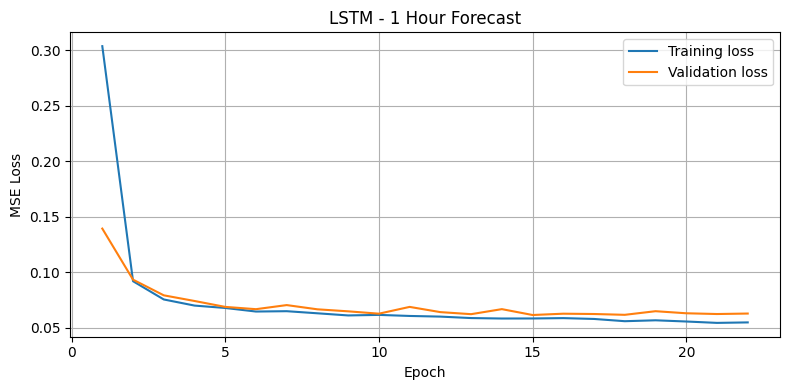

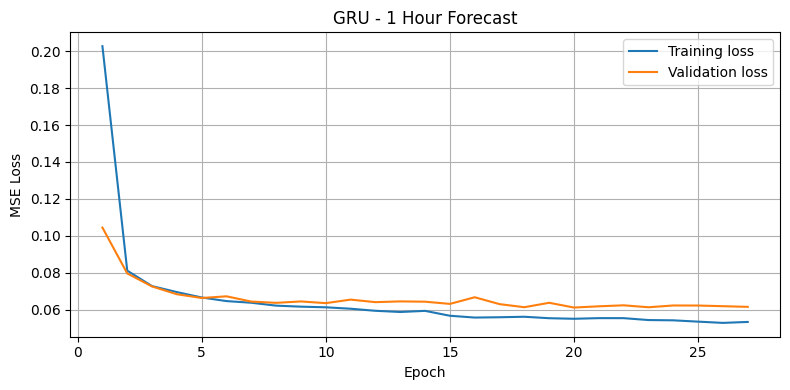

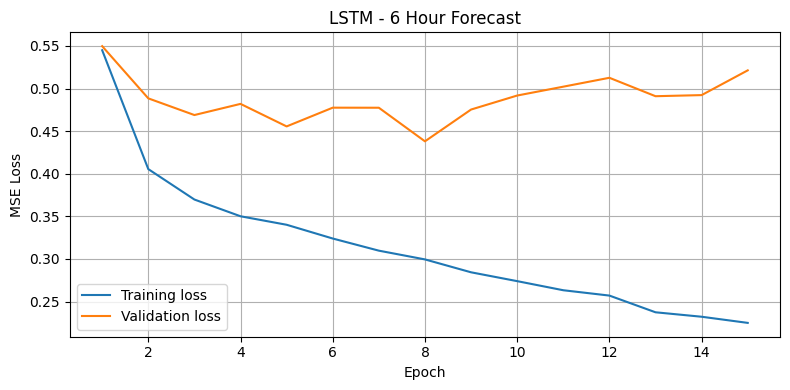

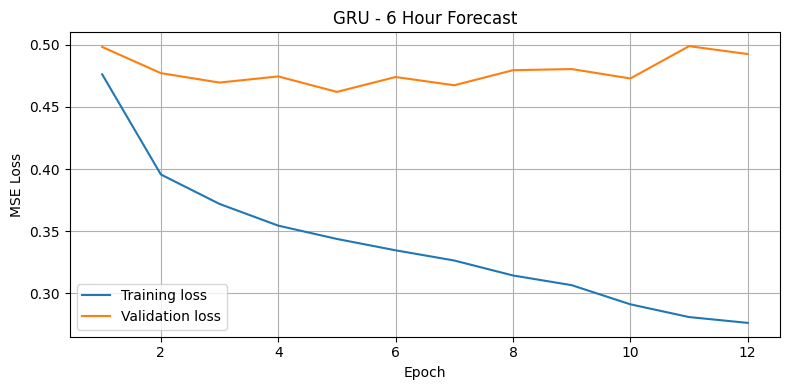

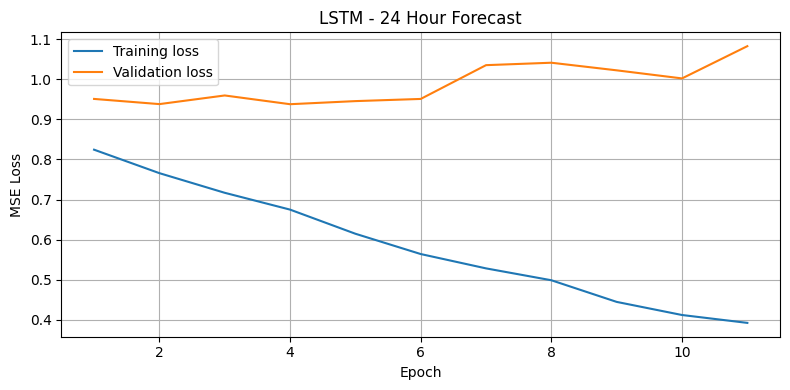

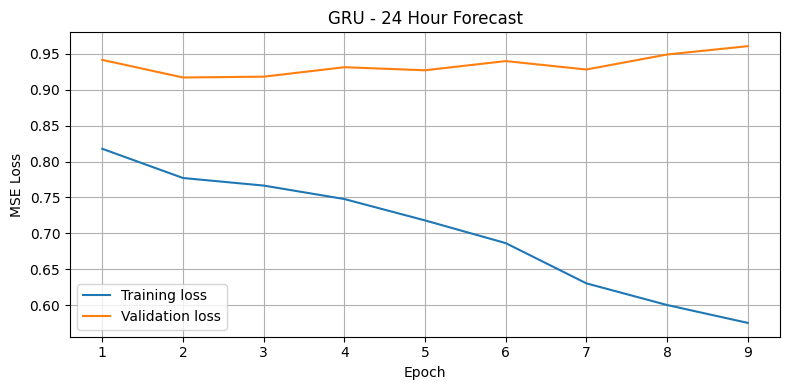

In [ ]:

import matplotlib.pyplot as plt

for key, history in training_histories.items():

    model_name, horizon = key

    plt.figure(figsize=(8, 4))

    plt.plot(history["epoch"], history["train_loss"], label="Training loss")
    plt.plot(history["epoch"], history["val_loss"], label="Validation loss")

    plt.title(f"{model_name} - {horizon} Hour Forecast")
    plt.xlabel("Epoch")
    plt.ylabel("MSE Loss")

    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    plt.show()


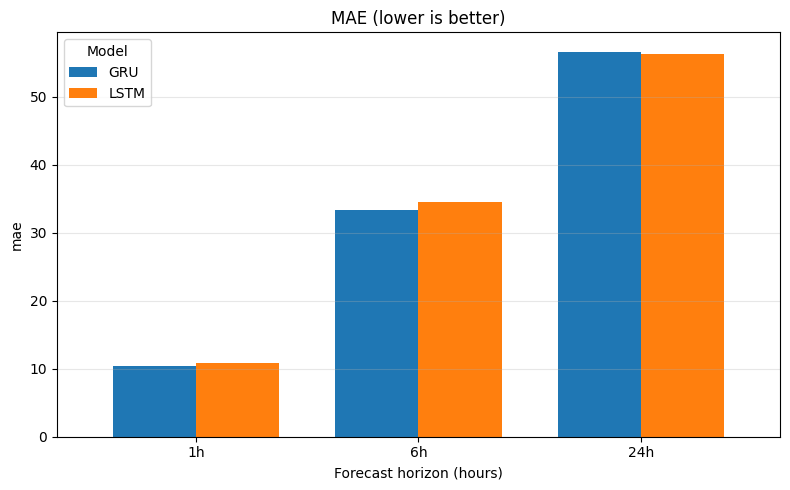

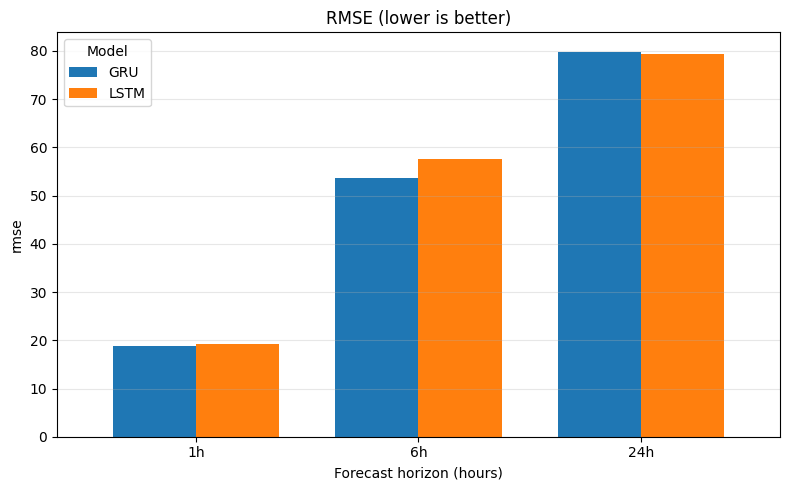

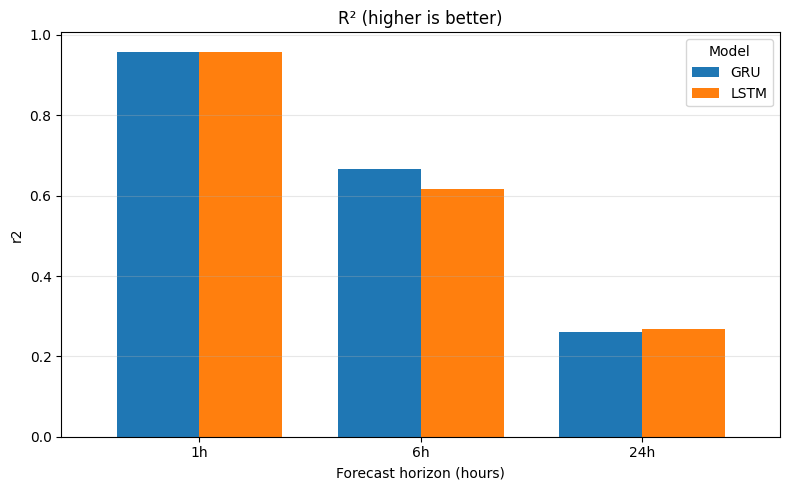

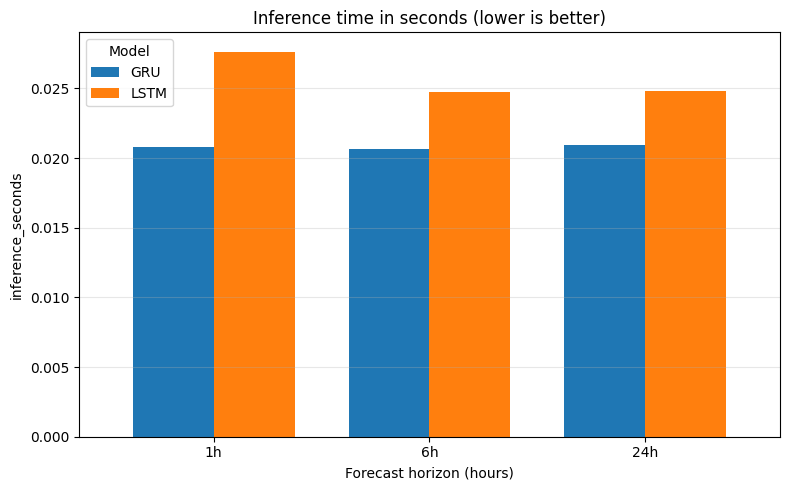

All comparison charts saved in: /content/drive/MyDrive/AeroSense_AI/results/deep_learning
Files:
mae_comparison.png
rmse_comparison.png
r2_comparison.png
inference_seconds_comparison.png


In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt

RESULTS_DIR = f"{PROJECT_DIR}/results/deep_learning"
os.makedirs(RESULTS_DIR, exist_ok=True)

results_df = pd.read_csv(
    f"{RESULTS_DIR}/lstm_gru_comparison.csv"
)

metrics = [
    ("mae", "MAE (lower is better)"),
    ("rmse", "RMSE (lower is better)"),
    ("r2", "R² (higher is better)"),
    ("inference_seconds", "Inference time in seconds (lower is better)")
]

for metric, title in metrics:
    pivot = results_df.pivot(
        index="horizon_hours",
        columns="model",
        values=metric
    )

    ax = pivot.plot(
        kind="bar",
        figsize=(8, 5),
        width=0.75
    )

    ax.set_title(title)
    ax.set_xlabel("Forecast horizon (hours)")
    ax.set_ylabel(metric)
    ax.set_xticklabels(
        [f"{int(x)}h" for x in pivot.index],
        rotation=0
    )
    ax.legend(title="Model")
    ax.grid(axis="y", alpha=0.3)

    plt.tight_layout()

    filename = f"{metric}_comparison.png"
    plt.savefig(
        os.path.join(RESULTS_DIR, filename),
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

print("All comparison charts saved in:", RESULTS_DIR)
print("Files:")
for filename in os.listdir(RESULTS_DIR):
    if filename.endswith(".png"):
        print(filename)

In [ ]:

import time
import numpy as np
import pandas as pd

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

comparison_rows = []

# Use the same input windows and target splits as LSTM and GRU.
for horizon in HORIZONS:
    data = datasets[horizon]

    X_train = data["X_train"]
    y_train = data["y_train"]
    X_test = data["X_test"]
    y_test = data["y_test"]

    # Flatten each 24-hour sequence into one feature vector.
    X_train_flat = X_train.reshape(len(X_train), -1)
    X_test_flat = X_test.reshape(len(X_test), -1)

    model = ExtraTreesRegressor(
        n_estimators=300,
        max_features=1.0,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train_flat, y_train)

    start_time = time.perf_counter()
    predictions_scaled = model.predict(X_test_flat)
    inference_seconds = time.perf_counter() - start_time

    # Convert predictions and actual values back to PM2.5 units.
    predictions = target_scaler.inverse_transform(
        predictions_scaled.reshape(-1, 1)
    ).ravel()

    actual = target_scaler.inverse_transform(
        y_test.reshape(-1, 1)
    ).ravel()

    mae = mean_absolute_error(actual, predictions)
    rmse = np.sqrt(mean_squared_error(actual, predictions))
    r2 = r2_score(actual, predictions)

    comparison_rows.append({
        "model": "ExtraTrees",
        "horizon_hours": horizon,
        "mae": mae,
        "rmse": rmse,
        "r2": r2,
        "inference_seconds": inference_seconds,
        "test_samples": len(actual)
    })

    print(f"\nExtraTrees — {horizon}-hour forecast")
    print(f"MAE: {mae:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"R2: {r2:.4f}")

# Save results.
extra_trees_results = pd.DataFrame(comparison_rows)

output_path = (
    f"{PROJECT_DIR}/results/deep_learning/"
    "extratrees_single_station_comparison.csv"
)

extra_trees_results.to_csv(output_path, index=False)

display(extra_trees_results)

print("\nResults saved:", output_path)



ExtraTrees — 1-hour forecast
MAE: 10.6361
RMSE: 20.1561
R2: 0.9530

ExtraTrees — 6-hour forecast
MAE: 33.6312
RMSE: 56.1048
R2: 0.6356

ExtraTrees — 24-hour forecast
MAE: 58.0738
RMSE: 82.2325
R2: 0.2172


,model,horizon_hours,mae,rmse,r2,inference_seconds,test_samples
0,ExtraTrees,1,10.636062,20.156101,0.952969,0.359711,5260
1,ExtraTrees,6,33.631183,56.104838,0.635603,0.523005,5260
2,ExtraTrees,24,58.073844,82.232492,0.217181,0.255398,5260



Results saved: /content/drive/MyDrive/AeroSense_AI/results/deep_learning/extratrees_single_station_comparison.csv


,model,horizon_hours,mae,rmse,r2,inference_seconds,test_samples
0,ExtraTrees,1,10.6361,20.1561,0.9530,0.3597,5260
1,GRU,1,10.3673,18.8974,0.9587,0.0208,5260
2,LSTM,1,10.8265,19.2524,0.9571,0.0276,5260
3,ExtraTrees,6,33.6312,56.1048,0.6356,0.5230,5260
4,GRU,6,33.3929,53.6612,0.6667,0.0207,5260
5,LSTM,6,34.5354,57.5575,0.6165,0.0248,5260
6,ExtraTrees,24,58.0738,82.2325,0.2172,0.2554,5260
7,GRU,24,56.6702,79.8739,0.2614,0.0209,5260
8,LSTM,24,56.3465,79.4453,0.2693,0.0248,5260


Combined results saved: /content/drive/MyDrive/AeroSense_AI/results/deep_learning/all_models_comparison.csv


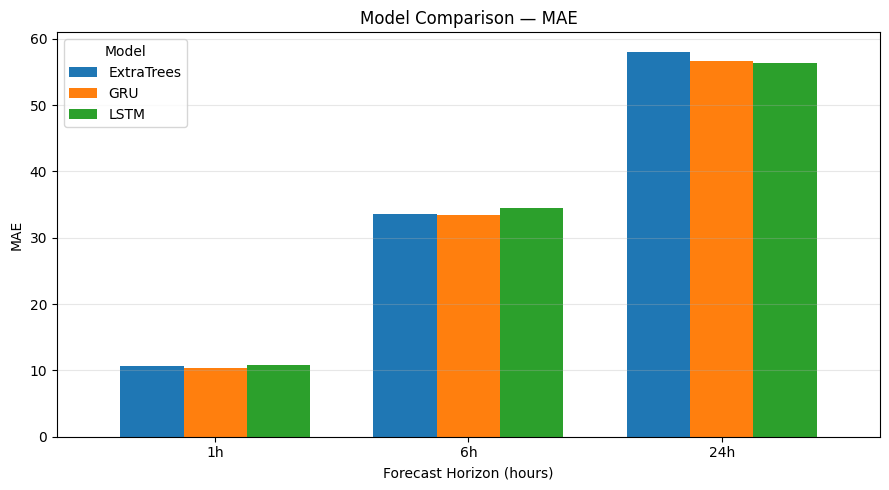

Chart saved: /content/drive/MyDrive/AeroSense_AI/results/deep_learning/mae_comparison.png


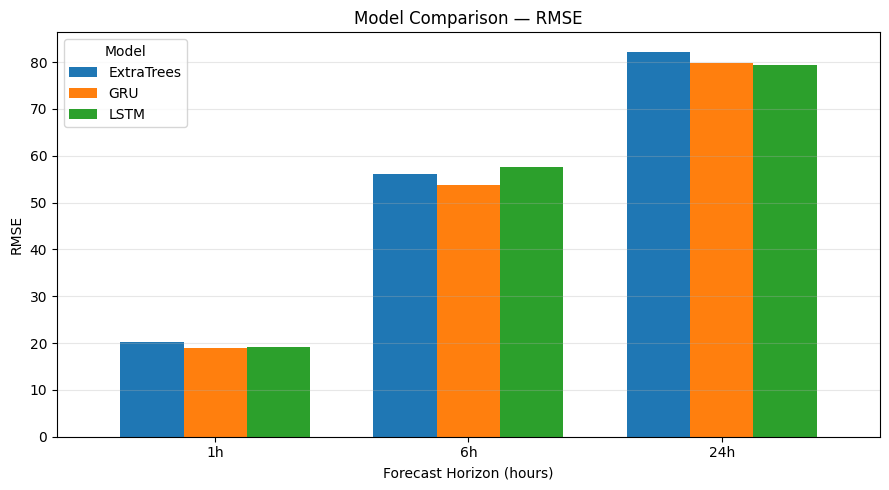

Chart saved: /content/drive/MyDrive/AeroSense_AI/results/deep_learning/rmse_comparison.png


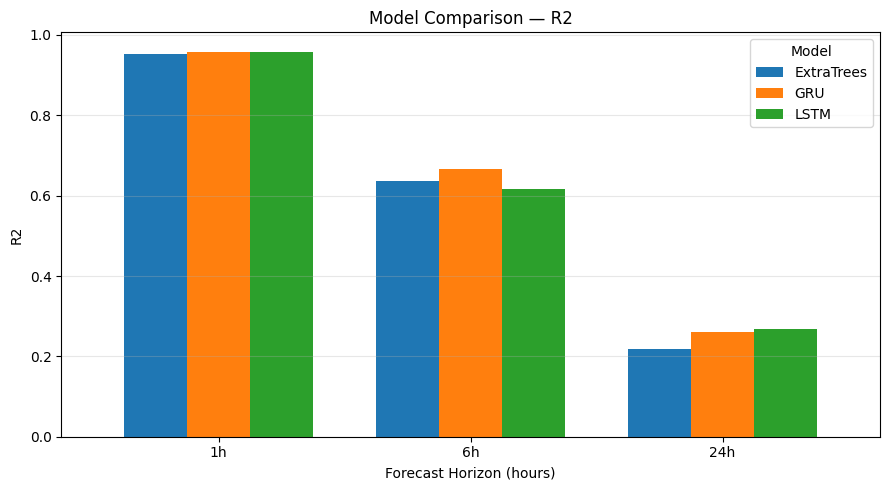

Chart saved: /content/drive/MyDrive/AeroSense_AI/results/deep_learning/r2_comparison.png

Three-model comparison completed successfully.


In [ ]:

import os
import pandas as pd
import matplotlib.pyplot as plt

RESULTS_DIR = f"{PROJECT_DIR}/results/deep_learning"
os.makedirs(RESULTS_DIR, exist_ok=True)

# Load the saved deep-learning results and ExtraTrees results.
dl_path = f"{RESULTS_DIR}/lstm_gru_comparison.csv"
et_path = f"{RESULTS_DIR}/extratrees_single_station_comparison.csv"

dl_results = pd.read_csv(dl_path)
et_results = pd.read_csv(et_path)

# Combine all three models.
combined_results = pd.concat(
    [dl_results, et_results],
    ignore_index=True
)

combined_results = combined_results.sort_values(
    ["horizon_hours", "model"]
).reset_index(drop=True)

# Display and save the combined table.
display(combined_results.round(4))

combined_path = f"{RESULTS_DIR}/all_models_comparison.csv"
combined_results.to_csv(combined_path, index=False)

print("Combined results saved:", combined_path)

# Generate one comparison chart for each metric.
metrics = ["mae", "rmse", "r2"]

for metric in metrics:
    pivot = combined_results.pivot(
        index="horizon_hours",
        columns="model",
        values=metric
    )

    ax = pivot.plot(
        kind="bar",
        figsize=(9, 5),
        width=0.75
    )

    ax.set_title(f"Model Comparison — {metric.upper()}")
    ax.set_xlabel("Forecast Horizon (hours)")
    ax.set_ylabel(metric.upper())
    ax.set_xticklabels(
        [f"{int(x)}h" for x in pivot.index],
        rotation=0
    )
    ax.legend(title="Model")
    ax.grid(axis="y", alpha=0.3)

    plt.tight_layout()

    chart_path = f"{RESULTS_DIR}/{metric}_comparison.png"
    plt.savefig(chart_path, dpi=300, bbox_inches="tight")
    plt.show()

    print("Chart saved:", chart_path)

print("\nThree-model comparison completed successfully.")


In [ ]:

import os
import time
import numpy as np
import pandas as pd

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# --------------------------------------------------
# 1. Load the complete 12-station dataset
# --------------------------------------------------

df_all = pd.read_parquet(DATA_PATH)

df_all["timestamp"] = pd.to_datetime(df_all["timestamp"])
df_all = df_all.sort_values(
    ["station", "timestamp"]
).reset_index(drop=True)

print("Dataset shape:", df_all.shape)
print("Number of stations:", df_all["station"].nunique())

# --------------------------------------------------
# 2. Create features using past observations
# --------------------------------------------------

numeric_features = [
    "PM2.5", "PM10", "SO2", "NO2", "CO", "O3",
    "TEMP", "PRES", "DEWP", "RAIN", "WSPM"
]

feature_frames = []

for station, group in df_all.groupby("station"):
    group = group.sort_values("timestamp").copy()

    # Historical PM2.5 values
    for lag in [1, 3, 6, 12, 24, 48, 168]:
        group[f"PM25_lag_{lag}"] = group["PM2.5"].shift(lag)

    # Rolling statistics using past observations only
    for window in [3, 6, 24, 168]:
        group[f"PM25_roll_mean_{window}"] = (
            group["PM2.5"].shift(1).rolling(window).mean()
        )
        group[f"PM25_roll_std_{window}"] = (
            group["PM2.5"].shift(1).rolling(window).std()
        )

    # Time features
    group["hour_sin"] = np.sin(
        2 * np.pi * group["timestamp"].dt.hour / 24
    )
    group["hour_cos"] = np.cos(
        2 * np.pi * group["timestamp"].dt.hour / 24
    )
    group["month_sin"] = np.sin(
        2 * np.pi * group["timestamp"].dt.month / 12
    )
    group["month_cos"] = np.cos(
        2 * np.pi * group["timestamp"].dt.month / 12
    )

    feature_frames.append(group)

feature_df = pd.concat(
    feature_frames, ignore_index=True
)

# Do not use station identity as a feature:
# the test station is intentionally unseen.
feature_columns = (
    numeric_features
    + [f"PM25_lag_{lag}" for lag in [1, 3, 6, 12, 24, 48, 168]]
    + [
        f"PM25_roll_mean_{w}" for w in [3, 6, 24, 168]
    ]
    + [
        f"PM25_roll_std_{w}" for w in [3, 6, 24, 168]
    ]
    + ["hour_sin", "hour_cos", "month_sin", "month_cos"]
)

print("Number of model features:", len(feature_columns))
print("Feature preparation complete.")

# --------------------------------------------------
# 3. Define chronological training and test periods
# --------------------------------------------------

all_timestamps = np.sort(
    feature_df["timestamp"].dropna().unique()
)

train_end = pd.Timestamp(
    all_timestamps[int(len(all_timestamps) * 0.70)]
)

test_start = pd.Timestamp(
    all_timestamps[int(len(all_timestamps) * 0.85)]
)

print("Training period ends:", train_end)
print("Testing period starts:", test_start)

# --------------------------------------------------
# 4. Leave-one-station-out experiment
# --------------------------------------------------

stations = sorted(feature_df["station"].unique())
horizons = [1, 6, 24]

transfer_results = []

for held_out_station in stations:

    print("\n" + "=" * 55)
    print("HELD-OUT STATION:", held_out_station)
    print("=" * 55)

    for horizon in horizons:

        experiment_df = feature_df.copy()

        # Forecast target h hours after the observation time.
        experiment_df["target_pm25"] = (
            experiment_df.groupby("station")["PM2.5"]
            .shift(-horizon)
        )

        experiment_df["target_timestamp"] = (
            experiment_df.groupby("station")["timestamp"]
            .shift(-horizon)
        )

        # Training: other 11 stations, first 70% of time.
        train_mask = (
            (experiment_df["station"] != held_out_station)
            & (experiment_df["timestamp"] < train_end)
            & (experiment_df["target_timestamp"] < train_end)
        )

        # Testing: held-out station, final 15% of time.
        test_mask = (
            (experiment_df["station"] == held_out_station)
            & (experiment_df["timestamp"] >= test_start)
            & experiment_df["target_timestamp"].notna()
        )

        train_data = experiment_df.loc[
            train_mask, feature_columns + ["target_pm25"]
        ].dropna(subset=["target_pm25"])

        test_data = experiment_df.loc[
            test_mask, feature_columns + ["target_pm25"]
        ].dropna(subset=["target_pm25"])

        if len(train_data) == 0 or len(test_data) == 0:
            print("Skipping:", held_out_station, horizon)
            continue

        X_train = train_data[feature_columns]
        y_train = train_data["target_pm25"]

        X_test = test_data[feature_columns]
        y_test = test_data["target_pm25"]

        # Fit imputation only on training stations.
        imputer = SimpleImputer(strategy="median")

        X_train = imputer.fit_transform(X_train)
        X_test = imputer.transform(X_test)

        model = ExtraTreesRegressor(
            n_estimators=100,
            min_samples_leaf=2,
            max_features=1.0,
            random_state=42,
            n_jobs=-1
        )

        model.fit(X_train, y_train)

        start_time = time.perf_counter()
        predictions = model.predict(X_test)
        inference_seconds = time.perf_counter() - start_time

        mae = mean_absolute_error(y_test, predictions)
        rmse = np.sqrt(
            mean_squared_error(y_test, predictions)
        )
        r2 = r2_score(y_test, predictions)

        transfer_results.append({
            "held_out_station": held_out_station,
            "model": "ExtraTrees",
            "horizon_hours": horizon,
            "mae": mae,
            "rmse": rmse,
            "r2": r2,
            "inference_seconds": inference_seconds,
            "train_samples": len(y_train),
            "test_samples": len(y_test)
        })

        print(
            f"{horizon}h | MAE: {mae:.3f} | "
            f"RMSE: {rmse:.3f} | R2: {r2:.3f} | "
            f"Test samples: {len(y_test)}"
        )

# --------------------------------------------------
# 5. Save station-level results
# --------------------------------------------------

transfer_df = pd.DataFrame(transfer_results)

output_dir = f"{PROJECT_DIR}/results/transferability"
os.makedirs(output_dir, exist_ok=True)

station_results_path = (
    f"{output_dir}/extratrees_leave_one_station_out.csv"
)

transfer_df.to_csv(station_results_path, index=False)

print("\nStation-level transferability results:")
display(transfer_df.round(4))

print("Saved:", station_results_path)

# --------------------------------------------------
# 6. Calculate average performance by horizon
# --------------------------------------------------

summary = (
    transfer_df.groupby(["model", "horizon_hours"])
    .agg(
        mean_mae=("mae", "mean"),
        std_mae=("mae", "std"),
        mean_rmse=("rmse", "mean"),
        mean_r2=("r2", "mean"),
        stations_evaluated=("held_out_station", "nunique")
    )
    .reset_index()
)

summary_path = f"{output_dir}/transferability_summary.csv"
summary.to_csv(summary_path, index=False)

print("\nOVERALL TRANSFERABILITY SUMMARY:")
display(summary.round(4))

print("Summary saved:", summary_path)


Dataset shape: (420768, 14)
Number of stations: 12
Number of model features: 30
Feature preparation complete.
Training period ends: 2015-12-18 16:00:00
Testing period starts: 2016-07-24 20:00:00

HELD-OUT STATION: Aotizhongxin
1h | MAE: 10.433 | RMSE: 19.188 | R2: 0.958 | Test samples: 5172
6h | MAE: 33.623 | RMSE: 56.529 | R2: 0.634 | Test samples: 5167
24h | MAE: 60.736 | RMSE: 86.745 | R2: 0.141 | Test samples: 5153

HELD-OUT STATION: Changping
1h | MAE: 10.072 | RMSE: 18.826 | R2: 0.946 | Test samples: 5200
6h | MAE: 28.392 | RMSE: 48.694 | R2: 0.637 | Test samples: 5195
24h | MAE: 51.464 | RMSE: 74.813 | R2: 0.146 | Test samples: 5177

HELD-OUT STATION: Dingling
1h | MAE: 8.696 | RMSE: 17.198 | R2: 0.945 | Test samples: 5044
6h | MAE: 26.394 | RMSE: 44.628 | R2: 0.629 | Test samples: 5039
24h | MAE: 48.859 | RMSE: 67.487 | R2: 0.154 | Test samples: 5021

HELD-OUT STATION: Dongsi
1h | MAE: 11.019 | RMSE: 22.045 | R2: 0.954 | Test samples: 5082
6h | MAE: 37.039 | RMSE: 62.416 | R2: 

,held_out_station,model,horizon_hours,mae,rmse,r2,inference_seconds,train_samples,test_samples
0,Aotizhongxin,ExtraTrees,1,10.4333,19.1883,0.9578,0.3852,264544,5172
1,Aotizhongxin,ExtraTrees,6,33.6229,56.5290,0.6343,0.2010,264489,5167
2,Aotizhongxin,ExtraTrees,24,60.7356,86.7454,0.1407,0.2479,264291,5153
3,Changping,ExtraTrees,1,10.0720,18.8263,0.9458,0.3953,264455,5200
4,Changping,ExtraTrees,6,28.3921,48.6939,0.6374,0.3451,264400,5195
5,Changping,ExtraTrees,24,51.4636,74.8135,0.1464,0.1467,264202,5177
6,Dingling,ExtraTrees,1,8.6960,17.1984,0.9448,0.1982,264275,5044
7,Dingling,ExtraTrees,6,26.3945,44.6278,0.6289,0.3098,264220,5039
8,Dingling,ExtraTrees,24,48.8594,67.4870,0.1537,0.1479,264022,5021
9,Dongsi,ExtraTrees,1,11.0190,22.0446,0.9537,0.2199,264179,5082


Saved: /content/drive/MyDrive/AeroSense_AI/results/transferability/extratrees_leave_one_station_out.csv

OVERALL TRANSFERABILITY SUMMARY:


,model,horizon_hours,mean_mae,std_mae,mean_rmse,mean_r2,stations_evaluated
0,ExtraTrees,1,10.1568,0.8626,20.0400,0.9518,12
1,ExtraTrees,6,32.8329,3.5782,55.4903,0.6339,12
2,ExtraTrees,24,58.7354,5.5624,85.6195,0.1313,12


Summary saved: /content/drive/MyDrive/AeroSense_AI/results/transferability/transferability_summary.csv


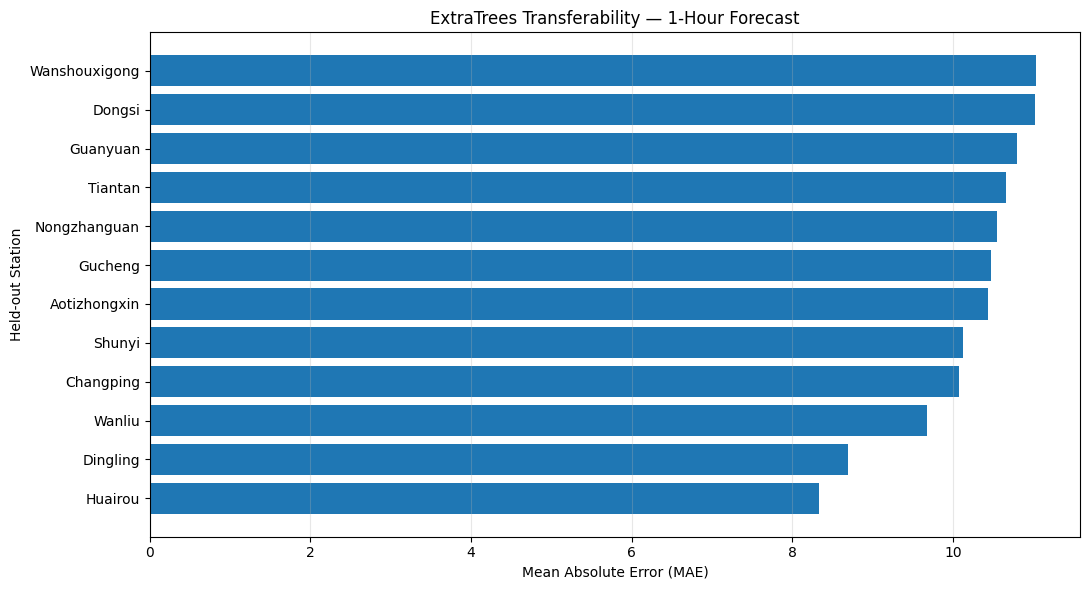

Saved: /content/drive/MyDrive/AeroSense_AI/results/transferability/station_mae_1h.png


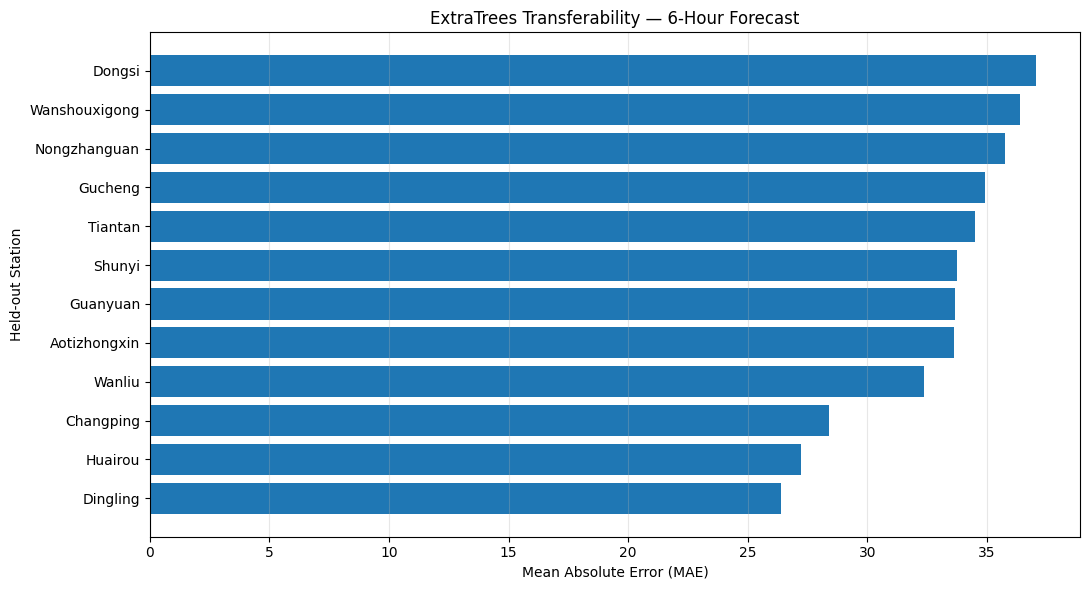

Saved: /content/drive/MyDrive/AeroSense_AI/results/transferability/station_mae_6h.png


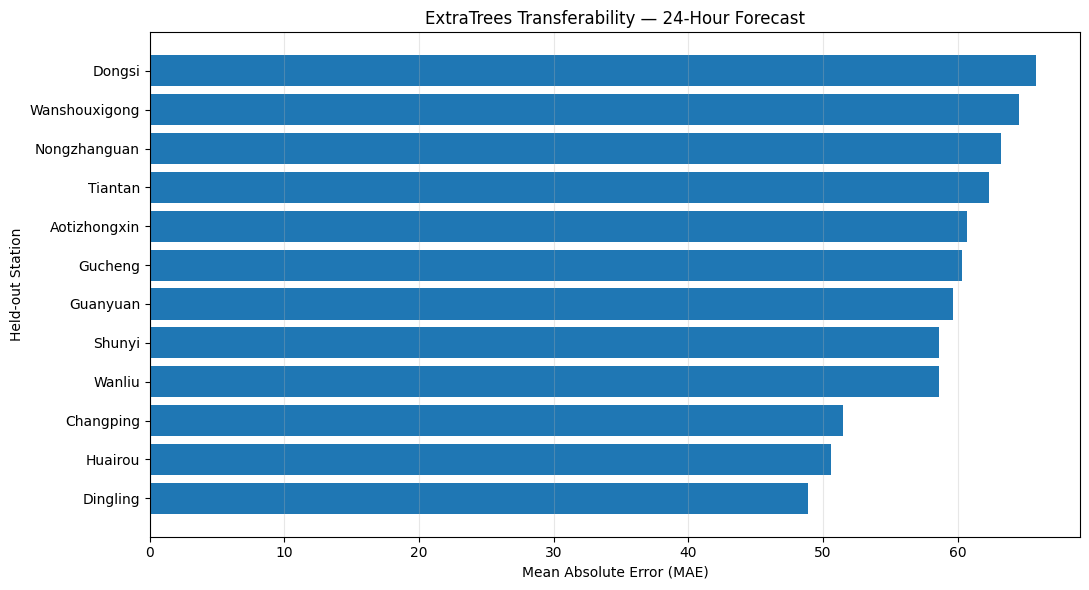

Saved: /content/drive/MyDrive/AeroSense_AI/results/transferability/station_mae_24h.png
All station-wise charts generated.


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import os

RESULTS_DIR = f"{PROJECT_DIR}/results/transferability"

results = pd.read_csv(
    f"{RESULTS_DIR}/extratrees_leave_one_station_out.csv"
)

for horizon in [1, 6, 24]:

    subset = results[
        results["horizon_hours"] == horizon
    ].sort_values("mae")

    plt.figure(figsize=(11, 6))

    plt.barh(
        subset["held_out_station"],
        subset["mae"]
    )

    plt.xlabel("Mean Absolute Error (MAE)")
    plt.ylabel("Held-out Station")
    plt.title(
        f"ExtraTrees Transferability — {horizon}-Hour Forecast"
    )

    plt.grid(axis="x", alpha=0.3)
    plt.tight_layout()

    chart_path = (
        f"{RESULTS_DIR}/station_mae_{horizon}h.png"
    )

    plt.savefig(chart_path, dpi=300, bbox_inches="tight")
    plt.show()

    print("Saved:", chart_path)

print("All station-wise charts generated.")


In [ ]:

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import time
import os
import random

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from torch.utils.data import TensorDataset, DataLoader

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

# Load dataset
df_transfer = pd.read_parquet(DATA_PATH)

df_transfer["timestamp"] = pd.to_datetime(
    df_transfer["timestamp"]
)

df_transfer = df_transfer.sort_values(
    ["station", "timestamp"]
).reset_index(drop=True)

# Select the held-out station for our pilot
HELD_OUT_STATION = "Aotizhongxin"

LOOKBACK = 24
HORIZONS = [1, 6, 24]

features = [
    "PM2.5", "PM10", "SO2", "NO2", "CO", "O3",
    "TEMP", "PRES", "DEWP", "RAIN", "WSPM"
]

# Global chronological boundaries
all_times = np.sort(df_transfer["timestamp"].unique())

train_end = pd.Timestamp(
    all_times[int(len(all_times) * 0.70)]
)

test_start = pd.Timestamp(
    all_times[int(len(all_times) * 0.85)]
)

# Separate training and held-out stations
train_df = df_transfer[
    (df_transfer["station"] != HELD_OUT_STATION)
    & (df_transfer["timestamp"] < train_end)
].copy()

test_df = df_transfer[
    (df_transfer["station"] == HELD_OUT_STATION)
    & (df_transfer["timestamp"] >= test_start)
].copy()

# Fit scalers ONLY on training stations and training period
feature_scaler_transfer = StandardScaler()
target_scaler_transfer = StandardScaler()

feature_scaler_transfer.fit(
    train_df[features].ffill().fillna(0)
)

target_scaler_transfer.fit(
    train_df[["PM2.5"]].dropna()
)

print("Training stations:", train_df["station"].nunique())
print("Held-out station:", HELD_OUT_STATION)
print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))
print("Training ends:", train_end)
print("Testing starts:", test_start)
print("Feature count:", len(features))


Device: cuda
Training stations: 11
Held-out station: Aotizhongxin
Training rows: 269984
Testing rows: 5260
Training ends: 2015-12-18 16:00:00
Testing starts: 2016-07-24 20:00:00
Feature count: 11


In [ ]:

# STEP 2: Prepare leakage-controlled sequences

VALIDATION_START = pd.Timestamp(
    all_times[int(len(all_times) * 0.60)]
)

# Calculate imputation values from training stations and training period only.
training_raw = df_transfer[
    (df_transfer["station"] != HELD_OUT_STATION)
    & (df_transfer["timestamp"] < VALIDATION_START)
].copy()

training_raw = training_raw.sort_values(
    ["station", "timestamp"]
)

training_filled = (
    training_raw.groupby("station")[features]
    .transform(lambda x: x.ffill())
)

feature_medians = training_filled.median()

# Fit scalers only on the training period.
feature_scaler_transfer = StandardScaler()
target_scaler_transfer = StandardScaler()

training_filled = training_filled.fillna(feature_medians)

feature_scaler_transfer.fit(training_filled)

target_training_values = training_raw["PM2.5"].dropna()

target_scaler_transfer.fit(
    target_training_values.to_numpy().reshape(-1, 1)
)

print("Validation starts:", VALIDATION_START)
print("Feature scaler fitted on training period only.")

# Prepare station-specific arrays.
station_arrays = {}

for station, group in df_transfer.groupby("station"):

    group = group.sort_values("timestamp").reset_index(drop=True)

    X_raw = group[features].ffill().fillna(feature_medians)

    X_scaled = feature_scaler_transfer.transform(X_raw)

    y_raw = group["PM2.5"].to_numpy(dtype=np.float32)

    y_scaled = target_scaler_transfer.transform(
        np.nan_to_num(
            y_raw,
            nan=float(target_training_values.median())
        ).reshape(-1, 1)
    ).ravel()

    timestamps = pd.to_datetime(
        group["timestamp"]
    ).to_numpy()

    station_arrays[station] = {
        "X": X_scaled.astype(np.float32),
        "y": y_scaled.astype(np.float32),
        "y_raw": y_raw,
        "timestamps": timestamps
    }

print("Prepared stations:", len(station_arrays))

# Build sequences separately for each station.
def build_station_sequences(station_data, horizon):

    X = station_data["X"]
    y = station_data["y"]
    y_raw = station_data["y_raw"]
    timestamps = station_data["timestamps"]

    n = len(X)

    # Each window ends at the forecast origin.
    windows = np.lib.stride_tricks.sliding_window_view(
        X, window_shape=LOOKBACK, axis=0
    ).transpose(0, 2, 1)

    origins = np.arange(LOOKBACK - 1, n - horizon)
    target_indices = origins + horizon

    windows = windows[:len(origins)]

    target_times = timestamps[target_indices]
    target_values = y[target_indices]
    target_raw = y_raw[target_indices]

    valid = np.isfinite(target_values) & np.isfinite(target_raw)

    return (
        windows[valid].astype(np.float32),
        target_values[valid].astype(np.float32),
        target_raw[valid].astype(np.float32),
        target_times[valid]
    )

# Assemble datasets for each forecast horizon.
transfer_datasets = {}

for horizon in HORIZONS:

    train_X_parts, train_y_parts = [], []
    val_X_parts, val_y_parts = [], []
    test_X_parts, test_y_parts, test_raw_parts = [], [], []

    for station, station_data in station_arrays.items():

        X_seq, y_seq, y_raw, target_times = (
            build_station_sequences(station_data, horizon)
        )

        if station == HELD_OUT_STATION:
            # Only the held-out station contributes test samples.
            test_mask = (
                target_times >= np.datetime64(test_start)
            )

            test_X_parts.append(X_seq[test_mask])
            test_y_parts.append(y_seq[test_mask])
            test_raw_parts.append(y_raw[test_mask])

        else:
            train_mask = (
                target_times < np.datetime64(VALIDATION_START)
            )

            val_mask = (
                (target_times >= np.datetime64(VALIDATION_START))
                & (target_times < np.datetime64(train_end))
            )

            train_X_parts.append(X_seq[train_mask])
            train_y_parts.append(y_seq[train_mask])

            val_X_parts.append(X_seq[val_mask])
            val_y_parts.append(y_seq[val_mask])

    transfer_datasets[horizon] = {
        "X_train": np.concatenate(train_X_parts),
        "y_train": np.concatenate(train_y_parts),
        "X_val": np.concatenate(val_X_parts),
        "y_val": np.concatenate(val_y_parts),
        "X_test": np.concatenate(test_X_parts),
        "y_test": np.concatenate(test_y_parts),
        "y_test_raw": np.concatenate(test_raw_parts)
    }

    data = transfer_datasets[horizon]

    print(f"\n{horizon}-hour horizon")
    print("Training sequences:", data["X_train"].shape)
    print("Validation sequences:", data["X_val"].shape)
    print("Testing sequences:", data["X_test"].shape)

print("\nSequence preparation completed.")


Validation starts: 2015-07-25 14:00:00
Feature scaler fitted on training period only.
Prepared stations: 12

1-hour horizon
Training sequences: (226706, 24, 11)
Validation sequences: (37585, 24, 11)
Testing sequences: (5173, 24, 11)

6-hour horizon
Training sequences: (226651, 24, 11)
Validation sequences: (37585, 24, 11)
Testing sequences: (5173, 24, 11)

24-hour horizon
Training sequences: (226453, 24, 11)
Validation sequences: (37585, 24, 11)
Testing sequences: (5173, 24, 11)

Sequence preparation completed.


In [ ]:

# STEP 3: LSTM and GRU transferability pilot

from torch.utils.data import TensorDataset, DataLoader
import copy
import gc

# Reproducibility
torch.manual_seed(SEED)
np.random.seed(SEED)

# Model definitions
class TransferLSTM(nn.Module):
    def __init__(self, input_size, hidden_size=64):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=2,
            batch_first=True,
            dropout=0.2
        )
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        output, _ = self.lstm(x)
        return self.fc(output[:, -1, :]).squeeze(-1)


class TransferGRU(nn.Module):
    def __init__(self, input_size, hidden_size=64):
        super().__init__()
        self.gru = nn.GRU(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=2,
            batch_first=True,
            dropout=0.2
        )
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        output, _ = self.gru(x)
        return self.fc(output[:, -1, :]).squeeze(-1)


# Training function with early stopping
def train_transfer_model(
    model,
    train_loader,
    val_loader,
    epochs=40,
    patience=7
):
    model = model.to(DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001,
        weight_decay=1e-5
    )

    criterion = nn.MSELoss()

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=3
    )

    best_val_loss = float("inf")
    best_weights = None
    patience_counter = 0

    history = {"train_loss": [], "val_loss": []}

    for epoch in range(epochs):

        model.train()
        train_losses = []

        for xb, yb in train_loader:
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)

            optimizer.zero_grad()

            predictions = model(xb)
            loss = criterion(predictions, yb)

            loss.backward()
            torch.nn.utils.clip_grad_norm_(
                model.parameters(), max_norm=1.0
            )
            optimizer.step()

            train_losses.append(loss.item())

        model.eval()
        val_losses = []

        with torch.no_grad():
            for xb, yb in val_loader:
                xb = xb.to(DEVICE)
                yb = yb.to(DEVICE)

                predictions = model(xb)
                loss = criterion(predictions, yb)

                val_losses.append(loss.item())

        train_loss = float(np.mean(train_losses))
        val_loss = float(np.mean(val_losses))

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        scheduler.step(val_loss)

        print(
            f"Epoch {epoch+1:02d}/{epochs} | "
            f"Train: {train_loss:.5f} | "
            f"Validation: {val_loss:.5f}"
        )

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_weights = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1

        if patience_counter >= patience:
            print("Early stopping triggered.")
            break

    if best_weights is not None:
        model.load_state_dict(best_weights)

    return model, history


# Output folders
MODEL_DIR = f"{PROJECT_DIR}/models/transferability"
RESULT_DIR = f"{PROJECT_DIR}/results/transferability"

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

transfer_models = {}
transfer_histories = {}
transfer_dl_results = []

BATCH_SIZE = 512

# Train both architectures for all horizons
for horizon in HORIZONS:

    print("\n" + "=" * 65)
    print(f"FORECAST HORIZON: {horizon} HOURS")
    print("=" * 65)

    data = transfer_datasets[horizon]

    train_dataset = TensorDataset(
        torch.from_numpy(data["X_train"]),
        torch.from_numpy(data["y_train"])
    )

    val_dataset = TensorDataset(
        torch.from_numpy(data["X_val"]),
        torch.from_numpy(data["y_val"])
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        pin_memory=(DEVICE.type == "cuda")
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        pin_memory=(DEVICE.type == "cuda")
    )

    for model_name, ModelClass in [
        ("LSTM", TransferLSTM),
        ("GRU", TransferGRU)
    ]:

        print(f"\nTraining {model_name} — {horizon}h")

        model = ModelClass(
            input_size=len(features)
        )

        trained_model, history = train_transfer_model(
            model,
            train_loader,
            val_loader,
            epochs=40,
            patience=7
        )

        key = (model_name, horizon)

        transfer_models[key] = trained_model
        transfer_histories[key] = history

        model_path = (
            f"{MODEL_DIR}/{model_name.lower()}_"
            f"{horizon}h_{HELD_OUT_STATION}.pth"
        )

        torch.save(
            {
                "model_state_dict": trained_model.state_dict(),
                "model_name": model_name,
                "horizon_hours": horizon,
                "held_out_station": HELD_OUT_STATION,
                "features": features,
                "lookback": LOOKBACK,
                "best_validation_loss": min(history["val_loss"])
            },
            model_path
        )

        print("Model saved:", model_path)

        del model, trained_model
        gc.collect()

        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()

print("\nAll six pilot models trained and saved.")



FORECAST HORIZON: 1 HOURS

Training LSTM — 1h
Epoch 01/40 | Train: 0.12488 | Validation: 0.05209
Epoch 02/40 | Train: 0.06266 | Validation: 0.04760
Epoch 03/40 | Train: 0.05963 | Validation: 0.04699
Epoch 04/40 | Train: 0.05848 | Validation: 0.04570
Epoch 05/40 | Train: 0.05716 | Validation: 0.04351
Epoch 06/40 | Train: 0.05637 | Validation: 0.04310
Epoch 07/40 | Train: 0.05578 | Validation: 0.04367
Epoch 08/40 | Train: 0.05511 | Validation: 0.04440
Epoch 09/40 | Train: 0.05449 | Validation: 0.04448
Epoch 10/40 | Train: 0.05388 | Validation: 0.04383
Epoch 11/40 | Train: 0.05275 | Validation: 0.04337
Epoch 12/40 | Train: 0.05259 | Validation: 0.04360
Epoch 13/40 | Train: 0.05237 | Validation: 0.04249
Epoch 14/40 | Train: 0.05213 | Validation: 0.04300
Epoch 15/40 | Train: 0.05171 | Validation: 0.04321
Epoch 16/40 | Train: 0.05163 | Validation: 0.04481
Epoch 17/40 | Train: 0.05170 | Validation: 0.04410
Epoch 18/40 | Train: 0.05084 | Validation: 0.04304
Epoch 19/40 | Train: 0.05057 | Vali

In [ ]:

print("Checking variables available in Colab...\n")

for name in sorted(globals()):
    if any(word in name.lower() for word in [
        "sequence", "test", "train", "transfer", "scaler"
    ]):
        value = globals()[name]

        if isinstance(value, dict):
            print(f"{name}: dictionary keys = {list(value.keys())}")
        elif isinstance(value, (np.ndarray, pd.DataFrame, pd.Series)):
            print(f"{name}: shape = {value.shape}")
        else:
            print(f"{name}: {type(value).__name__}")

print("\nChecking saved model files:")

import os

model_dir = f"{PROJECT_DIR}/models/transferability"

for file in sorted(os.listdir(model_dir)):
    if "Aotizhongxin" in file:
        print(file)


Checking variables available in Colab...

StandardScaler: type
TransferGRU: type
TransferLSTM: type
X_test: shape = (5152, 30)
X_test_flat: shape = (5260, 264)
X_train: shape = (264010, 30)
X_train_flat: shape = (24497, 264)
build_station_sequences: function
create_sequences: function
df_transfer: shape = (420768, 14)
feature_scaler: StandardScaler
feature_scaler_transfer: StandardScaler
target_scaler: StandardScaler
target_scaler_transfer: StandardScaler
target_training_values: shape = (226970,)
test_X_parts: list
test_data: shape = (5152, 31)
test_df: shape = (5260, 14)
test_mask: shape = (34092,)
test_raw_parts: list
test_start: Timestamp
test_y_parts: list
train_X_parts: list
train_data: shape = (264010, 31)
train_dataset: TensorDataset
train_df: shape = (269984, 14)
train_end: Timestamp
train_loader: DataLoader
train_mask: shape = (34321,)
train_model: function
train_transfer_model: function
train_y_parts: list
trained_models: dictionary keys = [('LSTM', 1), ('GRU', 1), ('LSTM', 6

In [ ]:

print("TRANSFER DATASET INSPECTION")
print("=" * 55)

for horizon in HORIZONS:
    print(f"\nHorizon: {horizon} hours")

    data = transfer_datasets[horizon]

    print("Available keys:", list(data.keys()))

    for key, value in data.items():
        if isinstance(value, np.ndarray):
            print(f"{key}: shape={value.shape}, dtype={value.dtype}")
        else:
            print(f"{key}: type={type(value).__name__}")

print("\nTarget scaler:", target_scaler_transfer)
print("Held-out station:", HELD_OUT_STATION)
print("Features:", len(features))


TRANSFER DATASET INSPECTION

Horizon: 1 hours
Available keys: ['X_train', 'y_train', 'X_val', 'y_val', 'X_test', 'y_test', 'y_test_raw']
X_train: shape=(226706, 24, 11), dtype=float32
y_train: shape=(226706,), dtype=float32
X_val: shape=(37585, 24, 11), dtype=float32
y_val: shape=(37585,), dtype=float32
X_test: shape=(5173, 24, 11), dtype=float32
y_test: shape=(5173,), dtype=float32
y_test_raw: shape=(5173,), dtype=float32

Horizon: 6 hours
Available keys: ['X_train', 'y_train', 'X_val', 'y_val', 'X_test', 'y_test', 'y_test_raw']
X_train: shape=(226651, 24, 11), dtype=float32
y_train: shape=(226651,), dtype=float32
X_val: shape=(37585, 24, 11), dtype=float32
y_val: shape=(37585,), dtype=float32
X_test: shape=(5173, 24, 11), dtype=float32
y_test: shape=(5173,), dtype=float32
y_test_raw: shape=(5173,), dtype=float32

Horizon: 24 hours
Available keys: ['X_train', 'y_train', 'X_val', 'y_val', 'X_test', 'y_test', 'y_test_raw']
X_train: shape=(226453, 24, 11), dtype=float32
y_train: shape=(2

In [ ]:

import os
import time
import gc
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

MODEL_DIR = f"{PROJECT_DIR}/models/transferability"
RESULT_DIR = f"{PROJECT_DIR}/results/transferability"
os.makedirs(RESULT_DIR, exist_ok=True)

evaluation_results = []

for horizon in HORIZONS:

    print("\n" + "=" * 60)
    print(f"EVALUATING {horizon}-HOUR FORECAST")
    print("=" * 60)

    data = transfer_datasets[horizon]

    X_test = data["X_test"]
    y_true = data["y_test_raw"].reshape(-1)

    X_tensor = torch.tensor(X_test, dtype=torch.float32)

    test_loader = torch.utils.data.DataLoader(
        torch.utils.data.TensorDataset(X_tensor),
        batch_size=512,
        shuffle=False
    )

    for model_name, ModelClass in [
        ("LSTM", TransferLSTM),
        ("GRU", TransferGRU)
    ]:

        checkpoint_path = (
            f"{MODEL_DIR}/{model_name.lower()}_"
            f"{horizon}h_{HELD_OUT_STATION}.pth"
        )

        if not os.path.exists(checkpoint_path):
            print(f"Missing checkpoint: {checkpoint_path}")
            continue

        model = ModelClass(input_size=len(features)).to(DEVICE)

        checkpoint = torch.load(
            checkpoint_path,
            map_location=DEVICE
        )

        model.load_state_dict(checkpoint["model_state_dict"])
        model.eval()

        # Warm-up
        with torch.no_grad():
            for i, (batch,) in enumerate(test_loader):
                if i == 2:
                    break
                model(batch.to(DEVICE))

        if DEVICE.type == "cuda":
            torch.cuda.synchronize()

        # Measure inference time
        predictions_scaled = []

        start_time = time.perf_counter()

        with torch.no_grad():
            for (batch,) in test_loader:
                batch = batch.to(DEVICE)
                predictions = model(batch)
                predictions_scaled.extend(
                    predictions.cpu().numpy()
                )

        if DEVICE.type == "cuda":
            torch.cuda.synchronize()

        inference_seconds = time.perf_counter() - start_time

        predictions_scaled = np.asarray(predictions_scaled)

        # Reverse target scaling
        y_pred = target_scaler_transfer.inverse_transform(
            predictions_scaled.reshape(-1, 1)
        ).ravel()

        mae = mean_absolute_error(y_true, y_pred)
        rmse = np.sqrt(mean_squared_error(y_true, y_pred))
        r2 = r2_score(y_true, y_pred)

        evaluation_results.append({
            "model": model_name,
            "horizon_hours": horizon,
            "station": HELD_OUT_STATION,
            "mae": mae,
            "rmse": rmse,
            "r2": r2,
            "inference_seconds": inference_seconds,
            "test_samples": len(y_true),
            "best_validation_loss": checkpoint.get(
                "best_validation_loss", np.nan
            )
        })

        print(f"\nModel: {model_name}")
        print(f"MAE: {mae:.4f}")
        print(f"RMSE: {rmse:.4f}")
        print(f"R2: {r2:.4f}")
        print(f"Inference: {inference_seconds:.4f} seconds")
        print(f"Samples: {len(y_true)}")

        del model, checkpoint
        gc.collect()

        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()

# Save results
neural_pilot_results = pd.DataFrame(evaluation_results)

output_path = (
    f"{RESULT_DIR}/neural_pilot_Aotizhongxin.csv"
)

neural_pilot_results.to_csv(output_path, index=False)

print("\n" + "=" * 60)
print("FINAL NEURAL TRANSFERABILITY PILOT RESULTS")
print("=" * 60)

display(neural_pilot_results)

print("\nResults saved to:", output_path)



EVALUATING 1-HOUR FORECAST

Model: LSTM
MAE: 10.3147
RMSE: 18.9092
R2: 0.9590
Inference: 0.0648 seconds
Samples: 5173

Model: GRU
MAE: 10.2724
RMSE: 18.5114
R2: 0.9607
Inference: 0.1977 seconds
Samples: 5173

EVALUATING 6-HOUR FORECAST

Model: LSTM
MAE: 35.7859
RMSE: 58.5709
R2: 0.6069
Inference: 0.1213 seconds
Samples: 5173

Model: GRU
MAE: 34.4811
RMSE: 57.3706
R2: 0.6229
Inference: 0.1923 seconds
Samples: 5173

EVALUATING 24-HOUR FORECAST

Model: LSTM
MAE: 60.4206
RMSE: 90.8792
R2: 0.0537
Inference: 0.0635 seconds
Samples: 5173

Model: GRU
MAE: 60.1146
RMSE: 86.4215
R2: 0.1443
Inference: 0.0709 seconds
Samples: 5173

FINAL NEURAL TRANSFERABILITY PILOT RESULTS


,model,horizon_hours,station,mae,rmse,r2,inference_seconds,test_samples,best_validation_loss
0,LSTM,1,Aotizhongxin,10.314674,18.909152,0.959032,0.064797,5173,0.042322
1,GRU,1,Aotizhongxin,10.272362,18.511420,0.960738,0.197714,5173,0.041979
2,LSTM,6,Aotizhongxin,35.785885,58.570862,0.606937,0.121322,5173,0.428397
3,GRU,6,Aotizhongxin,34.481094,57.370577,0.622882,0.192268,5173,0.400920
4,LSTM,24,Aotizhongxin,60.420597,90.879180,0.053703,0.063549,5173,1.120970
5,GRU,24,Aotizhongxin,60.114574,86.421518,0.144259,0.070932,5173,0.999439



Results saved to: /content/drive/MyDrive/AeroSense_AI/results/transferability/neural_pilot_Aotizhongxin.csv


In [ ]:

# Restore the chronological split boundaries

all_times = np.sort(df_transfer["timestamp"].unique())

VALIDATION_START = pd.Timestamp(
    all_times[int(len(all_times) * 0.60)]
)

TRAIN_END = pd.Timestamp(
    all_times[int(len(all_times) * 0.70)]
)

TEST_START = pd.Timestamp(
    all_times[int(len(all_times) * 0.85)]
)

# Keep lowercase aliases for the previous code
validation_start = VALIDATION_START
train_end = TRAIN_END
test_start = TEST_START

print("Validation starts:", VALIDATION_START)
print("Training ends:", TRAIN_END)
print("Testing starts:", TEST_START)


Validation starts: 2015-07-25 14:00:00
Training ends: 2015-12-18 16:00:00
Testing starts: 2016-07-24 20:00:00


In [ ]:

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from numpy.lib.stride_tricks import sliding_window_view

# ==================================================
# STEP 4A: PREPARE CHANGPING HELD-OUT STATION
# ==================================================

NEXT_HELD_OUT = "Changping"

print("Preparing transferability fold:", NEXT_HELD_OUT)

# 1. Sort dataset
df_transfer = df_transfer.sort_values(
    ["station", "timestamp"]
).reset_index(drop=True)

# 2. Select training data from the other 11 stations
training_mask = (
    (df_transfer["station"] != NEXT_HELD_OUT) &
    (df_transfer["timestamp"] < VALIDATION_START)
)

training_rows = df_transfer.loc[training_mask].copy()

# 3. Fit feature scaler using training data only
training_filled = (
    training_rows.groupby("station")[features]
    .ffill()
)

feature_medians = training_filled.median()
training_filled = training_filled.fillna(feature_medians)

fold_feature_scaler = StandardScaler()
fold_feature_scaler.fit(training_filled)

# 4. Fit target scaler using training PM2.5 only
target_training_values = (
    training_rows["PM2.5"]
    .dropna()
    .values
    .reshape(-1, 1)
)

fold_target_scaler = StandardScaler()
fold_target_scaler.fit(target_training_values)

target_median = float(np.median(target_training_values))

print("Training stations:", training_rows["station"].nunique())
print("Training rows:", len(training_rows))
print("Scalers fitted using training data only.")

# 5. Prepare each station's feature arrays
fold_station_arrays = {}

for station, group in df_transfer.groupby("station", sort=False):

    group = group.sort_values("timestamp").reset_index(drop=True)

    X_raw = group[features].ffill()
    X_raw = X_raw.fillna(feature_medians)

    X_scaled = fold_feature_scaler.transform(X_raw)

    y_raw = group["PM2.5"].to_numpy(dtype=np.float32)

    y_filled = np.where(
        np.isfinite(y_raw),
        y_raw,
        target_median
    )

    y_scaled = fold_target_scaler.transform(
        y_filled.reshape(-1, 1)
    ).ravel()

    timestamps = pd.to_datetime(group["timestamp"]).to_numpy()

    fold_station_arrays[station] = {
        "X": X_scaled.astype(np.float32),
        "y": y_scaled.astype(np.float32),
        "y_raw": y_raw,
        "timestamps": timestamps
    }

# 6. Create chronological sequences
changping_datasets = {}

for horizon in HORIZONS:

    train_X_parts, train_y_parts = [], []
    val_X_parts, val_y_parts = [], []
    test_X_parts, test_y_parts, test_raw_parts = [], [], []

    for station, arrays in fold_station_arrays.items():

        X = arrays["X"]
        y = arrays["y"]
        y_raw = arrays["y_raw"]
        timestamps = arrays["timestamps"]

        count = len(X) - LOOKBACK + 1 - horizon

        if count <= 0:
            continue

        windows = sliding_window_view(
            X,
            window_shape=LOOKBACK,
            axis=0
        ).transpose(0, 2, 1)

        windows = windows[:count]

        target_start = LOOKBACK - 1 + horizon

        target_scaled = y[target_start:]
        target_raw = y_raw[target_start:]
        target_times = timestamps[target_start:]

        valid = np.isfinite(target_raw)

        if station != NEXT_HELD_OUT:

            train_mask_fold = (
                valid &
                (target_times < VALIDATION_START)
            )

            val_mask_fold = (
                valid &
                (target_times >= VALIDATION_START) &
                (target_times < TRAIN_END)
            )

            if train_mask_fold.any():
                train_X_parts.append(windows[train_mask_fold])
                train_y_parts.append(target_scaled[train_mask_fold])

            if val_mask_fold.any():
                val_X_parts.append(windows[val_mask_fold])
                val_y_parts.append(target_scaled[val_mask_fold])

        else:

            test_mask_fold = (
                valid &
                (target_times >= TEST_START)
            )

            if test_mask_fold.any():
                test_X_parts.append(windows[test_mask_fold])
                test_y_parts.append(target_scaled[test_mask_fold])
                test_raw_parts.append(target_raw[test_mask_fold])

    changping_datasets[horizon] = {
        "X_train": np.concatenate(train_X_parts),
        "y_train": np.concatenate(train_y_parts),
        "X_val": np.concatenate(val_X_parts),
        "y_val": np.concatenate(val_y_parts),
        "X_test": np.concatenate(test_X_parts),
        "y_test": np.concatenate(test_y_parts),
        "y_test_raw": np.concatenate(test_raw_parts)
    }

    print(f"\n{horizon}-hour horizon")

    for key, value in changping_datasets[horizon].items():
        print(f"{key}: {value.shape}")

print("\nChangping transferability preparation completed.")


Preparing transferability fold: Changping
Training stations: 11
Training rows: 231418
Scalers fitted using training data only.

1-hour horizon
X_train: (226504, 24, 11)
y_train: (226504,)
X_val: (37698, 24, 11)
y_val: (37698,)
X_test: (5201, 24, 11)
y_test: (5201,)
y_test_raw: (5201,)

6-hour horizon
X_train: (226449, 24, 11)
y_train: (226449,)
X_val: (37698, 24, 11)
y_val: (37698,)
X_test: (5201, 24, 11)
y_test: (5201,)
y_test_raw: (5201,)

24-hour horizon
X_train: (226251, 24, 11)
y_train: (226251,)
X_val: (37698, 24, 11)
y_val: (37698,)
X_test: (5201, 24, 11)
y_test: (5201,)
y_test_raw: (5201,)

Changping transferability preparation completed.


In [ ]:

import os
import gc
import copy
import torch
import numpy as np
from torch.utils.data import TensorDataset, DataLoader

# --------------------------------------------------
# 1. Settings
# --------------------------------------------------

BATCH_SIZE = 512

MODEL_DIR = f"{PROJECT_DIR}/models/transferability"
os.makedirs(MODEL_DIR, exist_ok=True)

changping_models = {}
changping_histories = {}

# --------------------------------------------------
# 2. Train both models for all horizons
# --------------------------------------------------

for horizon in HORIZONS:

    print("\n" + "=" * 65)
    print(f"CHANGPING — FORECAST HORIZON: {horizon} HOURS")
    print("=" * 65)

    data = changping_datasets[horizon]

    train_dataset = TensorDataset(
        torch.tensor(data["X_train"], dtype=torch.float32),
        torch.tensor(data["y_train"], dtype=torch.float32)
    )

    val_dataset = TensorDataset(
        torch.tensor(data["X_val"], dtype=torch.float32),
        torch.tensor(data["y_val"], dtype=torch.float32)
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    for model_name, ModelClass in [
        ("LSTM", TransferLSTM),
        ("GRU", TransferGRU)
    ]:

        print(f"\nTraining {model_name} — {horizon}h")

        torch.manual_seed(SEED)
        np.random.seed(SEED)

        model = ModelClass(input_size=len(features))

        trained_model, history = train_transfer_model(
            model,
            train_loader,
            val_loader,
            epochs=40,
            patience=7
        )

        # Save checkpoint on CPU to avoid retaining GPU models
        checkpoint_path = (
            f"{MODEL_DIR}/{model_name.lower()}_"
            f"{horizon}h_{NEXT_HELD_OUT}.pth"
        )

        torch.save({
            "model_state_dict": {
                key: value.detach().cpu()
                for key, value in trained_model.state_dict().items()
            },
            "model_name": model_name,
            "horizon_hours": horizon,
            "held_out_station": NEXT_HELD_OUT,
            "features": features,
            "lookback": LOOKBACK,
            "best_validation_loss": min(history["val_loss"])
        }, checkpoint_path)

        changping_histories[(model_name, horizon)] = history

        print("Model saved:", checkpoint_path)

        del model, trained_model
        gc.collect()

        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()

    del train_dataset, val_dataset, train_loader, val_loader
    gc.collect()

print("\nAll six Changping models trained and saved.")



CHANGPING — FORECAST HORIZON: 1 HOURS

Training LSTM — 1h
Epoch 01/40 | Train: 0.12726 | Validation: 0.05466
Epoch 02/40 | Train: 0.06218 | Validation: 0.05100
Epoch 03/40 | Train: 0.05911 | Validation: 0.04747
Epoch 04/40 | Train: 0.05754 | Validation: 0.05046
Epoch 05/40 | Train: 0.05621 | Validation: 0.04800
Epoch 06/40 | Train: 0.05543 | Validation: 0.04666
Epoch 07/40 | Train: 0.05471 | Validation: 0.04764
Epoch 08/40 | Train: 0.05416 | Validation: 0.04724
Epoch 09/40 | Train: 0.05372 | Validation: 0.04549
Epoch 10/40 | Train: 0.05325 | Validation: 0.04742
Epoch 11/40 | Train: 0.05284 | Validation: 0.04625
Epoch 12/40 | Train: 0.05236 | Validation: 0.04564
Epoch 13/40 | Train: 0.05197 | Validation: 0.04572
Epoch 14/40 | Train: 0.05062 | Validation: 0.04566
Epoch 15/40 | Train: 0.05030 | Validation: 0.04584
Epoch 16/40 | Train: 0.05025 | Validation: 0.04546
Epoch 17/40 | Train: 0.05017 | Validation: 0.04545
Epoch 18/40 | Train: 0.04982 | Validation: 0.04656
Epoch 19/40 | Train: 0.

In [ ]:

import os
import time
import gc
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

changping_results = []

for horizon in HORIZONS:

    print("\n" + "=" * 60)
    print(f"CHANGPING EVALUATION — {horizon} HOURS")
    print("=" * 60)

    data = changping_datasets[horizon]

    X_tensor = torch.tensor(
        data["X_test"], dtype=torch.float32
    )

    y_true = data["y_test_raw"].reshape(-1)

    loader = torch.utils.data.DataLoader(
        torch.utils.data.TensorDataset(X_tensor),
        batch_size=512,
        shuffle=False
    )

    for model_name, ModelClass in [
        ("LSTM", TransferLSTM),
        ("GRU", TransferGRU)
    ]:

        path = (
            f"{MODEL_DIR}/{model_name.lower()}_"
            f"{horizon}h_{NEXT_HELD_OUT}.pth"
        )

        model = ModelClass(input_size=len(features)).to(DEVICE)

        checkpoint = torch.load(path, map_location=DEVICE)
        model.load_state_dict(checkpoint["model_state_dict"])
        model.eval()

        # Warm-up
        with torch.no_grad():
            for i, (batch,) in enumerate(loader):
                if i == 2:
                    break
                model(batch.to(DEVICE))

        if DEVICE.type == "cuda":
            torch.cuda.synchronize()

        predictions_scaled = []
        start = time.perf_counter()

        with torch.no_grad():
            for (batch,) in loader:
                prediction = model(batch.to(DEVICE))
                predictions_scaled.extend(
                    prediction.cpu().numpy()
                )

        if DEVICE.type == "cuda":
            torch.cuda.synchronize()

        elapsed = time.perf_counter() - start

        y_pred = fold_target_scaler.inverse_transform(
            np.asarray(predictions_scaled).reshape(-1, 1)
        ).ravel()

        mae = mean_absolute_error(y_true, y_pred)
        rmse = np.sqrt(mean_squared_error(y_true, y_pred))
        r2 = r2_score(y_true, y_pred)

        changping_results.append({
            "model": model_name,
            "horizon_hours": horizon,
            "station": NEXT_HELD_OUT,
            "mae": mae,
            "rmse": rmse,
            "r2": r2,
            "inference_seconds": elapsed,
            "test_samples": len(y_true)
        })

        print(
            f"{model_name}: MAE={mae:.4f}, "
            f"RMSE={rmse:.4f}, R2={r2:.4f}, "
            f"Time={elapsed:.4f}s"
        )

        del model, checkpoint
        gc.collect()

        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()

# Save results
changping_results_df = pd.DataFrame(changping_results)

output_path = (
    f"{RESULT_DIR}/neural_pilot_Changping.csv"
)

changping_results_df.to_csv(output_path, index=False)

print("\nCHANGPING RESULTS")
display(changping_results_df)

print("Saved:", output_path)



CHANGPING EVALUATION — 1 HOURS
LSTM: MAE=10.2745, RMSE=18.9340, R2=0.9451, Time=0.0508s
GRU: MAE=10.0537, RMSE=18.5313, R2=0.9474, Time=0.0669s

CHANGPING EVALUATION — 6 HOURS
LSTM: MAE=29.0351, RMSE=50.2172, R2=0.6139, Time=0.0991s
GRU: MAE=30.5633, RMSE=51.9034, R2=0.5876, Time=0.1045s

CHANGPING EVALUATION — 24 HOURS
LSTM: MAE=49.8822, RMSE=76.9629, R2=0.0932, Time=0.1773s
GRU: MAE=50.3455, RMSE=79.3526, R2=0.0360, Time=0.0930s

CHANGPING RESULTS


,model,horizon_hours,station,mae,rmse,r2,inference_seconds,test_samples
0,LSTM,1,Changping,10.274538,18.934005,0.945118,0.050831,5201
1,GRU,1,Changping,10.053657,18.531258,0.947428,0.066909,5201
2,LSTM,6,Changping,29.035072,50.217204,0.613944,0.099123,5201
3,GRU,6,Changping,30.563332,51.903442,0.587582,0.104520,5201
4,LSTM,24,Changping,49.882187,76.962923,0.093208,0.177324,5201
5,GRU,24,Changping,50.345463,79.352568,0.036023,0.092963,5201


Saved: /content/drive/MyDrive/AeroSense_AI/results/transferability/neural_pilot_Changping.csv


In [ ]:

import os
import gc
import time
import numpy as np
import pandas as pd
import torch

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from torch.utils.data import TensorDataset, DataLoader
from numpy.lib.stride_tricks import sliding_window_view

MODEL_DIR = f"{PROJECT_DIR}/models/transferability"
RESULT_DIR = f"{PROJECT_DIR}/results/transferability"

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)


def run_loso_fold(held_out_station):

    print("\n" + "=" * 70)
    print("STARTING LOSO EXPERIMENT:", held_out_station)
    print("=" * 70)

    # ------------------------------------------------
    # 1. Prepare training-only scalers
    # ------------------------------------------------

    training_mask = (
        (df_transfer["station"] != held_out_station) &
        (df_transfer["timestamp"] < VALIDATION_START)
    )

    training_rows = df_transfer.loc[training_mask].copy()

    training_filled = (
        training_rows.groupby("station")[features]
        .ffill()
    )

    feature_medians = training_filled.median().fillna(0)
    training_filled = training_filled.fillna(feature_medians)

    feature_scaler = StandardScaler()
    feature_scaler.fit(training_filled)

    target_values = (
        training_rows["PM2.5"]
        .dropna()
        .values.reshape(-1, 1)
    )

    target_scaler = StandardScaler()
    target_scaler.fit(target_values)

    target_median = float(np.median(target_values))

    print("Training stations:", training_rows["station"].nunique())
    print("Training rows:", len(training_rows))

    # ------------------------------------------------
    # 2. Prepare station arrays
    # ------------------------------------------------

    station_arrays = {}

    for station, group in df_transfer.groupby("station", sort=False):

        group = group.sort_values("timestamp").reset_index(drop=True)

        X_raw = group[features].ffill()
        X_raw = X_raw.fillna(feature_medians)

        X_scaled = feature_scaler.transform(X_raw)

        y_raw = group["PM2.5"].to_numpy(dtype=np.float32)

        y_filled = np.where(
            np.isfinite(y_raw),
            y_raw,
            target_median
        )

        y_scaled = target_scaler.transform(
            y_filled.reshape(-1, 1)
        ).ravel()

        station_arrays[station] = {
            "X": X_scaled.astype(np.float32),
            "y": y_scaled.astype(np.float32),
            "y_raw": y_raw,
            "timestamps": pd.to_datetime(
                group["timestamp"]
            ).to_numpy()
        }

    # ------------------------------------------------
    # 3. Prepare train, validation and test sequences
    # ------------------------------------------------

    datasets = {}

    for horizon in HORIZONS:

        train_X, train_y = [], []
        val_X, val_y = [], []
        test_X, test_y, test_raw = [], [], []

        for station, arrays in station_arrays.items():

            X = arrays["X"]
            y = arrays["y"]
            y_raw = arrays["y_raw"]
            timestamps = arrays["timestamps"]

            count = len(X) - LOOKBACK + 1 - horizon

            if count <= 0:
                continue

            windows = sliding_window_view(
                X,
                window_shape=LOOKBACK,
                axis=0
            ).transpose(0, 2, 1)

            windows = windows[:count]

            target_start = LOOKBACK - 1 + horizon

            target_scaled = y[target_start:]
            target_original = y_raw[target_start:]
            target_times = timestamps[target_start:]

            valid = np.isfinite(target_original)

            if station != held_out_station:

                train_mask = (
                    valid &
                    (target_times < VALIDATION_START)
                )

                val_mask = (
                    valid &
                    (target_times >= VALIDATION_START) &
                    (target_times < TRAIN_END)
                )

                if train_mask.any():
                    train_X.append(windows[train_mask])
                    train_y.append(target_scaled[train_mask])

                if val_mask.any():
                    val_X.append(windows[val_mask])
                    val_y.append(target_scaled[val_mask])

            else:

                test_mask = (
                    valid &
                    (target_times >= TEST_START)
                )

                if test_mask.any():
                    test_X.append(windows[test_mask])
                    test_y.append(target_scaled[test_mask])
                    test_raw.append(target_original[test_mask])

        datasets[horizon] = {
            "X_train": np.concatenate(train_X),
            "y_train": np.concatenate(train_y),
            "X_val": np.concatenate(val_X),
            "y_val": np.concatenate(val_y),
            "X_test": np.concatenate(test_X),
            "y_test": np.concatenate(test_y),
            "y_test_raw": np.concatenate(test_raw)
        }

        print(
            f"{horizon}h: "
            f"Train={datasets[horizon]['X_train'].shape}, "
            f"Validation={datasets[horizon]['X_val'].shape}, "
            f"Test={datasets[horizon]['X_test'].shape}"
        )

    # ------------------------------------------------
    # 4. Train and evaluate LSTM / GRU
    # ------------------------------------------------

    fold_results = []

    for horizon in HORIZONS:

        print("\n" + "-" * 60)
        print(f"{held_out_station}: {horizon}-hour forecast")
        print("-" * 60)

        data = datasets[horizon]

        train_dataset = TensorDataset(
            torch.tensor(data["X_train"], dtype=torch.float32),
            torch.tensor(data["y_train"], dtype=torch.float32)
        )

        val_dataset = TensorDataset(
            torch.tensor(data["X_val"], dtype=torch.float32),
            torch.tensor(data["y_val"], dtype=torch.float32)
        )

        train_loader = DataLoader(
            train_dataset,
            batch_size=512,
            shuffle=True
        )

        val_loader = DataLoader(
            val_dataset,
            batch_size=512,
            shuffle=False
        )

        for model_name, ModelClass in [
            ("LSTM", TransferLSTM),
            ("GRU", TransferGRU)
        ]:

            print(f"\nTraining {model_name} — {horizon}h")

            seed = globals().get("SEED", 42)
            torch.manual_seed(seed)
            np.random.seed(seed)

            model = ModelClass(input_size=len(features))

            trained_model, history = train_transfer_model(
                model,
                train_loader,
                val_loader,
                epochs=40,
                patience=7
            )

            checkpoint_path = (
                f"{MODEL_DIR}/{model_name.lower()}_"
                f"{horizon}h_{held_out_station}.pth"
            )

            torch.save({
                "model_state_dict": {
                    key: value.detach().cpu()
                    for key, value in trained_model.state_dict().items()
                },
                "model_name": model_name,
                "horizon_hours": horizon,
                "held_out_station": held_out_station,
                "features": features,
                "lookback": LOOKBACK,
                "best_validation_loss": min(history["val_loss"])
            }, checkpoint_path)

            # Evaluation
            trained_model.eval()

            X_test_tensor = torch.tensor(
                data["X_test"],
                dtype=torch.float32
            )

            test_loader = DataLoader(
                TensorDataset(X_test_tensor),
                batch_size=512,
                shuffle=False
            )

            predictions_scaled = []

            with torch.no_grad():
                for i, (batch,) in enumerate(test_loader):
                    if i == 2:
                        break
                    trained_model(batch.to(DEVICE))

            if DEVICE.type == "cuda":
                torch.cuda.synchronize()

            start = time.perf_counter()

            with torch.no_grad():
                for (batch,) in test_loader:
                    prediction = trained_model(batch.to(DEVICE))
                    predictions_scaled.extend(
                        prediction.cpu().numpy()
                    )

            if DEVICE.type == "cuda":
                torch.cuda.synchronize()

            inference_seconds = time.perf_counter() - start

            y_pred = target_scaler.inverse_transform(
                np.asarray(predictions_scaled).reshape(-1, 1)
            ).ravel()

            y_true = data["y_test_raw"]

            mae = mean_absolute_error(y_true, y_pred)
            rmse = np.sqrt(mean_squared_error(y_true, y_pred))
            r2 = r2_score(y_true, y_pred)

            fold_results.append({
                "model": model_name,
                "horizon_hours": horizon,
                "station": held_out_station,
                "mae": mae,
                "rmse": rmse,
                "r2": r2,
                "inference_seconds": inference_seconds,
                "test_samples": len(y_true),
                "best_validation_loss": min(history["val_loss"])
            })

            print(
                f"{model_name}: MAE={mae:.4f}, "
                f"RMSE={rmse:.4f}, R2={r2:.4f}"
            )

            print("Checkpoint saved:", checkpoint_path)

            del model, trained_model, history
            gc.collect()

            if DEVICE.type == "cuda":
                torch.cuda.empty_cache()

        del train_dataset, val_dataset, train_loader, val_loader
        gc.collect()

    # ------------------------------------------------
    # 5. Save fold results
    # ------------------------------------------------

    fold_df = pd.DataFrame(fold_results)

    output_path = (
        f"{RESULT_DIR}/neural_pilot_{held_out_station}.csv"
    )

    fold_df.to_csv(output_path, index=False)

    print("\n" + "=" * 70)
    print("FOLD COMPLETED:", held_out_station)
    print("=" * 70)

    display(fold_df)

    print("Saved:", output_path)

    return fold_df


# --------------------------------------------------
# 6. Run the next station
# --------------------------------------------------

dingling_results = run_loso_fold("Dingling")



STARTING LOSO EXPERIMENT: Dingling
Training stations: 11
Training rows: 231418
1h: Train=(226471, 24, 11), Validation=(37551, 24, 11), Test=(5045, 24, 11)
6h: Train=(226416, 24, 11), Validation=(37551, 24, 11), Test=(5045, 24, 11)
24h: Train=(226218, 24, 11), Validation=(37551, 24, 11), Test=(5045, 24, 11)

------------------------------------------------------------
Dingling: 1-hour forecast
------------------------------------------------------------

Training LSTM — 1h
Epoch 01/40 | Train: 0.12679 | Validation: 0.05459
Epoch 02/40 | Train: 0.06357 | Validation: 0.05367
Epoch 03/40 | Train: 0.06079 | Validation: 0.04942
Epoch 04/40 | Train: 0.05947 | Validation: 0.04942
Epoch 05/40 | Train: 0.05798 | Validation: 0.04666
Epoch 06/40 | Train: 0.05716 | Validation: 0.04864
Epoch 07/40 | Train: 0.05631 | Validation: 0.04774
Epoch 08/40 | Train: 0.05588 | Validation: 0.04918
Epoch 09/40 | Train: 0.05501 | Validation: 0.04861
Epoch 10/40 | Train: 0.05397 | Validation: 0.04847
Epoch 11/40 

,model,horizon_hours,station,mae,rmse,r2,inference_seconds,test_samples,best_validation_loss
0,LSTM,1,Dingling,8.744246,17.120183,0.945325,0.045087,5045,0.046663
1,GRU,1,Dingling,8.563169,16.796013,0.947376,0.032879,5045,0.044766
2,LSTM,6,Dingling,26.787619,45.833641,0.608128,0.033305,5045,0.409906
3,GRU,6,Dingling,26.795887,45.104433,0.620498,0.033288,5045,0.400113
4,LSTM,24,Dingling,47.767460,66.501843,0.175021,0.054922,5045,1.101552
5,GRU,24,Dingling,46.988243,67.013175,0.162286,0.054586,5045,1.137997


Saved: /content/drive/MyDrive/AeroSense_AI/results/transferability/neural_pilot_Dingling.csv


In [ ]:
dongsi_results = run_loso_fold("Dongsi")


STARTING LOSO EXPERIMENT: Dongsi
Training stations: 11
Training rows: 231418
1h: Train=(226402, 24, 11), Validation=(37524, 24, 11), Test=(5082, 24, 11)
6h: Train=(226347, 24, 11), Validation=(37524, 24, 11), Test=(5082, 24, 11)
24h: Train=(226149, 24, 11), Validation=(37524, 24, 11), Test=(5082, 24, 11)

------------------------------------------------------------
Dongsi: 1-hour forecast
------------------------------------------------------------

Training LSTM — 1h
Epoch 01/40 | Train: 0.12497 | Validation: 0.05228
Epoch 02/40 | Train: 0.06372 | Validation: 0.05145
Epoch 03/40 | Train: 0.06085 | Validation: 0.05065
Epoch 04/40 | Train: 0.05968 | Validation: 0.04859
Epoch 05/40 | Train: 0.05814 | Validation: 0.04663
Epoch 06/40 | Train: 0.05714 | Validation: 0.04955
Epoch 07/40 | Train: 0.05650 | Validation: 0.04901
Epoch 08/40 | Train: 0.05562 | Validation: 0.05027
Epoch 09/40 | Train: 0.05556 | Validation: 0.04653
Epoch 10/40 | Train: 0.05447 | Validation: 0.04523
Epoch 11/40 | Tr

,model,horizon_hours,station,mae,rmse,r2,inference_seconds,test_samples,best_validation_loss
0,LSTM,1,Dongsi,11.922057,22.677573,0.951048,0.033511,5082,0.045233
1,GRU,1,Dongsi,11.215924,21.626711,0.955480,0.034075,5082,0.043898
2,LSTM,6,Dongsi,38.921452,66.669614,0.576911,0.033618,5082,0.415920
3,GRU,6,Dongsi,39.095459,65.430862,0.592487,0.032171,5082,0.395776
4,LSTM,24,Dongsi,67.351524,102.568746,-0.001397,0.033441,5082,1.100705
5,GRU,24,Dongsi,64.498199,96.706456,0.109801,0.047351,5082,0.995359


Saved: /content/drive/MyDrive/AeroSense_AI/results/transferability/neural_pilot_Dongsi.csv


In [ ]:
guanyuan_results = run_loso_fold("Guanyuan")



STARTING LOSO EXPERIMENT: Guanyuan
Training stations: 11
Training rows: 231418
1h: Train=(226456, 24, 11), Validation=(37527, 24, 11), Test=(5159, 24, 11)
6h: Train=(226401, 24, 11), Validation=(37527, 24, 11), Test=(5159, 24, 11)
24h: Train=(226203, 24, 11), Validation=(37527, 24, 11), Test=(5159, 24, 11)

------------------------------------------------------------
Guanyuan: 1-hour forecast
------------------------------------------------------------

Training LSTM — 1h
Epoch 01/40 | Train: 0.12635 | Validation: 0.05325
Epoch 02/40 | Train: 0.06429 | Validation: 0.05178
Epoch 03/40 | Train: 0.06127 | Validation: 0.05062
Epoch 04/40 | Train: 0.05908 | Validation: 0.04802
Epoch 05/40 | Train: 0.05841 | Validation: 0.04668
Epoch 06/40 | Train: 0.05733 | Validation: 0.04615
Epoch 07/40 | Train: 0.05650 | Validation: 0.04635
Epoch 08/40 | Train: 0.05622 | Validation: 0.04574
Epoch 09/40 | Train: 0.05538 | Validation: 0.04706
Epoch 10/40 | Train: 0.05483 | Validation: 0.04531
Epoch 11/40 

,model,horizon_hours,station,mae,rmse,r2,inference_seconds,test_samples,best_validation_loss
0,LSTM,1,Guanyuan,11.035783,20.494664,0.952560,0.033749,5159,0.044657
1,GRU,1,Guanyuan,11.006304,19.951345,0.955042,0.037771,5159,0.044682
2,LSTM,6,Guanyuan,35.838837,58.785476,0.609696,0.034575,5159,0.393634
3,GRU,6,Guanyuan,35.509327,58.254883,0.616709,0.033085,5159,0.416097
4,LSTM,24,Guanyuan,59.812420,89.000806,0.105354,0.036939,5159,1.121537
5,GRU,24,Guanyuan,59.945400,85.877300,0.167048,0.048036,5159,1.028918


Saved: /content/drive/MyDrive/AeroSense_AI/results/transferability/neural_pilot_Guanyuan.csv


In [ ]:
gucheng_results = run_loso_fold("Gucheng")


STARTING LOSO EXPERIMENT: Gucheng
Training stations: 11
Training rows: 231418
1h: Train=(226456, 24, 11), Validation=(37584, 24, 11), Test=(5160, 24, 11)
6h: Train=(226401, 24, 11), Validation=(37584, 24, 11), Test=(5160, 24, 11)
24h: Train=(226203, 24, 11), Validation=(37584, 24, 11), Test=(5160, 24, 11)

------------------------------------------------------------
Gucheng: 1-hour forecast
------------------------------------------------------------

Training LSTM — 1h
Epoch 01/40 | Train: 0.12448 | Validation: 0.05221
Epoch 02/40 | Train: 0.06267 | Validation: 0.05126
Epoch 03/40 | Train: 0.05967 | Validation: 0.05080
Epoch 04/40 | Train: 0.05766 | Validation: 0.04740
Epoch 05/40 | Train: 0.05702 | Validation: 0.04675
Epoch 06/40 | Train: 0.05595 | Validation: 0.04592
Epoch 07/40 | Train: 0.05500 | Validation: 0.04612
Epoch 08/40 | Train: 0.05472 | Validation: 0.04455
Epoch 09/40 | Train: 0.05392 | Validation: 0.04857
Epoch 10/40 | Train: 0.05340 | Validation: 0.04497
Epoch 11/40 | 

,model,horizon_hours,station,mae,rmse,r2,inference_seconds,test_samples,best_validation_loss
0,LSTM,1,Gucheng,11.042351,21.354147,0.954872,0.050181,5160,0.043622
1,GRU,1,Gucheng,10.747498,21.205720,0.955497,0.033348,5160,0.043217
2,LSTM,6,Gucheng,37.556831,65.482617,0.575636,0.034895,5160,0.399000
3,GRU,6,Gucheng,37.987728,64.847914,0.583823,0.034310,5160,0.411865
4,LSTM,24,Gucheng,60.276459,95.091614,0.105108,0.034688,5160,1.102357
5,GRU,24,Gucheng,61.916420,96.824175,0.072201,0.047659,5160,1.056907


Saved: /content/drive/MyDrive/AeroSense_AI/results/transferability/neural_pilot_Gucheng.csv


In [ ]:
huairou_results = run_loso_fold("Huairou")


STARTING LOSO EXPERIMENT: Huairou
Training stations: 11
Training rows: 231418
1h: Train=(226780, 24, 11), Validation=(37556, 24, 11), Test=(5176, 24, 11)
6h: Train=(226725, 24, 11), Validation=(37556, 24, 11), Test=(5176, 24, 11)
24h: Train=(226527, 24, 11), Validation=(37556, 24, 11), Test=(5176, 24, 11)

------------------------------------------------------------
Huairou: 1-hour forecast
------------------------------------------------------------

Training LSTM — 1h
Epoch 01/40 | Train: 0.12690 | Validation: 0.05580
Epoch 02/40 | Train: 0.06334 | Validation: 0.05168
Epoch 03/40 | Train: 0.06068 | Validation: 0.05189
Epoch 04/40 | Train: 0.05880 | Validation: 0.04714
Epoch 05/40 | Train: 0.05774 | Validation: 0.04642
Epoch 06/40 | Train: 0.05651 | Validation: 0.04706
Epoch 07/40 | Train: 0.05596 | Validation: 0.04777
Epoch 08/40 | Train: 0.05534 | Validation: 0.04657
Epoch 09/40 | Train: 0.05459 | Validation: 0.04612
Epoch 10/40 | Train: 0.05417 | Validation: 0.04706
Epoch 11/40 | 

,model,horizon_hours,station,mae,rmse,r2,inference_seconds,test_samples,best_validation_loss
0,LSTM,1,Huairou,8.590049,18.539765,0.941410,0.051785,5176,0.045246
1,GRU,1,Huairou,8.337669,17.983052,0.944876,0.033835,5176,0.043853
2,LSTM,6,Huairou,28.468008,47.936947,0.608301,0.035239,5176,0.399974
3,GRU,6,Huairou,27.598822,45.228960,0.651305,0.033510,5176,0.391910
4,LSTM,24,Huairou,47.424595,70.063720,0.163244,0.051066,5176,1.075433
5,GRU,24,Huairou,48.651775,70.814541,0.145215,0.033273,5176,1.019906


Saved: /content/drive/MyDrive/AeroSense_AI/results/transferability/neural_pilot_Huairou.csv


In [ ]:
nongzhanguan_results = run_loso_fold("Nongzhanguan")


STARTING LOSO EXPERIMENT: Nongzhanguan
Training stations: 11
Training rows: 231418
1h: Train=(226398, 24, 11), Validation=(37640, 24, 11), Test=(5172, 24, 11)
6h: Train=(226343, 24, 11), Validation=(37640, 24, 11), Test=(5172, 24, 11)
24h: Train=(226145, 24, 11), Validation=(37640, 24, 11), Test=(5172, 24, 11)

------------------------------------------------------------
Nongzhanguan: 1-hour forecast
------------------------------------------------------------

Training LSTM — 1h
Epoch 01/40 | Train: 0.12592 | Validation: 0.05854
Epoch 02/40 | Train: 0.06338 | Validation: 0.05061
Epoch 03/40 | Train: 0.06036 | Validation: 0.05013
Epoch 04/40 | Train: 0.05889 | Validation: 0.04911
Epoch 05/40 | Train: 0.05768 | Validation: 0.05041
Epoch 06/40 | Train: 0.05666 | Validation: 0.04880
Epoch 07/40 | Train: 0.05599 | Validation: 0.04631
Epoch 08/40 | Train: 0.05541 | Validation: 0.04635
Epoch 09/40 | Train: 0.05531 | Validation: 0.05201
Epoch 10/40 | Train: 0.05460 | Validation: 0.04626
Epoc

,model,horizon_hours,station,mae,rmse,r2,inference_seconds,test_samples,best_validation_loss
0,LSTM,1,Nongzhanguan,10.620683,20.006431,0.958898,0.033219,5172,0.046258
1,GRU,1,Nongzhanguan,10.479295,19.875911,0.959433,0.033352,5172,0.043435
2,LSTM,6,Nongzhanguan,37.596210,61.893747,0.606618,0.033397,5172,0.405363
3,GRU,6,Nongzhanguan,36.279457,60.334855,0.626184,0.033445,5172,0.386604
4,LSTM,24,Nongzhanguan,63.634529,97.169663,0.030423,0.053983,5172,1.115872
5,GRU,24,Nongzhanguan,62.313564,92.017263,0.130520,0.033854,5172,1.026287


Saved: /content/drive/MyDrive/AeroSense_AI/results/transferability/neural_pilot_Nongzhanguan.csv


In [ ]:
!nvidia-smi

Sun Nov 15 15:44:48 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   75C    P0             31W /   70W |     181MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import gc
import torch

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print(torch.cuda.memory_summary())

|===========================================================================|
|                  PyTorch CUDA memory summary, device ID 0                 |
|---------------------------------------------------------------------------|
|            CUDA OOMs: 0            |        cudaMalloc retries: 0         |
|===========================================================================|
|        Metric         | Cur Usage  | Peak Usage | Tot Alloc  | Tot Freed  |
|---------------------------------------------------------------------------|
| Allocated memory      |  21975 KiB | 273609 KiB |  45387 GiB |  45387 GiB |
|       from large pool |  16640 KiB | 270462 KiB |  43989 GiB |  43989 GiB |
|       from small pool |   5335 KiB |  10196 KiB |   1397 GiB |   1397 GiB |
|---------------------------------------------------------------------------|
| Active memory         |  21975 KiB | 273609 KiB |  45387 GiB |  45387 GiB |
|       from large pool |  16640 KiB | 270462 KiB |  43989 GiB |

In [ ]:
shunyi_results = run_loso_fold("Shunyi")


STARTING LOSO EXPERIMENT: Shunyi
Training stations: 11
Training rows: 231418
1h: Train=(226586, 24, 11), Validation=(37547, 24, 11), Test=(5113, 24, 11)
6h: Train=(226531, 24, 11), Validation=(37547, 24, 11), Test=(5113, 24, 11)
24h: Train=(226333, 24, 11), Validation=(37547, 24, 11), Test=(5113, 24, 11)

------------------------------------------------------------
Shunyi: 1-hour forecast
------------------------------------------------------------

Training LSTM — 1h
Epoch 01/40 | Train: 0.12458 | Validation: 0.05526
Epoch 02/40 | Train: 0.06311 | Validation: 0.04946
Epoch 03/40 | Train: 0.06001 | Validation: 0.04811
Epoch 04/40 | Train: 0.05799 | Validation: 0.04637
Epoch 05/40 | Train: 0.05718 | Validation: 0.04859
Epoch 06/40 | Train: 0.05632 | Validation: 0.04539
Epoch 07/40 | Train: 0.05538 | Validation: 0.04605
Epoch 08/40 | Train: 0.05472 | Validation: 0.04516
Epoch 09/40 | Train: 0.05429 | Validation: 0.04531
Epoch 10/40 | Train: 0.05366 | Validation: 0.04673
Epoch 11/40 | Tr

,model,horizon_hours,station,mae,rmse,r2,inference_seconds,test_samples,best_validation_loss
0,LSTM,1,Shunyi,10.012289,19.423190,0.955485,0.042892,5113,0.045162
1,GRU,1,Shunyi,9.698037,19.233066,0.956352,0.045394,5113,0.043415
2,LSTM,6,Shunyi,33.766418,56.404508,0.624601,0.032803,5113,0.394594
3,GRU,6,Shunyi,34.292923,56.559630,0.622533,0.031351,5113,0.395690
4,LSTM,24,Shunyi,55.368523,84.418102,0.159114,0.033092,5113,1.117223
5,GRU,24,Shunyi,57.611137,86.908545,0.108768,0.032501,5113,1.098356


Saved: /content/drive/MyDrive/AeroSense_AI/results/transferability/neural_pilot_Shunyi.csv


In [ ]:
import gc
import torch

gc.collect()
torch.cuda.empty_cache()

In [ ]:
tiantan_results = run_loso_fold("Tiantan")


STARTING LOSO EXPERIMENT: Tiantan
Training stations: 11
Training rows: 231418
1h: Train=(226522, 24, 11), Validation=(37568, 24, 11), Test=(5185, 24, 11)
6h: Train=(226467, 24, 11), Validation=(37568, 24, 11), Test=(5185, 24, 11)
24h: Train=(226269, 24, 11), Validation=(37568, 24, 11), Test=(5185, 24, 11)

------------------------------------------------------------
Tiantan: 1-hour forecast
------------------------------------------------------------

Training LSTM — 1h
Epoch 01/40 | Train: 0.12832 | Validation: 0.05242
Epoch 02/40 | Train: 0.06348 | Validation: 0.04900
Epoch 03/40 | Train: 0.06077 | Validation: 0.04719
Epoch 04/40 | Train: 0.05901 | Validation: 0.04720
Epoch 05/40 | Train: 0.05843 | Validation: 0.04712
Epoch 06/40 | Train: 0.05705 | Validation: 0.04701
Epoch 07/40 | Train: 0.05653 | Validation: 0.04831
Epoch 08/40 | Train: 0.05581 | Validation: 0.04445
Epoch 09/40 | Train: 0.05511 | Validation: 0.04741
Epoch 10/40 | Train: 0.05498 | Validation: 0.04491
Epoch 11/40 | 

,model,horizon_hours,station,mae,rmse,r2,inference_seconds,test_samples,best_validation_loss
0,LSTM,1,Tiantan,10.531028,19.093730,0.958874,0.051869,5185,0.043899
1,GRU,1,Tiantan,10.363229,18.635944,0.960823,0.034081,5185,0.043475
2,LSTM,6,Tiantan,36.387302,60.301800,0.589804,0.054376,5185,0.387639
3,GRU,6,Tiantan,34.052334,56.892294,0.634878,0.033860,5185,0.379040
4,LSTM,24,Tiantan,60.911705,92.880273,0.026855,0.034465,5185,1.128715
5,GRU,24,Tiantan,62.064297,95.693858,-0.032997,0.033288,5185,1.158835


Saved: /content/drive/MyDrive/AeroSense_AI/results/transferability/neural_pilot_Tiantan.csv


In [ ]:
wanliu_results = run_loso_fold("Wanliu")


STARTING LOSO EXPERIMENT: Wanliu
Training stations: 11
Training rows: 231418
1h: Train=(226281, 24, 11), Validation=(37539, 24, 11), Test=(5195, 24, 11)
6h: Train=(226226, 24, 11), Validation=(37539, 24, 11), Test=(5195, 24, 11)
24h: Train=(226028, 24, 11), Validation=(37539, 24, 11), Test=(5195, 24, 11)

------------------------------------------------------------
Wanliu: 1-hour forecast
------------------------------------------------------------

Training LSTM — 1h
Epoch 01/40 | Train: 0.12885 | Validation: 0.05357
Epoch 02/40 | Train: 0.06356 | Validation: 0.05050
Epoch 03/40 | Train: 0.06089 | Validation: 0.05269
Epoch 04/40 | Train: 0.05898 | Validation: 0.04867
Epoch 05/40 | Train: 0.05786 | Validation: 0.04844
Epoch 06/40 | Train: 0.05683 | Validation: 0.04885
Epoch 07/40 | Train: 0.05650 | Validation: 0.04689
Epoch 08/40 | Train: 0.05567 | Validation: 0.04681
Epoch 09/40 | Train: 0.05568 | Validation: 0.04598
Epoch 10/40 | Train: 0.05486 | Validation: 0.04878
Epoch 11/40 | Tr

,model,horizon_hours,station,mae,rmse,r2,inference_seconds,test_samples,best_validation_loss
0,LSTM,1,Wanliu,9.783637,18.603269,0.958210,0.055965,5195,0.045975
1,GRU,1,Wanliu,9.696764,18.392586,0.959151,0.034681,5195,0.045188
2,LSTM,6,Wanliu,36.421505,59.626785,0.570683,0.054088,5195,0.408373
3,GRU,6,Wanliu,33.795479,55.889985,0.622808,0.033969,5195,0.405390
4,LSTM,24,Wanliu,59.310925,84.415737,0.139518,0.040584,5195,1.099911
5,GRU,24,Wanliu,58.670670,85.320304,0.120978,0.032786,5195,1.089713


Saved: /content/drive/MyDrive/AeroSense_AI/results/transferability/neural_pilot_Wanliu.csv


In [ ]:
wanshouxigong_results = run_loso_fold("Wanshouxigong")


STARTING LOSO EXPERIMENT: Wanshouxigong
Training stations: 11
Training rows: 231418
1h: Train=(226428, 24, 11), Validation=(37582, 24, 11), Test=(5176, 24, 11)
6h: Train=(226373, 24, 11), Validation=(37582, 24, 11), Test=(5176, 24, 11)
24h: Train=(226175, 24, 11), Validation=(37582, 24, 11), Test=(5176, 24, 11)

------------------------------------------------------------
Wanshouxigong: 1-hour forecast
------------------------------------------------------------

Training LSTM — 1h
Epoch 01/40 | Train: 0.12648 | Validation: 0.05423
Epoch 02/40 | Train: 0.06345 | Validation: 0.05177
Epoch 03/40 | Train: 0.06031 | Validation: 0.04690
Epoch 04/40 | Train: 0.05881 | Validation: 0.04470
Epoch 05/40 | Train: 0.05765 | Validation: 0.04781
Epoch 06/40 | Train: 0.05657 | Validation: 0.04379
Epoch 07/40 | Train: 0.05604 | Validation: 0.04315
Epoch 08/40 | Train: 0.05532 | Validation: 0.04669
Epoch 09/40 | Train: 0.05473 | Validation: 0.04336
Epoch 10/40 | Train: 0.05433 | Validation: 0.04391
Ep

,model,horizon_hours,station,mae,rmse,r2,inference_seconds,test_samples,best_validation_loss
0,LSTM,1,Wanshouxigong,10.998587,22.929726,0.950583,0.038793,5176,0.042311
1,GRU,1,Wanshouxigong,11.063329,22.902186,0.950702,0.032403,5176,0.042075
2,LSTM,6,Wanshouxigong,39.365578,67.110228,0.576692,0.040196,5176,0.393388
3,GRU,6,Wanshouxigong,36.657803,62.535519,0.632436,0.034078,5176,0.372088
4,LSTM,24,Wanshouxigong,63.432518,99.306890,0.073089,0.033561,5176,1.130378
5,GRU,24,Wanshouxigong,64.360100,98.130593,0.094917,0.035772,5176,1.051748


Saved: /content/drive/MyDrive/AeroSense_AI/results/transferability/neural_pilot_Wanshouxigong.csv


In [ ]:
from pathlib import Path
import pandas as pd

RESULT_DIR = Path("/content/drive/MyDrive/AeroSense_AI/results/transferability")

# Find all neural LOSO fold result files
files = sorted(RESULT_DIR.glob("neural_pilot_*.csv"))

print("Fold CSV files found:", len(files))
for file in files:
    print(" -", file.name)

# Load and combine
if len(files) != 12:
    raise ValueError(
        f"Expected 12 station result files, but found {len(files)}. "
        "Do not continue until all folds are present."
    )

all_results = pd.concat(
    [pd.read_csv(file) for file in files],
    ignore_index=True
)

# Verify completeness
print("\nCombined shape:", all_results.shape)
print("\nEvaluations per station:")
print(all_results.groupby("station").size())

print("\nEvaluations per model and horizon:")
print(all_results.groupby(["model", "horizon_hours"]).size())

# Check for duplicate evaluations
duplicates = all_results.duplicated(
    subset=["station", "model", "horizon_hours"]
).sum()

print("\nDuplicate evaluations:", duplicates)

if len(all_results) != 72 or duplicates != 0:
    raise ValueError("Expected exactly 72 unique evaluations. Check the fold files.")

# Save combined results
combined_path = RESULT_DIR / "neural_loso_all_stations.csv"
all_results.to_csv(combined_path, index=False)

# Calculate mean and standard deviation across stations
summary = (
    all_results
    .groupby(["model", "horizon_hours"])
    .agg(
        mean_mae=("mae", "mean"),
        std_mae=("mae", "std"),
        mean_rmse=("rmse", "mean"),
        std_rmse=("rmse", "std"),
        mean_r2=("r2", "mean"),
        std_r2=("r2", "std"),
        mean_inference_seconds=("inference_seconds", "mean"),
        total_test_samples=("test_samples", "sum"),
        station_count=("station", "nunique")
    )
    .reset_index()
)

summary_path = RESULT_DIR / "neural_loso_summary.csv"
summary.to_csv(summary_path, index=False)

print("\n========== FINAL NEURAL LOSO SUMMARY ==========")
display(summary.round(4))

print("\nSaved combined results:", combined_path)
print("Saved summary:", summary_path)

Fold CSV files found: 12
 - neural_pilot_Aotizhongxin.csv
 - neural_pilot_Changping.csv
 - neural_pilot_Dingling.csv
 - neural_pilot_Dongsi.csv
 - neural_pilot_Guanyuan.csv
 - neural_pilot_Gucheng.csv
 - neural_pilot_Huairou.csv
 - neural_pilot_Nongzhanguan.csv
 - neural_pilot_Shunyi.csv
 - neural_pilot_Tiantan.csv
 - neural_pilot_Wanliu.csv
 - neural_pilot_Wanshouxigong.csv

Combined shape: (72, 9)

Evaluations per station:
station
Aotizhongxin     6
Changping        6
Dingling         6
Dongsi           6
Guanyuan         6
Gucheng          6
Huairou          6
Nongzhanguan     6
Shunyi           6
Tiantan          6
Wanliu           6
Wanshouxigong    6
dtype: int64

Evaluations per model and horizon:
model  horizon_hours
GRU    1                12
       6                12
       24               12
LSTM   1                12
       6                12
       24               12
dtype: int64

Duplicate evaluations: 0

========== FINAL NEURAL LOSO SUMMARY ==========


,model,horizon_hours,mean_mae,std_mae,mean_rmse,std_rmse,mean_r2,std_r2,mean_inference_seconds,total_test_samples,station_count
0,GRU,1,10.1248,0.9265,19.4704,1.7298,0.9544,0.0055,0.0514,61837,12
1,GRU,6,33.9258,3.8303,56.6961,6.6230,0.6178,0.0202,0.0525,61837,12
2,GRU,24,58.1233,6.0981,86.7567,10.1758,0.1049,0.0574,0.0469,61837,12
3,LSTM,1,10.3225,0.9561,19.8405,1.7421,0.9526,0.0061,0.0461,61837,12
4,LSTM,6,34.6609,4.2513,58.2361,7.0706,0.5973,0.0183,0.0506,61837,12
5,LSTM,24,57.9661,6.4849,87.4383,11.4223,0.0936,0.0585,0.0540,61837,12



Saved combined results: /content/drive/MyDrive/AeroSense_AI/results/transferability/neural_loso_all_stations.csv
Saved summary: /content/drive/MyDrive/AeroSense_AI/results/transferability/neural_loso_summary.csv


In [ ]:
import os
import pandas as pd
import numpy as np

print("Dataset available:", "df_transfer" in globals())
print("Feature list available:", "features" in globals())
print("Horizon list available:", "HORIZONS" in globals())

if "df_transfer" in globals():
    print("Dataset shape:", df_transfer.shape)
    print("Stations:", df_transfer["station"].nunique())
    print("Date range:",
          df_transfer["timestamp"].min(),
          "to",
          df_transfer["timestamp"].max())

if "features" in globals():
    print("Features:", features)

if "HORIZONS" in globals():
    print("Forecast horizons:", HORIZONS)

print("\nNeural LOSO summary:")
display(
    pd.read_csv(
        "/content/drive/MyDrive/AeroSense_AI/results/transferability/neural_loso_summary.csv"
    )
)

Dataset available: True
Feature list available: True
Horizon list available: True
Dataset shape: (420768, 14)
Stations: 12
Date range: 2013-03-01 00:00:00 to 2017-02-28 23:00:00
Features: ['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM']
Forecast horizons: [1, 6, 24]

Neural LOSO summary:


,model,horizon_hours,mean_mae,std_mae,mean_rmse,std_rmse,mean_r2,std_r2,mean_inference_seconds,total_test_samples,station_count
0,GRU,1,10.124770,0.926548,19.470434,1.729804,0.954408,0.005545,0.051370,61837,12
1,GRU,6,33.925804,3.830314,56.696113,6.623037,0.617844,0.020201,0.052488,61837,12
2,GRU,24,58.123320,6.098105,86.756691,10.175799,0.104918,0.057376,0.046917,61837,12
3,LSTM,1,10.322493,0.956141,19.840486,1.742063,0.952618,0.006075,0.046057,61837,12
4,LSTM,6,34.660893,4.251338,58.236119,7.070622,0.597329,0.018262,0.050578,61837,12
5,LSTM,24,57.966120,6.484864,87.438291,11.422326,0.093603,0.058492,0.053968,61837,12


In [ ]:
import inspect

print("========== TEMPORAL SPLIT ==========")
print("Validation start:", VALIDATION_START)
print("Training end:", TRAIN_END)
print("Test start:", TEST_START)

print("\n========== SEQUENCE SETTINGS ==========")
print("Lookback:", LOOKBACK)
print("Horizons:", HORIZONS)
print("Features:", features)

print("\n========== LOSO FUNCTION ==========")
print(inspect.getsource(run_loso_fold))

========== TEMPORAL SPLIT ==========
Validation start: 2015-07-25 14:00:00
Training end: 2015-12-18 16:00:00
Test start: 2016-07-24 20:00:00

========== SEQUENCE SETTINGS ==========
Lookback: 24
Horizons: [1, 6, 24]
Features: ['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM']

========== LOSO FUNCTION ==========
def run_loso_fold(held_out_station):

    print("\n" + "=" * 70)
    print("STARTING LOSO EXPERIMENT:", held_out_station)
    print("=" * 70)

    # ------------------------------------------------
    # 1. Prepare training-only scalers
    # ------------------------------------------------

    training_mask = (
        (df_transfer["station"] != held_out_station) &
        (df_transfer["timestamp"] < VALIDATION_START)
    )

    training_rows = df_transfer.loc[training_mask].copy()

    training_filled = (
        training_rows.groupby("station")[features]
        .ffill()
    )

    feature_medians = training_filled.median().fillna(0)
    tra

In [ ]:

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from numpy.lib.stride_tricks import sliding_window_view
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np
import os
import time
import gc

# Save results separately
MATCHED_DIR = (
    "/content/drive/MyDrive/AeroSense_AI/results/"
    "transferability/matched_extratrees"
)
os.makedirs(MATCHED_DIR, exist_ok=True)

# Use the same station order as the dataset
ALL_STATIONS = sorted(df_transfer["station"].unique())

print("Stations:", ALL_STATIONS)
print("Number of stations:", len(ALL_STATIONS))
print("Lookback:", LOOKBACK)
print("Horizons:", HORIZONS)
print("Output directory:", MATCHED_DIR)

# Prepare one fold first for validation
HELD_OUT_STATION = "Aotizhongxin"

training_mask = (
    (df_transfer["station"] != HELD_OUT_STATION) &
    (df_transfer["timestamp"] < VALIDATION_START)
)

training_rows = df_transfer.loc[training_mask].copy()

# Same training-only imputation and scaling as neural experiment
training_filled = (
    training_rows.groupby("station")[features]
    .ffill()
)

feature_medians = training_filled.median().fillna(0)

training_filled = training_filled.fillna(feature_medians)

feature_scaler = StandardScaler()
feature_scaler.fit(training_filled)

target_values = (
    training_rows["PM2.5"]
    .dropna()
    .values.reshape(-1, 1)
)

target_scaler = StandardScaler()
target_scaler.fit(target_values)

target_median = float(np.median(target_values))

station_arrays = {}

for station, group in df_transfer.groupby("station", sort=False):

    group = group.sort_values("timestamp").reset_index(drop=True)

    X_raw = group[features].ffill()
    X_raw = X_raw.fillna(feature_medians)

    X_scaled = feature_scaler.transform(X_raw)

    y_raw = group["PM2.5"].to_numpy(dtype=np.float32)

    y_filled = np.where(
        np.isfinite(y_raw),
        y_raw,
        target_median
    )

    y_scaled = target_scaler.transform(
        y_filled.reshape(-1, 1)
    ).ravel()

    station_arrays[station] = {
        "X": X_scaled.astype(np.float32),
        "y": y_scaled.astype(np.float32),
        "y_raw": y_raw,
        "timestamps": pd.to_datetime(
            group["timestamp"]
        ).to_numpy()
    }

print("Prepared station arrays:", len(station_arrays))



Stations: ['Aotizhongxin', 'Changping', 'Dingling', 'Dongsi', 'Guanyuan', 'Gucheng', 'Huairou', 'Nongzhanguan', 'Shunyi', 'Tiantan', 'Wanliu', 'Wanshouxigong']
Number of stations: 12
Lookback: 24
Horizons: [1, 6, 24]
Output directory: /content/drive/MyDrive/AeroSense_AI/results/transferability/matched_extratrees
Prepared station arrays: 12


In [ ]:

matched_datasets = {}

for horizon in HORIZONS:

    train_X, train_y = [], []
    val_X, val_y = [], []
    test_X, test_y = [], []
    test_raw = []

    for station, arrays in station_arrays.items():

        X = arrays["X"]
        y = arrays["y"]
        y_raw = arrays["y_raw"]
        timestamps = arrays["timestamps"]

        count = len(X) - LOOKBACK + 1 - horizon

        if count <= 0:
            continue

        windows = sliding_window_view(
            X,
            window_shape=LOOKBACK,
            axis=0
        ).transpose(0, 2, 1)

        windows = windows[:count]

        # Flatten: 24 hours × 11 features = 264 features
        windows = windows.reshape(len(windows), -1)

        target_start = LOOKBACK - 1 + horizon

        target_scaled = y[target_start:]
        target_original = y_raw[target_start:]
        target_times = timestamps[target_start:]

        valid = np.isfinite(target_original)

        if station != HELD_OUT_STATION:

            train_mask = (
                valid &
                (target_times < VALIDATION_START)
            )

            val_mask = (
                valid &
                (target_times >= VALIDATION_START) &
                (target_times < TRAIN_END)
            )

            if train_mask.any():
                train_X.append(windows[train_mask])
                train_y.append(target_scaled[train_mask])

            if val_mask.any():
                val_X.append(windows[val_mask])
                val_y.append(target_scaled[val_mask])

        else:

            test_mask = (
                valid &
                (target_times >= TEST_START)
            )

            if test_mask.any():
                test_X.append(windows[test_mask])
                test_y.append(target_scaled[test_mask])
                test_raw.append(target_original[test_mask])

    matched_datasets[horizon] = {
        "X_train": np.concatenate(train_X),
        "y_train": np.concatenate(train_y),
        "X_val": np.concatenate(val_X),
        "y_val": np.concatenate(val_y),
        "X_test": np.concatenate(test_X),
        "y_test": np.concatenate(test_y),
        "y_test_raw": np.concatenate(test_raw)
    }

    data = matched_datasets[horizon]

    print(f"\n{horizon}-hour forecast")
    print("Training:", data["X_train"].shape)
    print("Validation:", data["X_val"].shape)
    print("Testing:", data["X_test"].shape)
    print("Input features:", data["X_train"].shape[1])

print("\nSequence preparation completed.")



1-hour forecast
Training: (226706, 264)
Validation: (37585, 264)
Testing: (5173, 264)
Input features: 264

6-hour forecast
Training: (226651, 264)
Validation: (37585, 264)
Testing: (5173, 264)
Input features: 264

24-hour forecast
Training: (226453, 264)
Validation: (37585, 264)
Testing: (5173, 264)
Input features: 264

Sequence preparation completed.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import glob

PROJECT_DIR = "/content/drive/MyDrive/AeroSense_AI"

MATCHED_DIR = (
    PROJECT_DIR +
    "/results/transferability/matched_extratrees"
)

print("Project folder exists:", os.path.exists(PROJECT_DIR))
print("Matched results folder exists:", os.path.exists(MATCHED_DIR))

if os.path.exists(MATCHED_DIR):
    print("\nFiles saved before disconnection:")
    for file in glob.glob(MATCHED_DIR + "/*"):
        print(os.path.basename(file))
else:
    os.makedirs(MATCHED_DIR, exist_ok=True)
    print("Created matched results folder.")

print("\nDataset exists:",
      os.path.exists(PROJECT_DIR + "/data/air_quality_hourly.parquet"))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project folder exists: True
Matched results folder exists: True

Files saved before disconnection:

Dataset exists: True


In [ ]:
import os
import glob

PROJECT_DIR = "/content/drive/MyDrive/AeroSense_AI"
MATCHED_DIR = PROJECT_DIR + "/results/transferability/matched_extratrees"

print("Dataset:")
print(os.path.getsize(PROJECT_DIR + "/data/air_quality_hourly.parquet"), "bytes")

print("\nMatched ExtraTrees files:")
files = glob.glob(MATCHED_DIR + "/*")

if files:
    for f in files:
        print(os.path.basename(f), "|", os.path.getsize(f), "bytes")
else:
    print("No completed results found. We will restart this experiment.")

print("\nExisting neural LOSO results:")
neural_file = PROJECT_DIR + "/results/transferability/neural_loso_all_stations.csv"
print("Exists:", os.path.exists(neural_file))

print("\nGPU availability:")
import torch
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Dataset:
6255445 bytes

Matched ExtraTrees files:
No completed results found. We will restart this experiment.

Existing neural LOSO results:
Exists: True

GPU availability:
CUDA available: False


In [ ]:
import os
import gc
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from numpy.lib.stride_tricks import sliding_window_view

PROJECT_DIR = "/content/drive/MyDrive/AeroSense_AI"
MATCHED_DIR = PROJECT_DIR + "/results/transferability/matched_extratrees"

os.makedirs(MATCHED_DIR, exist_ok=True)

# Load dataset
DATA_PATH = PROJECT_DIR + "/data/air_quality_hourly.parquet"

df_transfer = pd.read_parquet(DATA_PATH)
df_transfer["timestamp"] = pd.to_datetime(df_transfer["timestamp"])
df_transfer = df_transfer.sort_values(
    ["station", "timestamp"]
).reset_index(drop=True)

# Experiment settings
features = [
    "PM2.5", "PM10", "SO2", "NO2", "CO", "O3",
    "TEMP", "PRES", "DEWP", "RAIN", "WSPM"
]

TARGET = "PM2.5"
LOOKBACK = 24
HORIZONS = [1, 6, 24]

VALIDATION_START = pd.Timestamp("2015-07-25 14:00:00")
TRAIN_END = pd.Timestamp("2015-12-18 16:00:00")
TEST_START = pd.Timestamp("2016-07-24 20:00:00")

ALL_STATIONS = sorted(df_transfer["station"].unique())

# Forward-fill within each station
station_frames = {}
for station in ALL_STATIONS:
    part = (
        df_transfer[df_transfer["station"] == station]
        .sort_values("timestamp")
        .copy()
    )
    part[features] = part[features].ffill()
    station_frames[station] = part

# Calculate imputation medians using training stations and training period only
training_values = pd.concat(
    [
        part.loc[part["timestamp"] < VALIDATION_START, features]
        for part in station_frames.values()
    ],
    ignore_index=True
)

feature_medians = training_values.median()

# Fit scaler using training-period observations only
scaler = StandardScaler()
scaler.fit(training_values.fillna(feature_medians))

# Transform each station's features
station_arrays = {}

for station, part in station_frames.items():
    values = part[features].fillna(feature_medians)
    scaled_values = scaler.transform(values)

    station_arrays[station] = {
        "X": scaled_values.astype(np.float32),
        "y": part[TARGET].to_numpy(dtype=np.float32),
        "timestamps": part["timestamp"].to_numpy()
    }

print("Dataset shape:", df_transfer.shape)
print("Stations:", len(ALL_STATIONS))
print("Features:", len(features))
print("Lookback:", LOOKBACK)
print("Horizons:", HORIZONS)
print("Training stations prepared:", len(station_arrays))
print("Matched results folder:", MATCHED_DIR)

print("\nSplit dates:")
print("Validation starts:", VALIDATION_START)
print("Training ends:", TRAIN_END)
print("Testing starts:", TEST_START)

print("\nExample station array:")
example = station_arrays[ALL_STATIONS[0]]
print("Station:", ALL_STATIONS[0])
print("Input shape:", example["X"].shape)
print("Target shape:", example["y"].shape)
print("Timestamp count:", len(example["timestamps"]))

Dataset shape: (420768, 14)
Stations: 12
Features: 11
Lookback: 24
Horizons: [1, 6, 24]
Training stations prepared: 12
Matched results folder: /content/drive/MyDrive/AeroSense_AI/results/transferability/matched_extratrees

Split dates:
Validation starts: 2015-07-25 14:00:00
Training ends: 2015-12-18 16:00:00
Testing starts: 2016-07-24 20:00:00

Example station array:
Station: Aotizhongxin
Input shape: (35064, 11)
Target shape: (35064,)
Timestamp count: 35064


In [ ]:
HELD_OUT_STATION = "Aotizhongxin"

def build_matched_sequences(station, horizon):
    data = station_arrays[station]

    X = data["X"]
    y = data["y"]
    timestamps = pd.to_datetime(data["timestamps"])

    # Create 24-hour input windows
    windows = sliding_window_view(
        X, window_shape=LOOKBACK, axis=0
    ).transpose(0, 2, 1)

    count = len(X) - LOOKBACK + 1 - horizon

    X_seq = windows[:count].reshape(count, -1)

    target_start = LOOKBACK - 1 + horizon
    y_target = y[target_start:target_start + count]
    target_times = timestamps[target_start:target_start + count]

    # Forecast-origin timestamps
    origin_times = timestamps[LOOKBACK - 1:LOOKBACK - 1 + count]

    # Training and validation targets
    train_mask = target_times < VALIDATION_START

    val_mask = (
        (target_times >= VALIDATION_START) &
        (target_times < TRAIN_END)
    )

    # Test only on held-out station
    test_mask = (
        (target_times >= TEST_START) &
        pd.notna(y_target)
    )

    return {
        "X_train": X_seq[train_mask],
        "y_train": y_target[train_mask],
        "X_val": X_seq[val_mask],
        "y_val": y_target[val_mask],
        "X_test": X_seq[test_mask],
        "y_test": y_target[test_mask],
        "test_times": target_times[test_mask],
        "test_origins": origin_times[test_mask]
    }


for horizon in HORIZONS:
    result = build_matched_sequences(
        HELD_OUT_STATION, horizon
    )

    print(f"\nHorizon: {horizon} hour(s)")
    print("Train:", result["X_train"].shape)
    print("Validation:", result["X_val"].shape)
    print("Test:", result["X_test"].shape)
    print("Test target timestamps:", len(result["test_times"]))

    assert len(result["X_train"]) == len(result["y_train"])
    assert len(result["X_val"]) == len(result["y_val"])
    assert len(result["X_test"]) == len(result["y_test"])

print("\nSequence validation completed.")


Horizon: 1 hour(s)
Train: (21014, 264)
Validation: (3506, 264)
Test: (5260, 264)
Test target timestamps: 5260

Horizon: 6 hour(s)
Train: (21009, 264)
Validation: (3506, 264)
Test: (5260, 264)
Test target timestamps: 5260

Horizon: 24 hour(s)
Train: (20991, 264)
Validation: (3506, 264)
Test: (5260, 264)
Test target timestamps: 5260

Sequence validation completed.


In [ ]:
def build_pooled_training_data(held_out_station, horizon):
    X_train_parts = []
    y_train_parts = []
    X_val_parts = []
    y_val_parts = []

    for station in ALL_STATIONS:
        if station == held_out_station:
            continue

        data = build_matched_sequences(station, horizon)

        X_train_parts.append(data["X_train"])
        y_train_parts.append(data["y_train"])

        X_val_parts.append(data["X_val"])
        y_val_parts.append(data["y_val"])

    X_train = np.concatenate(X_train_parts, axis=0)
    y_train = np.concatenate(y_train_parts, axis=0)

    X_val = np.concatenate(X_val_parts, axis=0)
    y_val = np.concatenate(y_val_parts, axis=0)

    return X_train, y_train, X_val, y_val


for horizon in HORIZONS:
    X_train, y_train, X_val, y_val = build_pooled_training_data(
        HELD_OUT_STATION, horizon
    )

    test_data = build_matched_sequences(
        HELD_OUT_STATION, horizon
    )

    print(f"\nHorizon: {horizon} hour(s)")
    print("Pooled training:", X_train.shape)
    print("Pooled validation:", X_val.shape)
    print("Held-out test:", test_data["X_test"].shape)

    del X_train, y_train, X_val, y_val


Horizon: 1 hour(s)
Pooled training: (231154, 264)
Pooled validation: (38566, 264)
Held-out test: (5260, 264)

Horizon: 6 hour(s)
Pooled training: (231099, 264)
Pooled validation: (38566, 264)
Held-out test: (5260, 264)

Horizon: 24 hour(s)
Pooled training: (230901, 264)
Pooled validation: (38566, 264)
Held-out test: (5260, 264)


In [ ]:
import os
import gc
import time
import joblib
import numpy as np
import pandas as pd

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

HELD_OUT_STATION = "Aotizhongxin"
HORIZON = 1

# Build pooled training data
X_train, y_train, X_val, y_val = build_pooled_training_data(
    HELD_OUT_STATION, HORIZON
)

# Held-out station test data
test_data = build_matched_sequences(
    HELD_OUT_STATION, HORIZON
)

X_test = test_data["X_test"]
y_test = test_data["y_test"]

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Test shape:", X_test.shape)

# CPU-friendly model
model = ExtraTreesRegressor(
    n_estimators=64,
    max_features=0.5,
    min_samples_leaf=2,
    n_jobs=-1,
    random_state=42
)

print("\nStarting ExtraTrees training...")
start = time.time()

model.fit(X_train, y_train)

training_seconds = time.time() - start

print("Training completed.")
print("Training time:", round(training_seconds, 2), "seconds")

# Evaluate
predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

result = pd.DataFrame([{
    "model": "ExtraTrees",
    "station": HELD_OUT_STATION,
    "horizon_hours": HORIZON,
    "mae": mae,
    "rmse": rmse,
    "r2": r2,
    "training_seconds": training_seconds,
    "test_samples": len(y_test)
}])

# Save immediately
result_path = (
    MATCHED_DIR + "/matched_extratrees_"
    + HELD_OUT_STATION + "_"
    + str(HORIZON) + "h.csv"
)

model_path = (
    PROJECT_DIR + "/models/transferability/matched_extratrees_"
    + HELD_OUT_STATION + "_"
    + str(HORIZON) + "h.joblib"
)

os.makedirs(os.path.dirname(model_path), exist_ok=True)

result.to_csv(result_path, index=False)
joblib.dump(model, model_path)

print("\nRESULT:")
display(result)

print("Result saved:", result_path)
print("Model saved:", model_path)

del X_train, y_train, X_val, y_val, X_test, y_test
del model, predictions
gc.collect()

Training shape: (231154, 264)
Validation shape: (38566, 264)
Test shape: (5260, 264)

Starting ExtraTrees training...
Training completed.
Training time: 522.81 seconds

RESULT:


,model,station,horizon_hours,mae,rmse,r2,training_seconds,test_samples
0,ExtraTrees,Aotizhongxin,1,10.660539,20.476935,0.951459,522.811048,5260


Result saved: /content/drive/MyDrive/AeroSense_AI/results/transferability/matched_extratrees/matched_extratrees_Aotizhongxin_1h.csv
Model saved: /content/drive/MyDrive/AeroSense_AI/models/transferability/matched_extratrees_Aotizhongxin_1h.joblib


48

In [1]:
from google.colab import drive
drive.mount('/content/drive')

PROJECT_DIR = "/content/drive/MyDrive/AeroSense_AI"

import os
print(os.listdir(PROJECT_DIR))

Mounted at /content/drive
['data', 'notebooks', 'results', 'models', 'reports']


In [2]:
import os

PROJECT_DIR = "/content/drive/MyDrive/AeroSense_AI"

for folder in ["data", "notebooks", "results", "models", "reports"]:
    path = os.path.join(PROJECT_DIR, folder)
    print(f"\n{folder.upper()}")

    for item in os.listdir(path)[:10]:
        print(" -", item)


DATA
 - air_quality_hourly.parquet

NOTEBOOKS

RESULTS
 - deep_learning
 - foundation_models
 - transferability
 - timesfm

MODELS
 - deep_learning
 - transferability
 - timesfm_finetuned

REPORTS


In [3]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory:",
          round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
          "GB")

PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB


In [4]:
try:
    import peft
    import transformers
    from transformers import TimesFm2_5ModelForPrediction

    print("PEFT:", peft.__version__)
    print("Transformers:", transformers.__version__)
    print("TimesFM 2.5 import: SUCCESS")

except Exception as e:
    print("Import issue:", repr(e))

PEFT: 0.21.2
Transformers: 5.22.1
TimesFM 2.5 import: SUCCESS


In [5]:
import torch
from transformers import TimesFm2_5ModelForPrediction

MODEL_ID = "google/timesfm-2.5-200m-transformers"

model = TimesFm2_5ModelForPrediction.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float32
).to("cuda")

print("TimesFM loaded successfully")
print("Device:", next(model.parameters()).device)
print("Parameters:", sum(p.numel() for p in model.parameters()) / 1e6, "million")
print("GPU memory:", round(torch.cuda.memory_allocated() / 1024**3, 2), "GB")

config.json:   0%|          | 0.00/914 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  925MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

TimesFM loaded successfully
Device: cuda:0
Parameters: 231.28928 million
GPU memory: 0.86 GB


In [7]:
%pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [1]:
from google.colab import drive
drive.mount('/content/drive')

import torch
import peft
import transformers

print("PyTorch:", torch.__version__)
print("PEFT:", peft.__version__)
print("Transformers:", transformers.__version__)
print("CUDA:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PyTorch: 2.14.1+cu130
PEFT: 0.21.2
Transformers: 5.22.1
CUDA: True
GPU: Tesla T4


In [2]:
import torch
from transformers import TimesFm2_5ModelForPrediction

MODEL_ID = "google/timesfm-2.5-200m-transformers"

model = TimesFm2_5ModelForPrediction.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float32
).to("cuda")

print("TimesFM loaded successfully")
print("Device:", next(model.parameters()).device)
print("Parameters:", sum(p.numel() for p in model.parameters()) / 1e6, "million")
print("GPU memory:", round(torch.cuda.memory_allocated() / 1024**3, 2), "GB")

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

TimesFM loaded successfully
Device: cuda:0
Parameters: 231.28928 million
GPU memory: 0.86 GB


In [4]:
import torch
from transformers import TimesFm2_5ModelForPrediction

MODEL_ID = "google/timesfm-2.5-200m-transformers"

model = TimesFm2_5ModelForPrediction.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float32
).to("cuda")

print("TimesFM loaded successfully")
print("Device:", next(model.parameters()).device)
print("Parameters:", sum(p.numel() for p in model.parameters()) / 1e6, "million")
print("GPU memory:", round(torch.cuda.memory_allocated() / 1024**3, 2), "GB")

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

TimesFM loaded successfully
Device: cuda:0
Parameters: 231.28928 million
GPU memory: 0.86 GB


In [5]:
from peft import LoraConfig, get_peft_model

lora_config = LoraConfig(
    r=4,
    lora_alpha=8,
    target_modules="all-linear",
    lora_dropout=0.05,
    bias="none"
)

model = get_peft_model(model, lora_config)

model.print_trainable_parameters()

print("GPU memory:",
      round(torch.cuda.memory_allocated() / 1024**3, 2), "GB")

trainable params: 1,382,912 || all params: 232,672,192 || trainable%: 0.5944
GPU memory: 0.87 GB


In [6]:
import pandas as pd
import numpy as np
import os

PROJECT_DIR = "/content/drive/MyDrive/AeroSense_AI"
DATA_PATH = os.path.join(PROJECT_DIR, "data", "air_quality_hourly.parquet")

df = pd.read_parquet(DATA_PATH)
df["timestamp"] = pd.to_datetime(df["timestamp"])

station = "Aotizhongxin"
station_df = df[df["station"] == station].sort_values("timestamp").copy()

target = station_df["PM2.5"].to_numpy(dtype=np.float32)
timestamps = station_df["timestamp"]

VALIDATION_START = pd.Timestamp("2015-07-25 14:00:00")
TRAIN_END = pd.Timestamp("2015-12-18 16:00:00")
TEST_START = pd.Timestamp("2016-07-24 20:00:00")

train_values = target[timestamps < VALIDATION_START]
val_values = target[
    (timestamps >= VALIDATION_START) & (timestamps <= TRAIN_END)
]
test_values = target[timestamps >= TEST_START]

def create_windows(values, context=512, horizon=24, stride=24):
    X, Y = [], []
    for i in range(0, len(values) - context - horizon + 1, stride):
        x = values[i:i + context]
        y = values[i + context:i + context + horizon]
        if np.isfinite(x).all() and np.isfinite(y).all():
            X.append(x)
            Y.append(y)
    return np.asarray(X, dtype=np.float32), np.asarray(Y, dtype=np.float32)

X_train, y_train = create_windows(train_values)
X_val, y_val = create_windows(val_values)

print("Station:", station)
print("Training windows:", X_train.shape, y_train.shape)
print("Validation windows:", X_val.shape, y_val.shape)
print("Test observations:", len(test_values))

Station: Aotizhongxin
Training windows: (166, 512) (166, 24)
Validation windows: (5, 512) (5, 24)
Test observations: 5260


In [7]:
import torch

model.train()

trainable_params = [
    p for p in model.parameters() if p.requires_grad
]

optimizer = torch.optim.AdamW(
    trainable_params,
    lr=1e-4
)

context = torch.tensor(
    X_train[:2], dtype=torch.float32, device="cuda"
)

future = torch.tensor(
    y_train[:2], dtype=torch.float32, device="cuda"
)

optimizer.zero_grad()

output = model(
    past_values=context,
    future_values=future,
    forecast_context_len=512
)

loss = output.loss.mean()
loss.backward()

torch.nn.utils.clip_grad_norm_(trainable_params, 1.0)
optimizer.step()

print("Training loss:", round(loss.item(), 6))
print("Gradient update successful")
print("GPU memory:", round(torch.cuda.memory_allocated() / 1024**3, 2), "GB")

Training loss: 0.282662
Gradient update successful
GPU memory: 0.9 GB


In [8]:
import os
import pandas as pd
import numpy as np
import torch
from torch.utils.data import TensorDataset, DataLoader

# Save directly to Google Drive
SAVE_DIR = (
    "/content/drive/MyDrive/AeroSense_AI/"
    "models/timesfm_finetuned/aotizhongxin_lora_pilot"
)
RESULT_DIR = (
    "/content/drive/MyDrive/AeroSense_AI/"
    "results/timesfm"
)

os.makedirs(SAVE_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

# Prepare data
train_dataset = TensorDataset(
    torch.tensor(X_train, dtype=torch.float32),
    torch.tensor(y_train, dtype=torch.float32)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=2,
    shuffle=True,
    num_workers=0
)

val_context = torch.tensor(
    X_val, dtype=torch.float32, device="cuda"
)
val_future = torch.tensor(
    y_val, dtype=torch.float32, device="cuda"
)

# Optimizer
trainable_params = [
    p for p in model.parameters() if p.requires_grad
]

optimizer = torch.optim.AdamW(
    trainable_params,
    lr=1e-4
)

EPOCHS = 3
history = []

for epoch in range(EPOCHS):
    model.train()
    batch_losses = []

    for batch_context, batch_future in train_loader:
        batch_context = batch_context.to("cuda")
        batch_future = batch_future.to("cuda")

        optimizer.zero_grad(set_to_none=True)

        output = model(
            past_values=batch_context,
            future_values=batch_future,
            forecast_context_len=512
        )

        loss = output.loss.mean()

        if not torch.isfinite(loss):
            raise ValueError("Non-finite training loss detected")

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            trainable_params, max_norm=1.0
        )

        optimizer.step()
        batch_losses.append(loss.item())

    train_loss = float(np.mean(batch_losses))

    # Validation loss (only 5 windows; exploratory)
    model.eval()
    with torch.no_grad():
        val_output = model(
            past_values=val_context,
            future_values=val_future,
            forecast_context_len=512
        )
        val_loss = float(val_output.loss.mean().item())

    # Save adapter after each epoch
    epoch_dir = os.path.join(SAVE_DIR, f"epoch_{epoch + 1}")
    model.save_pretrained(epoch_dir)

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "validation_loss": val_loss
    })

    pd.DataFrame(history).to_csv(
        os.path.join(RESULT_DIR, "timesfm_lora_training_history.csv"),
        index=False
    )

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train loss: {train_loss:.6f} | "
        f"Validation loss: {val_loss:.6f} | "
        f"Adapter saved: {epoch_dir}"
    )

print("\nTraining completed.")
print("Saved training history and LoRA checkpoints.")

Epoch 1/3 | Train loss: 0.757677 | Validation loss: 0.913234 | Adapter saved: /content/drive/MyDrive/AeroSense_AI/models/timesfm_finetuned/aotizhongxin_lora_pilot/epoch_1
Epoch 2/3 | Train loss: 0.626498 | Validation loss: 0.789104 | Adapter saved: /content/drive/MyDrive/AeroSense_AI/models/timesfm_finetuned/aotizhongxin_lora_pilot/epoch_2
Epoch 3/3 | Train loss: 0.457722 | Validation loss: 0.661413 | Adapter saved: /content/drive/MyDrive/AeroSense_AI/models/timesfm_finetuned/aotizhongxin_lora_pilot/epoch_3

Training completed.
Saved training history and LoRA checkpoints.


In [9]:
import os
import time
import numpy as np
import pandas as pd
import torch
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# --------------------------------------------------
# 1. Create held-out test windows
# --------------------------------------------------
X_test, y_test = create_windows(
    test_values,
    context=512,
    horizon=24,
    stride=24
)

print("Test windows:", X_test.shape)
print("Test targets:", y_test.shape)

if len(X_test) == 0:
    raise ValueError("No valid test windows were created.")

# --------------------------------------------------
# 2. Prepare test loader
# --------------------------------------------------
test_dataset = TensorDataset(
    torch.tensor(X_test, dtype=torch.float32),
    torch.tensor(y_test, dtype=torch.float32)
)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0
)

# --------------------------------------------------
# 3. Generate forecasts
# --------------------------------------------------
model.eval()

all_predictions = []
all_actuals = []
total_inference_time = 0.0

with torch.no_grad():
    for batch_context, batch_actual in test_loader:

        batch_context = batch_context.to("cuda")

        torch.cuda.synchronize()
        start_time = time.time()

        output = model(
            past_values=batch_context,
            forecast_context_len=512
        )

        torch.cuda.synchronize()
        total_inference_time += time.time() - start_time

        predictions = output.mean_predictions[:, :24]

        all_predictions.append(
            predictions.cpu().numpy()
        )
        all_actuals.append(
            batch_actual.numpy()
        )

predictions = np.concatenate(all_predictions, axis=0)
actuals = np.concatenate(all_actuals, axis=0)

print("\nForecast generation completed.")
print("Predictions shape:", predictions.shape)
print("Actuals shape:", actuals.shape)
print("Total inference time:", round(total_inference_time, 3), "seconds")

# --------------------------------------------------
# 4. Calculate metrics at each forecast horizon
# --------------------------------------------------
metric_rows = []

for horizon in [1, 6, 24]:

    y_true = actuals[:, :horizon].reshape(-1)
    y_pred = predictions[:, :horizon].reshape(-1)

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    metric_rows.append({
        "model": "TimesFM_2.5_LoRA",
        "station": "Aotizhongxin",
        "horizon_hours": horizon,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "test_windows": len(X_test),
        "inference_time_seconds": total_inference_time
    })

metrics_df = pd.DataFrame(metric_rows)

print("\nTIMESFM TEST RESULTS")
display(metrics_df.round(4))

# --------------------------------------------------
# 5. Save predictions and metrics
# --------------------------------------------------
RESULT_DIR = (
    "/content/drive/MyDrive/AeroSense_AI/"
    "results/timesfm"
)

os.makedirs(RESULT_DIR, exist_ok=True)

metrics_path = os.path.join(
    RESULT_DIR,
    "timesfm_aotizhongxin_test_metrics.csv"
)

predictions_path = os.path.join(
    RESULT_DIR,
    "timesfm_aotizhongxin_test_predictions.csv"
)

metrics_df.to_csv(metrics_path, index=False)

prediction_rows = []

for window_idx in range(len(predictions)):
    for step in range(24):
        prediction_rows.append({
            "window": window_idx + 1,
            "forecast_step": step + 1,
            "actual_PM25": float(actuals[window_idx, step]),
            "predicted_PM25": float(predictions[window_idx, step])
        })

pd.DataFrame(prediction_rows).to_csv(
    predictions_path,
    index=False
)

print("\nSaved files:")
print(metrics_path)
print(predictions_path)

Test windows: (18, 512)
Test targets: (18, 24)

Forecast generation completed.
Predictions shape: (18, 24)
Actuals shape: (18, 24)
Total inference time: 1.213 seconds

TIMESFM TEST RESULTS


,model,station,horizon_hours,MAE,RMSE,R2,test_windows,inference_time_seconds
0,TimesFM_2.5_LoRA,Aotizhongxin,1,18.8463,29.8176,0.9296,18,1.2132
1,TimesFM_2.5_LoRA,Aotizhongxin,6,34.5886,50.3961,0.7908,18,1.2132
2,TimesFM_2.5_LoRA,Aotizhongxin,24,39.0310,55.9553,0.7820,18,1.2132



Saved files:
/content/drive/MyDrive/AeroSense_AI/results/timesfm/timesfm_aotizhongxin_test_metrics.csv
/content/drive/MyDrive/AeroSense_AI/results/timesfm/timesfm_aotizhongxin_test_predictions.csv


In [10]:
import torch
import numpy as np
import pandas as pd
import time
from transformers import TimesFm2_5ModelForPrediction
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

MODEL_ID = "google/timesfm-2.5-200m-transformers"

# Load the original pretrained model (without LoRA)
base_model = TimesFm2_5ModelForPrediction.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float32
).to("cuda")

base_model.eval()

base_predictions = []
total_time = 0

# Generate predictions on the same test windows
for i in range(0, len(X_test), 2):
    batch = torch.tensor(
        X_test[i:i+2],
        dtype=torch.float32,
        device="cuda"
    )

    torch.cuda.synchronize()
    start = time.time()

    with torch.no_grad():
        output = base_model(
            past_values=batch,
            forecast_context_len=512
        )

    torch.cuda.synchronize()
    total_time += time.time() - start

    predictions = output.mean_predictions[:, :24]
    base_predictions.append(predictions.cpu().numpy())

base_predictions = np.concatenate(base_predictions, axis=0)

print("Base predictions:", base_predictions.shape)
print("Actual targets:", y_test.shape)
print("Inference time:", round(total_time, 4), "seconds")

# Calculate metrics at each horizon
rows = []

for horizon in [1, 6, 24]:
    actual = y_test[:, :horizon].reshape(-1)
    predicted = base_predictions[:, :horizon].reshape(-1)

    rows.append({
        "model": "TimesFM_2.5_Pretrained",
        "station": "Aotizhongxin",
        "horizon_hours": horizon,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted),
        "test_windows": len(y_test),
        "inference_time_seconds": total_time
    })

base_metrics = pd.DataFrame(rows)

display(base_metrics.round(4))

save_path = (
    "/content/drive/MyDrive/AeroSense_AI/results/timesfm/"
    "timesfm_aotizhongxin_pretrained_metrics.csv"
)

base_metrics.to_csv(save_path, index=False)

print("Saved:", save_path)

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Base predictions: (18, 24)
Actual targets: (18, 24)
Inference time: 1.6152 seconds


,model,station,horizon_hours,MAE,RMSE,R2,test_windows,inference_time_seconds
0,TimesFM_2.5_Pretrained,Aotizhongxin,1,20.2012,32.0295,0.9188,18,1.6152
1,TimesFM_2.5_Pretrained,Aotizhongxin,6,32.2498,44.7551,0.8350,18,1.6152
2,TimesFM_2.5_Pretrained,Aotizhongxin,24,40.3413,56.6565,0.7765,18,1.6152


Saved: /content/drive/MyDrive/AeroSense_AI/results/timesfm/timesfm_aotizhongxin_pretrained_metrics.csv


In [11]:
import os
import pandas as pd
import numpy as np

RESULT_DIR = (
    "/content/drive/MyDrive/AeroSense_AI/results/timesfm"
)

pretrained = pd.read_csv(
    os.path.join(
        RESULT_DIR,
        "timesfm_aotizhongxin_pretrained_metrics.csv"
    )
)

finetuned = pd.read_csv(
    os.path.join(
        RESULT_DIR,
        "timesfm_aotizhongxin_test_metrics.csv"
    )
)

comparison = pretrained.merge(
    finetuned,
    on=["station", "horizon_hours"],
    suffixes=("_pretrained", "_finetuned")
)

comparison["MAE_improvement_percent"] = (
    (comparison["MAE_pretrained"] - comparison["MAE_finetuned"])
    / comparison["MAE_pretrained"] * 100
)

comparison["RMSE_improvement_percent"] = (
    (comparison["RMSE_pretrained"] - comparison["RMSE_finetuned"])
    / comparison["RMSE_pretrained"] * 100
)

comparison["R2_change"] = (
    comparison["R2_finetuned"] - comparison["R2_pretrained"]
)

columns = [
    "station",
    "horizon_hours",
    "MAE_pretrained",
    "MAE_finetuned",
    "MAE_improvement_percent",
    "RMSE_pretrained",
    "RMSE_finetuned",
    "RMSE_improvement_percent",
    "R2_pretrained",
    "R2_finetuned",
    "R2_change"
]

comparison = comparison[columns]

display(comparison.round(4))

save_path = os.path.join(
    RESULT_DIR,
    "timesfm_pretrained_vs_lora_comparison.csv"
)

comparison.to_csv(save_path, index=False)

print("\nComparison saved:", save_path)

,station,horizon_hours,MAE_pretrained,MAE_finetuned,MAE_improvement_percent,RMSE_pretrained,RMSE_finetuned,RMSE_improvement_percent,R2_pretrained,R2_finetuned,R2_change
0,Aotizhongxin,1,20.2012,18.8463,6.7073,32.0295,29.8176,6.9058,0.9188,0.9296,0.0108
1,Aotizhongxin,6,32.2498,34.5886,-7.2520,44.7551,50.3961,-12.6040,0.8350,0.7908,-0.0442
2,Aotizhongxin,24,40.3413,39.0310,3.2480,56.6565,55.9553,1.2377,0.7765,0.7820,0.0055



Comparison saved: /content/drive/MyDrive/AeroSense_AI/results/timesfm/timesfm_pretrained_vs_lora_comparison.csv


In [12]:
import os

BASE_DIR = "/content/drive/MyDrive/AeroSense_AI"

for root, dirs, files in os.walk(
    os.path.join(BASE_DIR, "results")
):
    level = root.replace(
        os.path.join(BASE_DIR, "results"), ""
    ).count(os.sep)

    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        print(f"{indent}  {file}")

results/
  deep_learning/
    lstm_gru_comparison.csv
    inference_seconds_comparison.png
    extratrees_single_station_comparison.csv
    all_models_comparison.csv
    mae_comparison.png
    r2_comparison.png
    rmse_comparison.png
  foundation_models/
  transferability/
    extratrees_leave_one_station_out.csv
    transferability_summary.csv
    station_mae_1h.png
    station_mae_6h.png
    station_mae_24h.png
    neural_pilot_Aotizhongxin.csv
    neural_pilot_Changping.csv
    neural_pilot_Dingling.csv
    neural_pilot_Dongsi.csv
    neural_pilot_Guanyuan.csv
    neural_pilot_Gucheng.csv
    neural_pilot_Huairou.csv
    neural_pilot_Nongzhanguan.csv
    neural_pilot_Shunyi.csv
    neural_pilot_Tiantan.csv
    neural_pilot_Wanliu.csv
    neural_pilot_Wanshouxigong.csv
    neural_loso_all_stations.csv
    neural_loso_summary.csv
    matched_extratrees/
      matched_extratrees_Aotizhongxin_1h.csv
      matched_extratrees_Aotizhongxin_6h.csv
      matched_extratrees_Aotizhongxin_24h.

In [13]:
import os
import pandas as pd

BASE = "/content/drive/MyDrive/AeroSense_AI/results"

files_to_check = [
    "deep_learning/lstm_gru_comparison.csv",
    "deep_learning/extratrees_single_station_comparison.csv",
    "transferability/neural_loso_summary.csv",
    "transferability/neural_loso_all_stations.csv",
    "transferability/transferability_summary.csv",
    "timesfm/timesfm_aotizhongxin_test_metrics.csv",
    "timesfm/timesfm_aotizhongxin_pretrained_metrics.csv",
    "timesfm/timesfm_pretrained_vs_lora_comparison.csv",
]

for relative_path in files_to_check:
    path = os.path.join(BASE, relative_path)

    print("\n" + "=" * 80)
    print("FILE:", relative_path)

    if not os.path.exists(path):
        print("FILE NOT FOUND")
        continue

    df_check = pd.read_csv(path)

    print("Shape:", df_check.shape)
    print("Columns:", df_check.columns.tolist())
    print("\nFirst 5 rows:")
    display(df_check.head())

# Inspect only the corrected ExtraTrees files
corrected_dir = os.path.join(
    BASE, "transferability", "matched_extratrees_corrected"
)

print("\n" + "=" * 80)
print("CORRECTED EXTRATREES FILE AUDIT")

for filename in sorted(os.listdir(corrected_dir)):
    if filename.endswith(".csv"):
        path = os.path.join(corrected_dir, filename)
        df_check = pd.read_csv(path)

        print("\nFile:", filename)
        print("Shape:", df_check.shape)
        print("Columns:", df_check.columns.tolist())
        display(df_check.head(2))


FILE: deep_learning/lstm_gru_comparison.csv
Shape: (6, 7)
Columns: ['model', 'horizon_hours', 'mae', 'rmse', 'r2', 'inference_seconds', 'test_samples']

First 5 rows:


,model,horizon_hours,mae,rmse,r2,inference_seconds,test_samples
0,LSTM,1,10.826483,19.252433,0.957091,0.027641,5260
1,GRU,1,10.367339,18.897438,0.958659,0.020773,5260
2,LSTM,6,34.535385,57.557461,0.616489,0.024775,5260
3,GRU,6,33.392895,53.661228,0.666654,0.020663,5260
4,LSTM,24,56.346519,79.445331,0.269347,0.024803,5260



FILE: deep_learning/extratrees_single_station_comparison.csv
Shape: (3, 7)
Columns: ['model', 'horizon_hours', 'mae', 'rmse', 'r2', 'inference_seconds', 'test_samples']

First 5 rows:


,model,horizon_hours,mae,rmse,r2,inference_seconds,test_samples
0,ExtraTrees,1,10.636062,20.156101,0.952969,0.359711,5260
1,ExtraTrees,6,33.631183,56.104838,0.635603,0.523005,5260
2,ExtraTrees,24,58.073844,82.232492,0.217181,0.255398,5260



FILE: transferability/neural_loso_summary.csv
Shape: (6, 11)
Columns: ['model', 'horizon_hours', 'mean_mae', 'std_mae', 'mean_rmse', 'std_rmse', 'mean_r2', 'std_r2', 'mean_inference_seconds', 'total_test_samples', 'station_count']

First 5 rows:


,model,horizon_hours,mean_mae,std_mae,mean_rmse,std_rmse,mean_r2,std_r2,mean_inference_seconds,total_test_samples,station_count
0,GRU,1,10.124770,0.926548,19.470434,1.729804,0.954408,0.005545,0.051370,61837,12
1,GRU,6,33.925804,3.830314,56.696113,6.623037,0.617844,0.020201,0.052488,61837,12
2,GRU,24,58.123320,6.098105,86.756691,10.175799,0.104918,0.057376,0.046917,61837,12
3,LSTM,1,10.322493,0.956141,19.840486,1.742063,0.952618,0.006075,0.046057,61837,12
4,LSTM,6,34.660893,4.251338,58.236119,7.070622,0.597329,0.018262,0.050578,61837,12


... (14 outputs left out)


File: matched_extratrees_Wanshouxigong_24h.csv
Shape: (1, 8)
Columns: ['model', 'horizon_hours', 'station', 'mae', 'rmse', 'r2', 'training_seconds', 'test_samples']


,model,horizon_hours,station,mae,rmse,r2,training_seconds,test_samples
0,ExtraTrees,24,Wanshouxigong,64.753566,97.617207,0.104363,1180.100736,5176



File: matched_extratrees_Wanshouxigong_6h.csv
Shape: (1, 8)
Columns: ['model', 'horizon_hours', 'station', 'mae', 'rmse', 'r2', 'training_seconds', 'test_samples']


,model,horizon_hours,station,mae,rmse,r2,training_seconds,test_samples
0,ExtraTrees,6,Wanshouxigong,37.550527,64.661184,0.607023,1172.32214,5176


In [14]:
import os
import pandas as pd

BASE = "/content/drive/MyDrive/AeroSense_AI/results"

# Load verified 12-station neural results
neural_path = os.path.join(
    BASE, "transferability", "neural_loso_summary.csv"
)

neural = pd.read_csv(neural_path)

neural_clean = neural[
    [
        "model",
        "horizon_hours",
        "mean_mae",
        "std_mae",
        "mean_rmse",
        "std_rmse",
        "mean_r2",
        "std_r2",
        "station_count",
        "total_test_samples"
    ]
].copy()

neural_clean.to_csv(
    os.path.join(BASE, "deep_learning", "verified_neural_loso_comparison.csv"),
    index=False
)

# Load TimesFM pilot results
timesfm_dir = os.path.join(BASE, "timesfm")

timesfm_pretrained = pd.read_csv(
    os.path.join(
        timesfm_dir,
        "timesfm_aotizhongxin_pretrained_metrics.csv"
    )
)

timesfm_lora = pd.read_csv(
    os.path.join(
        timesfm_dir,
        "timesfm_aotizhongxin_test_metrics.csv"
    )
)

timesfm_pilot = pd.concat(
    [timesfm_pretrained, timesfm_lora],
    ignore_index=True
)

timesfm_pilot.to_csv(
    os.path.join(
        timesfm_dir,
        "timesfm_pilot_consolidated.csv"
    ),
    index=False
)

print("VERIFIED 12-STATION NEURAL RESULTS")
display(neural_clean.round(4))

print("\nSEPARATE TIMESFM SINGLE-STATION PILOT")
display(timesfm_pilot.round(4))

print("\nSaved:")
print("verified_neural_loso_comparison.csv")
print("timesfm_pilot_consolidated.csv")

VERIFIED 12-STATION NEURAL RESULTS


,model,horizon_hours,mean_mae,std_mae,mean_rmse,std_rmse,mean_r2,std_r2,station_count,total_test_samples
0,GRU,1,10.1248,0.9265,19.4704,1.7298,0.9544,0.0055,12,61837
1,GRU,6,33.9258,3.8303,56.6961,6.6230,0.6178,0.0202,12,61837
2,GRU,24,58.1233,6.0981,86.7567,10.1758,0.1049,0.0574,12,61837
3,LSTM,1,10.3225,0.9561,19.8405,1.7421,0.9526,0.0061,12,61837
4,LSTM,6,34.6609,4.2513,58.2361,7.0706,0.5973,0.0183,12,61837
5,LSTM,24,57.9661,6.4849,87.4383,11.4223,0.0936,0.0585,12,61837



SEPARATE TIMESFM SINGLE-STATION PILOT


,model,station,horizon_hours,MAE,RMSE,R2,test_windows,inference_time_seconds
0,TimesFM_2.5_Pretrained,Aotizhongxin,1,20.2012,32.0295,0.9188,18,1.6152
1,TimesFM_2.5_Pretrained,Aotizhongxin,6,32.2498,44.7551,0.8350,18,1.6152
2,TimesFM_2.5_Pretrained,Aotizhongxin,24,40.3413,56.6565,0.7765,18,1.6152
3,TimesFM_2.5_LoRA,Aotizhongxin,1,18.8463,29.8176,0.9296,18,1.2132
4,TimesFM_2.5_LoRA,Aotizhongxin,6,34.5886,50.3961,0.7908,18,1.2132
5,TimesFM_2.5_LoRA,Aotizhongxin,24,39.0310,55.9553,0.7820,18,1.2132



Saved:
verified_neural_loso_comparison.csv
timesfm_pilot_consolidated.csv


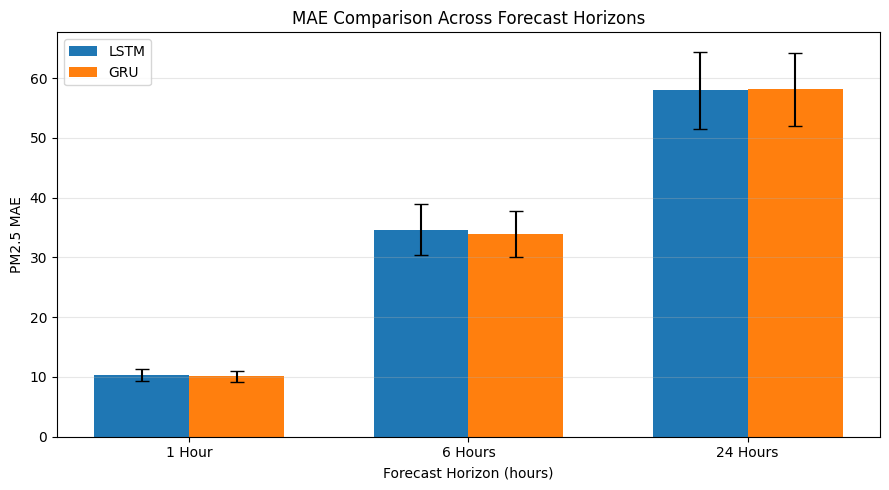

Saved: /content/drive/MyDrive/AeroSense_AI/results/final_thesis_graphs/neural_mae_comparison.png


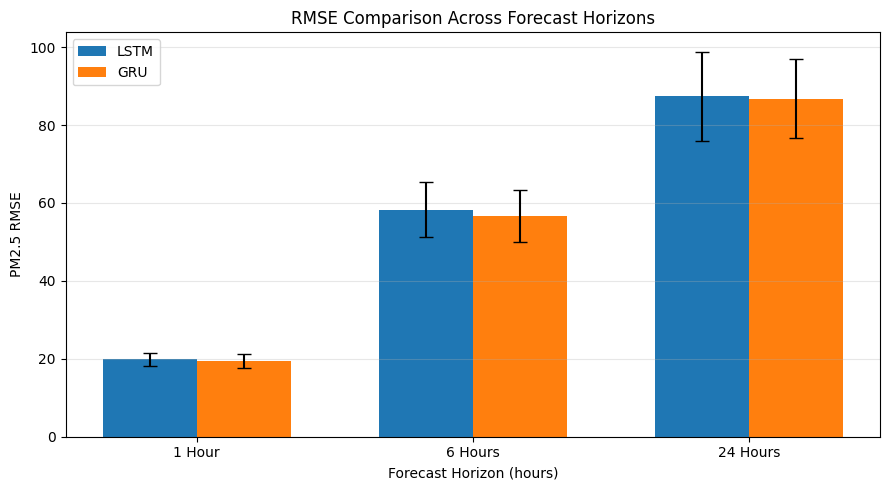

Saved: /content/drive/MyDrive/AeroSense_AI/results/final_thesis_graphs/neural_rmse_comparison.png


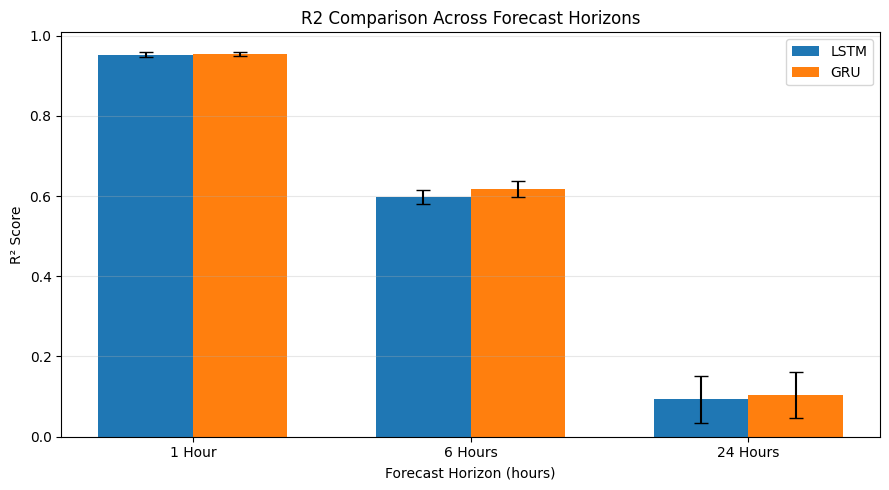

Saved: /content/drive/MyDrive/AeroSense_AI/results/final_thesis_graphs/neural_r2_comparison.png


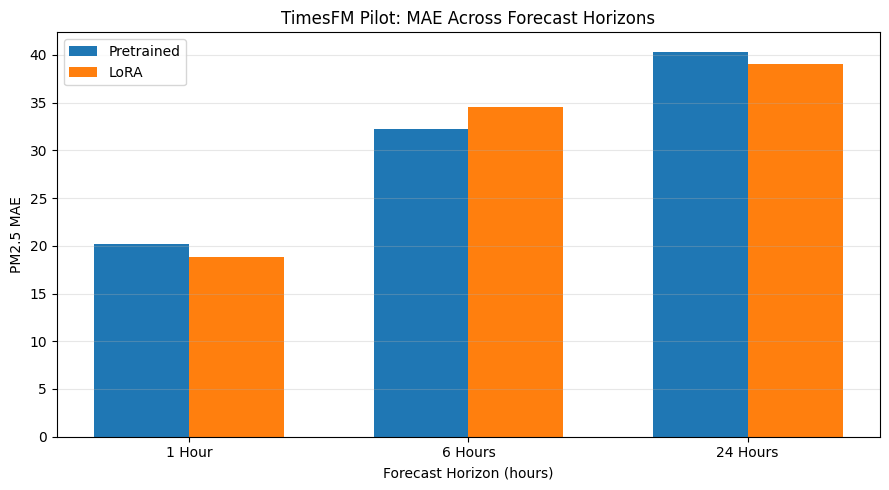

Saved: /content/drive/MyDrive/AeroSense_AI/results/final_thesis_graphs/timesfm_mae_comparison.png


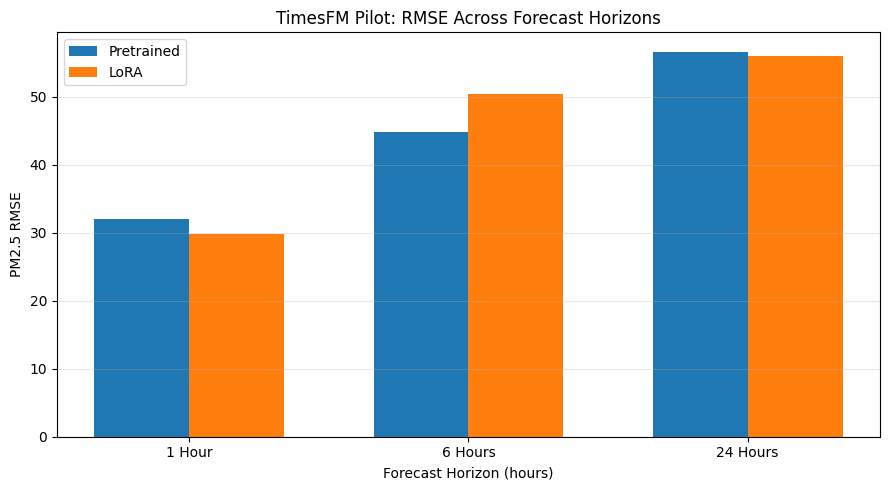

Saved: /content/drive/MyDrive/AeroSense_AI/results/final_thesis_graphs/timesfm_rmse_comparison.png


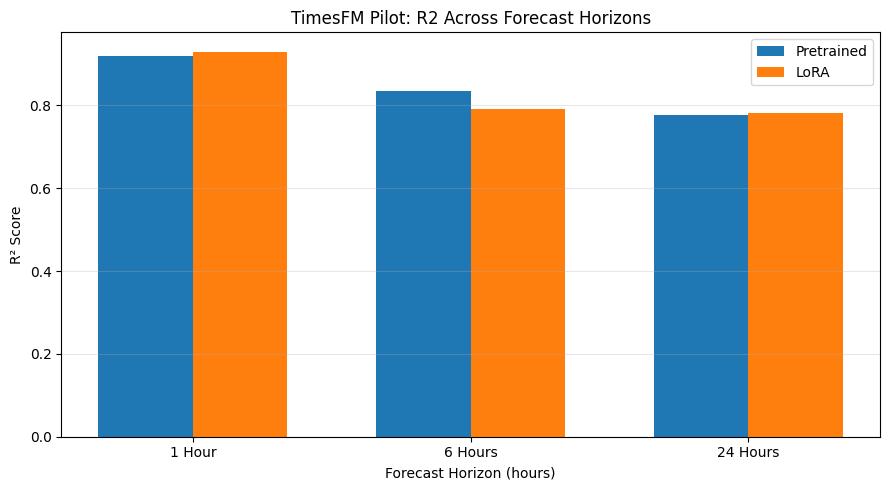

Saved: /content/drive/MyDrive/AeroSense_AI/results/final_thesis_graphs/timesfm_r2_comparison.png

All six thesis graphs generated successfully.
Graph folder: /content/drive/MyDrive/AeroSense_AI/results/final_thesis_graphs


In [15]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

BASE = "/content/drive/MyDrive/AeroSense_AI/results"

GRAPH_DIR = os.path.join(
    BASE, "final_thesis_graphs"
)
os.makedirs(GRAPH_DIR, exist_ok=True)

# Load verified results
neural = pd.read_csv(
    os.path.join(
        BASE,
        "deep_learning",
        "verified_neural_loso_comparison.csv"
    )
)

timesfm = pd.read_csv(
    os.path.join(
        BASE,
        "timesfm",
        "timesfm_pilot_consolidated.csv"
    )
)

horizons = [1, 6, 24]

# --------------------------------
# 1. MAIN LSTM-GRU COMPARISON
# --------------------------------

metrics = [
    ("mean_mae", "std_mae", "MAE", "PM2.5 MAE"),
    ("mean_rmse", "std_rmse", "RMSE", "PM2.5 RMSE"),
    ("mean_r2", "std_r2", "R2", "R² Score")
]

for metric, std_metric, filename, ylabel in metrics:

    fig, ax = plt.subplots(figsize=(9, 5))

    x = np.arange(len(horizons))
    width = 0.34

    for index, model_name in enumerate(["LSTM", "GRU"]):

        subset = (
            neural[neural["model"] == model_name]
            .set_index("horizon_hours")
            .loc[horizons]
        )

        positions = x + (index - 0.5) * width

        ax.bar(
            positions,
            subset[metric],
            width,
            yerr=subset[std_metric],
            capsize=5,
            label=model_name
        )

    ax.set_title(
        f"{filename} Comparison Across Forecast Horizons"
    )
    ax.set_xlabel("Forecast Horizon (hours)")
    ax.set_ylabel(ylabel)
    ax.set_xticks(x)
    ax.set_xticklabels(["1 Hour", "6 Hours", "24 Hours"])
    ax.legend()
    ax.grid(axis="y", alpha=0.3)
    fig.tight_layout()

    path = os.path.join(
        GRAPH_DIR,
        f"neural_{filename.lower()}_comparison.png"
    )

    fig.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print("Saved:", path)


# --------------------------------
# 2. TIMESFM PILOT COMPARISON
# --------------------------------

timesfm_models = [
    "TimesFM_2.5_Pretrained",
    "TimesFM_2.5_LoRA"
]

timesfm_metrics = [
    ("MAE", "MAE", "PM2.5 MAE"),
    ("RMSE", "RMSE", "PM2.5 RMSE"),
    ("R2", "R2", "R² Score")
]

for metric, filename, ylabel in timesfm_metrics:

    fig, ax = plt.subplots(figsize=(9, 5))

    x = np.arange(len(horizons))
    width = 0.34

    for index, model_name in enumerate(timesfm_models):

        subset = (
            timesfm[timesfm["model"] == model_name]
            .set_index("horizon_hours")
            .loc[horizons]
        )

        positions = x + (index - 0.5) * width

        ax.bar(
            positions,
            subset[metric],
            width,
            label=model_name.replace("TimesFM_2.5_", "")
        )

    ax.set_title(
        f"TimesFM Pilot: {filename} Across Forecast Horizons"
    )
    ax.set_xlabel("Forecast Horizon (hours)")
    ax.set_ylabel(ylabel)
    ax.set_xticks(x)
    ax.set_xticklabels(["1 Hour", "6 Hours", "24 Hours"])
    ax.legend()
    ax.grid(axis="y", alpha=0.3)
    fig.tight_layout()

    path = os.path.join(
        GRAPH_DIR,
        f"timesfm_{filename.lower()}_comparison.png"
    )

    fig.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print("Saved:", path)

print("\nAll six thesis graphs generated successfully.")
print("Graph folder:", GRAPH_DIR)

In [16]:
import os
import pandas as pd

BASE = "/content/drive/MyDrive/AeroSense_AI"

print("FINAL GRAPH FILES")
graph_dir = os.path.join(BASE, "results", "final_thesis_graphs")

for f in sorted(os.listdir(graph_dir)):
    path = os.path.join(graph_dir, f)
    print(f, "|", round(os.path.getsize(path) / 1024, 2), "KB")

print("\nREPORT DIRECTORY")
report_dir = os.path.join(BASE, "reports")
print(os.listdir(report_dir))

print("\nPROJECT RESULT CSV SUMMARY")
for root, dirs, files in os.walk(os.path.join(BASE, "results")):
    for f in files:
        if f.endswith(".csv"):
            path = os.path.join(root, f)
            df = pd.read_csv(path)
            print(f"{os.path.relpath(path, BASE)} | rows={len(df)}")

FINAL GRAPH FILES
neural_mae_comparison.png | 79.2 KB
neural_r2_comparison.png | 78.41 KB
neural_rmse_comparison.png | 80.27 KB
timesfm_mae_comparison.png | 83.27 KB
timesfm_r2_comparison.png | 79.82 KB
timesfm_rmse_comparison.png | 81.11 KB

REPORT DIRECTORY
[]

PROJECT RESULT CSV SUMMARY
results/deep_learning/lstm_gru_comparison.csv | rows=6
results/deep_learning/extratrees_single_station_comparison.csv | rows=3
results/deep_learning/all_models_comparison.csv | rows=9
results/deep_learning/verified_neural_loso_comparison.csv | rows=6
results/transferability/extratrees_leave_one_station_out.csv | rows=36
results/transferability/transferability_summary.csv | rows=3
results/transferability/neural_pilot_Aotizhongxin.csv | rows=6
results/transferability/neural_pilot_Changping.csv | rows=6
results/transferability/neural_pilot_Dingling.csv | rows=6
results/transferability/neural_pilot_Dongsi.csv | rows=6
results/transferability/neural_pilot_Guanyuan.csv | rows=6
results/transferability/neur

In [17]:

import inspect
import os

for name in ["build_matched_sequences", "run_final_extratrees"]:
    print("\n" + "=" * 70)
    print("FUNCTION:", name)

    if name in globals():
        print(inspect.getsource(globals()[name]))
    else:
        print("NOT CURRENTLY DEFINED IN THIS RUNTIME")

print("\n" + "=" * 70)
print("EXPERIMENT DIRECTORIES")

for name in ["BASE", "FINAL_DIR", "FINAL_MODEL_DIR"]:
    print(name, "=", globals().get(name, "Not defined"))



FUNCTION: build_matched_sequences
NOT CURRENTLY DEFINED IN THIS RUNTIME

FUNCTION: run_final_extratrees
NOT CURRENTLY DEFINED IN THIS RUNTIME

EXPERIMENT DIRECTORIES
BASE = /content/drive/MyDrive/AeroSense_AI
FINAL_DIR = Not defined
FINAL_MODEL_DIR = Not defined


In [18]:

import os
import pandas as pd

BASE = "/content/drive/MyDrive/AeroSense_AI"

FINAL_DIR = os.path.join(
    BASE, "results", "transferability",
    "matched_extratrees_corrected"
)

FINAL_MODEL_DIR = os.path.join(
    BASE, "models", "transferability",
    "matched_extratrees_corrected"
)

os.makedirs(FINAL_DIR, exist_ok=True)
os.makedirs(FINAL_MODEL_DIR, exist_ok=True)

print("DIRECTORIES RESTORED")
print("FINAL_DIR:", FINAL_DIR)
print("FINAL_MODEL_DIR:", FINAL_MODEL_DIR)

print("\nDATASET")
DATA_PATH = os.path.join(
    BASE, "data", "air_quality_hourly.parquet"
)
print("Exists:", os.path.exists(DATA_PATH))

if os.path.exists(DATA_PATH):
    df_check = pd.read_parquet(DATA_PATH)
    print("Shape:", df_check.shape)
    print("Columns:", df_check.columns.tolist())
    print("Stations:", sorted(df_check["station"].dropna().unique()))

print("\nIMPORTANT RUNTIME VARIABLES")
for name in [
    "ALL_STATIONS", "station_data", "station_dfs",
    "feature_cols", "FEATURE_COLS", "HORIZONS",
    "LOOKBACK", "build_pooled_training_data",
    "build_matched_sequences", "run_corrected_extratrees"
]:
    print(name, ":", name in globals())

print("\nEXISTING CORRECTED EXPERIMENTS")
existing = [
    f for f in os.listdir(FINAL_DIR)
    if f.endswith(".csv")
]
print("Completed CSV files:", len(existing))
for f in sorted(existing):
    print(f)


DIRECTORIES RESTORED
FINAL_DIR: /content/drive/MyDrive/AeroSense_AI/results/transferability/matched_extratrees_corrected
FINAL_MODEL_DIR: /content/drive/MyDrive/AeroSense_AI/models/transferability/matched_extratrees_corrected

DATASET
Exists: True
Shape: (420768, 14)
Columns: ['timestamp', 'PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'wd', 'WSPM', 'station']
Stations: ['Aotizhongxin', 'Changping', 'Dingling', 'Dongsi', 'Guanyuan', 'Gucheng', 'Huairou', 'Nongzhanguan', 'Shunyi', 'Tiantan', 'Wanliu', 'Wanshouxigong']

IMPORTANT RUNTIME VARIABLES
ALL_STATIONS : False
station_data : False
station_dfs : False
feature_cols : False
FEATURE_COLS : False
HORIZONS : False
LOOKBACK : False
build_pooled_training_data : False
build_matched_sequences : False
run_corrected_extratrees : False

EXISTING CORRECTED EXPERIMENTS
Completed CSV files: 4
matched_extratrees_Aotizhongxin_1h.csv
matched_extratrees_Wanshouxigong_1h.csv
matched_extratrees_Wanshouxigong_24h.csv
matched

In [19]:

import os
import pandas as pd
import numpy as np

BASE = "/content/drive/MyDrive/AeroSense_AI"
DATA_PATH = os.path.join(BASE, "data", "air_quality_hourly.parquet")
FINAL_DIR = os.path.join(
    BASE, "results", "transferability",
    "matched_extratrees_corrected"
)

df = pd.read_parquet(DATA_PATH)

print("DATA TYPES")
print(df.dtypes)

print("\nMISSING VALUES")
print(df.isna().sum())

print("\nWIND DIRECTION VALUES")
print(df["wd"].value_counts(dropna=False).head(20))

print("\nEXISTING CORRECTED RESULT CONTENTS")
for filename in sorted(os.listdir(FINAL_DIR)):
    if filename.endswith(".csv"):
        path = os.path.join(FINAL_DIR, filename)
        result = pd.read_csv(path)
        print("\nFILE:", filename)
        print(result.to_string(index=False))

print("\nTIMESTAMP CHECK")
print("Minimum:", df["timestamp"].min())
print("Maximum:", df["timestamp"].max())
print("Duplicate station-timestamps:",
      df.duplicated(["station", "timestamp"]).sum())

print("\nROWS PER STATION")
print(df.groupby("station").size())


DATA TYPES
timestamp    datetime64[ns]
PM2.5               float64
PM10                float64
SO2                 float64
NO2                 float64
CO                  float64
O3                  float64
TEMP                float64
PRES                float64
DEWP                float64
RAIN                float64
wd                   object
WSPM                float64
station              object
dtype: object

MISSING VALUES
timestamp        0
PM2.5         8739
PM10          6449
SO2           9021
NO2          12116
CO           20701
O3           13277
TEMP           398
PRES           393
DEWP           403
RAIN           390
wd            1822
WSPM           318
station          0
dtype: int64

WIND DIRECTION VALUES
wd
NE      43335
ENE     34142
NW      32600
N       30869
E       29752
SW      28756
NNE     28232
NNW     25326
WNW     24375
ESE     24220
SSW     22563
SE      20074
WSW     20040
S       19405
SSE     17694
W       17563
None     1822
Name: count, dtype: int6

In [20]:

import os

BASE = "/content/drive/MyDrive/AeroSense_AI"

for folder in ["models", "notebooks", "results/transferability"]:
    path = os.path.join(BASE, folder)
    print("\n" + "=" * 60)
    print("FOLDER:", folder)

    for root, dirs, files in os.walk(path):
        level = root.replace(path, "").count(os.sep)
        if level > 3:
            dirs[:] = []
            continue

        indent = "  " * level
        print(indent + os.path.basename(root) + "/")

        for filename in files:
            full_path = os.path.join(root, filename)
            size_kb = os.path.getsize(full_path) / 1024
            print(indent + "  " + filename,
                  "|", round(size_kb, 1), "KB")




FOLDER: models
models/
  deep_learning/
    lstm_1h.pth | 209.8 KB
    gru_1h.pth | 158.1 KB
    lstm_6h.pth | 209.8 KB
    gru_6h.pth | 158.1 KB
    lstm_24h.pth | 210.0 KB
    gru_24h.pth | 158.1 KB
  transferability/
    lstm_1h_Aotizhongxin.pth | 210.4 KB
    gru_1h_Aotizhongxin.pth | 158.6 KB
    lstm_6h_Aotizhongxin.pth | 210.4 KB
    gru_6h_Aotizhongxin.pth | 158.6 KB
    lstm_24h_Aotizhongxin.pth | 210.4 KB
    gru_24h_Aotizhongxin.pth | 158.6 KB
    lstm_1h_Changping.pth | 211.6 KB
    gru_1h_Changping.pth | 159.8 KB
    lstm_6h_Changping.pth | 211.6 KB
    gru_6h_Changping.pth | 159.8 KB
    lstm_24h_Changping.pth | 211.6 KB
    gru_24h_Changping.pth | 159.8 KB
    lstm_1h_Dingling.pth | 211.6 KB
    gru_1h_Dingling.pth | 159.8 KB
    lstm_6h_Dingling.pth | 211.6 KB
    gru_6h_Dingling.pth | 159.8 KB
    lstm_24h_Dingling.pth | 211.6 KB
    gru_24h_Dingling.pth | 159.8 KB
    lstm_1h_Dongsi.pth | 211.6 KB
    gru_1h_Dongsi.pth | 159.7 KB
    lstm_6h_Dongsi.pth | 211.6 KB
   

In [21]:

import os
import pandas as pd

BASE = "/content/drive/MyDrive/AeroSense_AI"

folders = [
    "results/transferability/matched_extratrees_final",
    "results/transferability/matched_extratrees_valid_targets",
    "results/transferability/matched_extratrees",
    "models/transferability/matched_extratrees_corrected",
    "models/transferability/matched_extratrees_final",
    "models/transferability/matched_extratrees_valid_targets"
]

for folder in folders:
    path = os.path.join(BASE, folder)
    print("\n" + "=" * 65)
    print(folder)

    if not os.path.exists(path):
        print("NOT FOUND")
        continue

    files = sorted(os.listdir(path))
    print("File count:", len(files))

    for filename in files[:8]:
        full = os.path.join(path, filename)
        if filename.endswith(".csv"):
            print("\n", filename)
            print(pd.read_csv(full).to_string(index=False))
        elif os.path.isfile(full):
            print(filename, "|", round(os.path.getsize(full)/1024/1024, 2), "MB")



results/transferability/matched_extratrees_final
File count: 36

 matched_extratrees_Aotizhongxin_1h.csv
     model held_out_station  horizon_hours       mae      rmse       r2  training_seconds  test_samples
ExtraTrees     Aotizhongxin              1 10.660539 20.476935 0.951459        389.516797          5260

 matched_extratrees_Aotizhongxin_24h.csv
     model held_out_station  horizon_hours       mae      rmse       r2  training_seconds  test_samples
ExtraTrees     Aotizhongxin             24 60.224628 85.624667 0.151265        370.902574          5260

 matched_extratrees_Aotizhongxin_6h.csv
     model held_out_station  horizon_hours       mae      rmse       r2  training_seconds  test_samples
ExtraTrees     Aotizhongxin              6 33.472872 56.150914 0.635004         354.64475          5260

 matched_extratrees_Changping_1h.csv
     model held_out_station  horizon_hours       mae     rmse       r2  training_seconds  test_samples
ExtraTrees        Changping              1 10.

In [22]:

import os
import pandas as pd

BASE = "/content/drive/MyDrive/AeroSense_AI"

files = [
    "results/transferability/neural_loso_all_stations.csv",
    "results/transferability/neural_loso_summary.csv",
    "results/deep_learning/verified_neural_loso_comparison.csv"
]

for relative_path in files:
    path = os.path.join(BASE, relative_path)

    print("\n" + "=" * 60)
    print(relative_path)

    if os.path.exists(path):
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        print(df.head(8).to_string(index=False))
    else:
        print("NOT FOUND")



results/transferability/neural_loso_all_stations.csv
Shape: (72, 9)
Columns: ['model', 'horizon_hours', 'station', 'mae', 'rmse', 'r2', 'inference_seconds', 'test_samples', 'best_validation_loss']
model  horizon_hours      station       mae      rmse       r2  inference_seconds  test_samples  best_validation_loss
 LSTM              1 Aotizhongxin 10.314674 18.909152 0.959032           0.064797          5173              0.042322
  GRU              1 Aotizhongxin 10.272362 18.511420 0.960738           0.197714          5173              0.041979
 LSTM              6 Aotizhongxin 35.785885 58.570862 0.606937           0.121322          5173              0.428397
  GRU              6 Aotizhongxin 34.481094 57.370577 0.622882           0.192268          5173              0.400920
 LSTM             24 Aotizhongxin 60.420597 90.879180 0.053703           0.063549          5173              1.120970
  GRU             24 Aotizhongxin 60.114574 86.421518 0.144259           0.070932          517

In [23]:

import os
import numpy as np
import pandas as pd

BASE = "/content/drive/MyDrive/AeroSense_AI"
DATA_PATH = os.path.join(BASE, "data", "air_quality_hourly.parquet")

df = pd.read_parquet(DATA_PATH)
df = df.sort_values(["station", "timestamp"]).reset_index(drop=True)

STATIONS = sorted(df["station"].unique())
HORIZONS = [1, 6, 24]
LOOKBACK = 24

NUMERIC_FEATURES = [
    "PM2.5", "PM10", "SO2", "NO2", "CO", "O3",
    "TEMP", "PRES", "DEWP", "RAIN", "WSPM"
]

# Encode wind direction consistently across all stations.
wind_categories = sorted(df["wd"].dropna().unique())
wind_mapping = {value: i for i, value in enumerate(wind_categories)}
df["wd_encoded"] = df["wd"].map(wind_mapping)

FEATURE_COLS = NUMERIC_FEATURES + ["wd_encoded"]

print("Stations:", len(STATIONS))
print("Features:", len(FEATURE_COLS))
print("Input features per window:", LOOKBACK * len(FEATURE_COLS))
print("Horizons:", HORIZONS)

# Verify hourly continuity and target availability.
for station in STATIONS:
    part = df[df["station"] == station].reset_index(drop=True)
    timestamp_diff = part["timestamp"].diff().dropna()

    print(
        station,
        "| rows:", len(part),
        "| hourly gaps:", int((timestamp_diff != pd.Timedelta(hours=1)).sum()),
        "| valid PM2.5:", int(np.isfinite(part["PM2.5"]).sum())
    )

print("\nFeature preparation complete. No model trained.")


Stations: 12
Features: 12
Input features per window: 288
Horizons: [1, 6, 24]
Aotizhongxin | rows: 35064 | hourly gaps: 0 | valid PM2.5: 34139
Changping | rows: 35064 | hourly gaps: 0 | valid PM2.5: 34290
Dingling | rows: 35064 | hourly gaps: 0 | valid PM2.5: 34285
Dongsi | rows: 35064 | hourly gaps: 0 | valid PM2.5: 34314
Guanyuan | rows: 35064 | hourly gaps: 0 | valid PM2.5: 34448
Gucheng | rows: 35064 | hourly gaps: 0 | valid PM2.5: 34418
Huairou | rows: 35064 | hourly gaps: 0 | valid PM2.5: 34111
Nongzhanguan | rows: 35064 | hourly gaps: 0 | valid PM2.5: 34436
Shunyi | rows: 35064 | hourly gaps: 0 | valid PM2.5: 34151
Tiantan | rows: 35064 | hourly gaps: 0 | valid PM2.5: 34387
Wanliu | rows: 35064 | hourly gaps: 0 | valid PM2.5: 34682
Wanshouxigong | rows: 35064 | hourly gaps: 0 | valid PM2.5: 34368

Feature preparation complete. No model trained.


In [24]:

# Preserve the original 11-feature configuration.
# Do not include wd_encoded in this experiment.

FEATURE_COLS = [
    "PM2.5", "PM10", "SO2", "NO2", "CO", "O3",
    "TEMP", "PRES", "DEWP", "RAIN", "WSPM"
]

LOOKBACK = 24

print("Features:", len(FEATURE_COLS))
print("Lookback:", LOOKBACK)
print("Expected input dimensions:", len(FEATURE_COLS) * LOOKBACK)

assert len(FEATURE_COLS) == 11
assert len(FEATURE_COLS) * LOOKBACK == 264

print("Feature configuration verified.")


Features: 11
Lookback: 24
Expected input dimensions: 264
Feature configuration verified.


In [25]:

import numpy as np
import pandas as pd

# Chronological split: first 70% train, next 15% validation,
# final 15% test, using the existing neural LOSO date boundaries.
# We inspect the actual split before applying it to all stations.

HOLDOUT = "Aotizhongxin"
HORIZON = 1

parts = []

for station in STATIONS:
    part = (
        df[df["station"] == station]
        .sort_values("timestamp")
        .reset_index(drop=True)
        .copy()
    )

    # Use only the original 11 numerical features.
    X = part[FEATURE_COLS].replace([np.inf, -np.inf], np.nan)

    # Missing feature values are filled using each training station's
    # historical median in the later training pipeline.
    # For this alignment pilot, preserve NaNs.
    y = part["PM2.5"].to_numpy(dtype=float)
    timestamps = part["timestamp"].to_numpy()

    if station == HOLDOUT:
        n = len(part)
        train_end = int(n * 0.70)
        val_end = int(n * 0.85)

        print("Held-out station:", station)
        print("Rows:", n)
        print("Train boundary:", part.loc[train_end - 1, "timestamp"])
        print("Validation boundary:", part.loc[val_end - 1, "timestamp"])
        print("Test begins:", part.loc[val_end, "timestamp"])

        # Build sample indices and verify exact forecast alignment.
        valid_samples = 0
        skipped_targets = 0

        for target_idx in range(LOOKBACK, n):
            input_start = target_idx - LOOKBACK
            input_end = target_idx - 1

            target_value = y[target_idx]

            if not np.isfinite(target_value):
                skipped_targets += 1
                continue

            if timestamps[target_idx] - timestamps[input_end] != np.timedelta64(1, "h"):
                continue

            if np.isnan(X.iloc[input_start:target_idx].to_numpy()).all():
                continue

            valid_samples += 1

        print("Valid 1-hour aligned targets:", valid_samples)
        print("Skipped missing targets:", skipped_targets)

        assert valid_samples > 0
        print("Sequence alignment pilot passed.")


Held-out station: Aotizhongxin
Rows: 35064
Train boundary: 2015-12-18 15:00:00
Validation boundary: 2016-07-24 19:00:00
Test begins: 2016-07-24 20:00:00
Valid 1-hour aligned targets: 34115
Skipped missing targets: 925
Sequence alignment pilot passed.


In [26]:

import numpy as np
import pandas as pd

train_counts = []
val_counts = []
test_counts = []

for station in STATIONS:
    part = (
        df[df["station"] == station]
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    n = len(part)
    train_end = int(n * 0.70)
    val_end = int(n * 0.85)

    y = part["PM2.5"].to_numpy(dtype=float)
    X = part[FEATURE_COLS].replace([np.inf, -np.inf], np.nan)

    counts = {"train": 0, "validation": 0, "test": 0}
    missing_feature_windows = {"train": 0, "validation": 0, "test": 0}

    for target_idx in range(LOOKBACK, n):
        if not np.isfinite(y[target_idx]):
            continue

        if target_idx < train_end:
            split = "train"
        elif target_idx < val_end:
            split = "validation"
        else:
            split = "test"

        window = X.iloc[target_idx-LOOKBACK:target_idx].to_numpy()

        counts[split] += 1

        if not np.isfinite(window).all():
            missing_feature_windows[split] += 1

    train_counts.append(counts["train"])
    val_counts.append(counts["validation"])
    test_counts.append(counts["test"])

    print(
        station,
        "| train:", counts["train"],
        "| validation:", counts["validation"],
        "| test:", counts["test"],
        "| train windows with missing features:", missing_feature_windows["train"],
        "| validation windows with missing features:", missing_feature_windows["validation"],
        "| test windows with missing features:", missing_feature_windows["test"]
    )

print("\nPooled totals across 11 stations (excluding Aotizhongxin):")
print("Train:", sum(train_counts) - train_counts[STATIONS.index("Aotizhongxin")])
print("Validation:", sum(val_counts) - val_counts[STATIONS.index("Aotizhongxin")])

print("\nAotizhongxin held-out test samples:", test_counts[STATIONS.index("Aotizhongxin")])
print("Previously recorded corrected test samples: 5173")


Aotizhongxin | train: 23790 | validation: 5152 | test: 5173 | train windows with missing features: 10497 | validation windows with missing features: 3201 | test windows with missing features: 2487
Changping | train: 23879 | validation: 5186 | test: 5201 | train windows with missing features: 7767 | validation windows with missing features: 1325 | test windows with missing features: 1187
Dingling | train: 24059 | validation: 5157 | test: 5045 | train windows with missing features: 10372 | validation windows with missing features: 2461 | test windows with missing features: 1622
Dongsi | train: 24155 | validation: 5053 | test: 5082 | train windows with missing features: 8641 | validation windows with missing features: 1513 | test windows with missing features: 1346
Guanyuan | train: 24098 | validation: 5167 | test: 5159 | train windows with missing features: 8266 | validation windows with missing features: 963 | test windows with missing features: 1305
Gucheng | train: 24041 | validation:

In [27]:

TRAIN_END = pd.Timestamp("2015-07-25 14:00:00")
VAL_END = pd.Timestamp("2015-12-18 16:00:00")
TEST_START = pd.Timestamp("2016-07-24 20:00:00")

pooled_train = 0
pooled_val = 0
station_test_counts = {}

for station in STATIONS:
    part = (
        df[df["station"] == station]
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    # A target is usable only when PM2.5 is finite and
    # a complete 24-hour history exists before it.
    valid = np.isfinite(part["PM2.5"].to_numpy(dtype=float))
    valid[:LOOKBACK] = False

    ts = part["timestamp"]

    train_mask = valid & (ts <= TRAIN_END).to_numpy()
    val_mask = valid & (ts > TRAIN_END).to_numpy() & (ts <= VAL_END).to_numpy()
    test_mask = valid & (ts >= TEST_START).to_numpy()

    if station != "Aotizhongxin":
        pooled_train += int(train_mask.sum())
        pooled_val += int(val_mask.sum())

    station_test_counts[station] = int(test_mask.sum())

    print(
        station,
        "| train:", int(train_mask.sum()),
        "| validation:", int(val_mask.sum()),
        "| test:", int(test_mask.sum())
    )

print("\nCandidate pooled training:", pooled_train)
print("Previously recorded training:", 226706)
print("Candidate pooled validation:", pooled_val)
print("Previously recorded validation:", 37585)
print("Aotizhongxin candidate test:", station_test_counts["Aotizhongxin"])
print("Previously recorded test:", 5173)


Aotizhongxin | train: 20385 | validation: 3406 | test: 5173
Changping | train: 20587 | validation: 3292 | test: 5201
Dingling | train: 20620 | validation: 3440 | test: 5045
Dongsi | train: 20689 | validation: 3467 | test: 5082
Guanyuan | train: 20635 | validation: 3464 | test: 5159
Gucheng | train: 20635 | validation: 3407 | test: 5160
Huairou | train: 20311 | validation: 3435 | test: 5176
Nongzhanguan | train: 20693 | validation: 3351 | test: 5172
Shunyi | train: 20505 | validation: 3444 | test: 5113
Tiantan | train: 20569 | validation: 3423 | test: 5185
Wanliu | train: 20810 | validation: 3452 | test: 5195
Wanshouxigong | train: 20663 | validation: 3409 | test: 5176

Candidate pooled training: 226717
Previously recorded training: 226706
Candidate pooled validation: 37584
Previously recorded validation: 37585
Aotizhongxin candidate test: 5173
Previously recorded test: 5173


In [28]:

TRAIN_END = pd.Timestamp("2015-12-18 15:00:00")
VAL_END = pd.Timestamp("2016-07-24 19:00:00")

results = []

for station in STATIONS:
    part = (
        df[df["station"] == station]
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    y = part["PM2.5"].to_numpy(dtype=float)
    timestamps = pd.to_datetime(part["timestamp"]).to_numpy()

    for horizon in HORIZONS:
        counts = {"train": 0, "validation": 0, "test": 0}

        # The input window ends at input_end.
        # The target occurs exactly `horizon` hours later.
        for input_end in range(LOOKBACK - 1, len(part) - horizon):
            target_idx = input_end + horizon
            target_time = pd.Timestamp(timestamps[target_idx])

            if not np.isfinite(y[target_idx]):
                continue

            if target_time <= TRAIN_END:
                split = "train"
            elif target_time <= VAL_END:
                split = "validation"
            else:
                split = "test"

            counts[split] += 1

        results.append({
            "station": station,
            "horizon": horizon,
            **counts
        })

check_df = pd.DataFrame(results)

for horizon in HORIZONS:
    subset = check_df[check_df["horizon"] == horizon]
    pooled_train = subset[subset["station"] != "Aotizhongxin"]["train"].sum()
    pooled_val = subset[subset["station"] != "Aotizhongxin"]["validation"].sum()
    heldout_test = subset[subset["station"] == "Aotizhongxin"]["test"].iloc[0]

    print(
        f"\nHorizon {horizon}h"
        f"\nPooled training: {pooled_train}"
        f"\nPooled validation: {pooled_val}"
        f"\nAotizhongxin test: {heldout_test}"
    )

print("\nPer-station counts:")
print(check_df.to_string(index=False))



Horizon 1h
Pooled training: 264291
Pooled validation: 56671
Aotizhongxin test: 5173

Horizon 6h
Pooled training: 264236
Pooled validation: 56671
Aotizhongxin test: 5173

Horizon 24h
Pooled training: 264038
Pooled validation: 56671
Aotizhongxin test: 5173

Per-station counts:
      station  horizon  train  validation  test
 Aotizhongxin        1  23790        5152  5173
 Aotizhongxin        6  23785        5152  5173
 Aotizhongxin       24  23767        5152  5173
    Changping        1  23879        5186  5201
    Changping        6  23874        5186  5201
    Changping       24  23856        5186  5201
     Dingling        1  24059        5157  5045
     Dingling        6  24054        5157  5045
     Dingling       24  24036        5157  5045
       Dongsi        1  24155        5053  5082
       Dongsi        6  24150        5053  5082
       Dongsi       24  24132        5053  5082
     Guanyuan        1  24098        5167  5159
     Guanyuan        6  24093        5167  5159
   

In [29]:

import os
import glob
import pandas as pd

FINAL_DIR = os.path.join(
    BASE, "results", "transferability", "matched_extratrees_corrected"
)

files = sorted(glob.glob(os.path.join(FINAL_DIR, "*.csv")))

print("Corrected result files:", len(files))

for path in files:
    result = pd.read_csv(path)
    print("\nFILE:", os.path.basename(path))
    print("Columns:", result.columns.tolist())
    print(result.to_string(index=False))


Corrected result files: 4

FILE: matched_extratrees_Aotizhongxin_1h.csv
Columns: ['model', 'horizon_hours', 'station', 'train_samples', 'validation_samples', 'test_samples', 'mae', 'rmse', 'r2', 'training_seconds']
     model  horizon_hours      station  train_samples  validation_samples  test_samples       mae      rmse       r2  training_seconds
ExtraTrees              1 Aotizhongxin         226706               37585          5173 10.880356 20.464523 0.952015       1095.064383

FILE: matched_extratrees_Wanshouxigong_1h.csv
Columns: ['model', 'horizon_hours', 'station', 'mae', 'rmse', 'r2', 'training_seconds', 'test_samples']
     model  horizon_hours       station       mae      rmse       r2  training_seconds  test_samples
ExtraTrees              1 Wanshouxigong 12.020012 25.482337 0.938968       1262.632666          5176

FILE: matched_extratrees_Wanshouxigong_24h.csv
Columns: ['model', 'horizon_hours', 'station', 'mae', 'rmse', 'r2', 'training_seconds', 'test_samples']
     model

In [30]:

import os

folders = [
    os.path.join(BASE, "results", "transferability"),
    os.path.join(BASE, "models", "transferability"),
    os.path.join(BASE, "notebooks")
]

for folder in folders:
    print("\n" + "=" * 65)
    print("FOLDER:", folder)

    if not os.path.exists(folder):
        print("Folder does not exist.")
        continue

    for root, dirs, files in os.walk(folder):
        level = root.replace(folder, "").count(os.sep)
        if level > 2:
            dirs[:] = []
            continue

        for filename in files:
            path = os.path.join(root, filename)
            size_mb = os.path.getsize(path) / (1024 * 1024)

            print(
                os.path.relpath(path, folder),
                "|", round(size_mb, 2), "MB"
            )



FOLDER: /content/drive/MyDrive/AeroSense_AI/results/transferability
extratrees_leave_one_station_out.csv | 0.0 MB
transferability_summary.csv | 0.0 MB
station_mae_1h.png | 0.13 MB
station_mae_6h.png | 0.13 MB
station_mae_24h.png | 0.13 MB
neural_pilot_Aotizhongxin.csv | 0.0 MB
neural_pilot_Changping.csv | 0.0 MB
neural_pilot_Dingling.csv | 0.0 MB
neural_pilot_Dongsi.csv | 0.0 MB
neural_pilot_Guanyuan.csv | 0.0 MB
neural_pilot_Gucheng.csv | 0.0 MB
neural_pilot_Huairou.csv | 0.0 MB
neural_pilot_Nongzhanguan.csv | 0.0 MB
neural_pilot_Shunyi.csv | 0.0 MB
neural_pilot_Tiantan.csv | 0.0 MB
neural_pilot_Wanliu.csv | 0.0 MB
neural_pilot_Wanshouxigong.csv | 0.0 MB
neural_loso_all_stations.csv | 0.01 MB
neural_loso_summary.csv | 0.0 MB
matched_extratrees/matched_extratrees_Aotizhongxin_1h.csv | 0.0 MB
matched_extratrees/matched_extratrees_Aotizhongxin_6h.csv | 0.0 MB
matched_extratrees/matched_extratrees_Aotizhongxin_24h.csv | 0.0 MB
matched_extratrees/matched_extratrees_Changping_1h.csv | 0.0 

In [31]:

import os
import pandas as pd

paths = {
    "Original LOSO summary": os.path.join(
        BASE, "results", "transferability",
        "extratrees_leave_one_station_out.csv"
    ),
    "Original matched Aotizhongxin 1h": os.path.join(
        BASE, "results", "transferability",
        "matched_extratrees",
        "matched_extratrees_Aotizhongxin_1h.csv"
    ),
    "Original final Aotizhongxin 1h": os.path.join(
        BASE, "results", "transferability",
        "matched_extratrees_final",
        "matched_extratrees_Aotizhongxin_1h.csv"
    )
}

for label, path in paths.items():
    print("\n" + "=" * 65)
    print(label)

    if os.path.exists(path):
        data = pd.read_csv(path)
        print("Shape:", data.shape)
        print("Columns:", data.columns.tolist())
        print(data.head(5).to_string(index=False))
    else:
        print("File not found:", path)

# Inspect the saved ExtraTrees model metadata without loading
# the large models into memory.
import joblib

model_path = os.path.join(
    BASE, "models", "transferability",
    "matched_extratrees_Aotizhongxin_1h.joblib"
)

if os.path.exists(model_path):
    model = joblib.load(model_path)
    print("\nSaved model metadata:")
    print("Model type:", type(model).__name__)
    print("Parameters:", model.get_params())
    print("Number of estimators:", len(model.estimators_))
    print("Number of input features:", model.n_features_in_)



Original LOSO summary
Shape: (36, 9)
Columns: ['held_out_station', 'model', 'horizon_hours', 'mae', 'rmse', 'r2', 'inference_seconds', 'train_samples', 'test_samples']
held_out_station      model  horizon_hours       mae      rmse       r2  inference_seconds  train_samples  test_samples
    Aotizhongxin ExtraTrees              1 10.433298 19.188326 0.957821           0.385222         264544          5172
    Aotizhongxin ExtraTrees              6 33.622854 56.529022 0.634270           0.201017         264489          5167
    Aotizhongxin ExtraTrees             24 60.735641 86.745412 0.140704           0.247934         264291          5153
       Changping ExtraTrees              1 10.071958 18.826319 0.945750           0.395328         264455          5200
       Changping ExtraTrees              6 28.392144 48.693892 0.637394           0.345053         264400          5195

Original matched Aotizhongxin 1h
Shape: (1, 8)
Columns: ['model', 'station', 'horizon_hours', 'mae', 'rmse', '

In [32]:

import os
import joblib
import pandas as pd
import numpy as np

model_path = os.path.join(
    BASE, "models", "transferability",
    "matched_extratrees_Aotizhongxin_1h.joblib"
)

model = joblib.load(model_path)

print("MODEL AUDIT")
print("Input features:", model.n_features_in_)
print("Estimators:", len(model.estimators_))
print("Max features:", model.max_features)
print("Min samples leaf:", model.min_samples_leaf)
print("Random state:", model.random_state)

tree_nodes = [tree.tree_.node_count for tree in model.estimators_]
print("Average nodes per tree:", round(np.mean(tree_nodes), 2))
print("Minimum nodes:", min(tree_nodes))
print("Maximum nodes:", max(tree_nodes))

summary_path = os.path.join(
    BASE, "results", "transferability",
    "extratrees_leave_one_station_out.csv"
)

original = pd.read_csv(summary_path)

print("\nORIGINAL LOSO SUMMARY")
print("Total experiments:", len(original))
print("Unique stations:", original["held_out_station"].nunique())
print("Horizons:", sorted(original["horizon_hours"].unique()))
print("\nExperiments per horizon:")
print(original.groupby("horizon_hours").size())

print("\nOriginal Aotizhongxin results:")
print(
    original[original["held_out_station"] == "Aotizhongxin"]
    .to_string(index=False)
)

print("\nOriginal Wanshouxigong results:")
print(
    original[original["held_out_station"] == "Wanshouxigong"]
    .to_string(index=False)
)


MODEL AUDIT
Input features: 264
Estimators: 64
Max features: 0.5
Min samples leaf: 2
Random state: 42
Average nodes per tree: 198409.28
Minimum nodes: 198057
Maximum nodes: 198651

ORIGINAL LOSO SUMMARY
Total experiments: 36
Unique stations: 12
Horizons: [np.int64(1), np.int64(6), np.int64(24)]

Experiments per horizon:
horizon_hours
1     12
6     12
24    12
dtype: int64

Original Aotizhongxin results:
held_out_station      model  horizon_hours       mae      rmse       r2  inference_seconds  train_samples  test_samples
    Aotizhongxin ExtraTrees              1 10.433298 19.188326 0.957821           0.385222         264544          5172
    Aotizhongxin ExtraTrees              6 33.622854 56.529022 0.634270           0.201017         264489          5167
    Aotizhongxin ExtraTrees             24 60.735641 86.745412 0.140704           0.247934         264291          5153

Original Wanshouxigong results:
held_out_station      model  horizon_hours       mae      rmse       r2  infere

In [33]:

original = pd.read_csv(
    os.path.join(
        BASE, "results", "transferability",
        "extratrees_leave_one_station_out.csv"
    )
)

print("ORIGINAL TRAIN SAMPLE COUNTS")
print(
    original.pivot(
        index="held_out_station",
        columns="horizon_hours",
        values="train_samples"
    ).to_string()
)

print("\nORIGINAL TEST SAMPLE COUNTS")
print(
    original.pivot(
        index="held_out_station",
        columns="horizon_hours",
        values="test_samples"
    ).to_string()
)

print("\nCURRENT RECONSTRUCTED COUNTS")
print(check_df.pivot(
    index="station",
    columns="horizon",
    values="train"
).to_string())

print("\nSample count inspection complete.")


ORIGINAL TRAIN SAMPLE COUNTS
horizon_hours         1       6       24
held_out_station                        
Aotizhongxin      264544  264489  264291
Changping         264455  264400  264202
Dingling          264275  264220  264022
Dongsi            264179  264124  263926
Guanyuan          264236  264181  263983
Gucheng           264293  264238  264040
Huairou           264589  264534  264336
Nongzhanguan      264291  264236  264038
Shunyi            264386  264331  264133
Tiantan           264343  264288  264090
Wanliu            264073  264018  263820
Wanshouxigong     264263  264208  264010

ORIGINAL TEST SAMPLE COUNTS
horizon_hours       1     6     24
held_out_station                  
Aotizhongxin      5172  5167  5153
Changping         5200  5195  5177
Dingling          5044  5039  5021
Dongsi            5082  5082  5079
Guanyuan          5158  5153  5135
Gucheng           5159  5154  5136
Huairou           5176  5176  5160
Nongzhanguan      5171  5166  5148
Shunyi            

In [34]:

print("VERIFYING FULL-DATASET LOSO COUNTS")

for held_out in STATIONS:
    pooled = df[df["station"] != held_out].copy()

    print(f"\nHeld out: {held_out}")

    for horizon in HORIZONS:
        total = 0

        for station in STATIONS:
            if station == held_out:
                continue

            part = (
                df[df["station"] == station]
                .sort_values("timestamp")
                .reset_index(drop=True)
            )

            y = part["PM2.5"].to_numpy(dtype=float)

            # Valid targets with a full 24-hour history.
            count = 0
            for target_idx in range(LOOKBACK, len(part) - horizon + 1):
                if np.isfinite(y[target_idx]):
                    count += 1

            total += count

        expected = int(
            original.loc[
                (original["held_out_station"] == held_out) &
                (original["horizon_hours"] == horizon),
                "train_samples"
            ].iloc[0]
        )

        print(
            f"{horizon}h | reconstructed: {total}"
            f" | original: {expected}"
            f" | difference: {total - expected}"
        )


VERIFYING FULL-DATASET LOSO COUNTS

Held out: Aotizhongxin
1h | reconstructed: 377626 | original: 264544 | difference: 113082
6h | reconstructed: 377571 | original: 264489 | difference: 113082
24h | reconstructed: 377383 | original: 264291 | difference: 113092

Held out: Changping
1h | reconstructed: 377475 | original: 264455 | difference: 113020
6h | reconstructed: 377420 | original: 264400 | difference: 113020
24h | reconstructed: 377232 | original: 264202 | difference: 113030

Held out: Dingling
1h | reconstructed: 377480 | original: 264275 | difference: 113205
6h | reconstructed: 377425 | original: 264220 | difference: 113205
24h | reconstructed: 377237 | original: 264022 | difference: 113215

Held out: Dongsi
1h | reconstructed: 377451 | original: 264179 | difference: 113272
6h | reconstructed: 377396 | original: 264124 | difference: 113272
24h | reconstructed: 377208 | original: 263926 | difference: 113282

Held out: Guanyuan
1h | reconstructed: 377317 | original: 264236 | differ

In [35]:
print("VERIFYING ORIGINAL 70% CHRONOLOGICAL TRAIN SPLIT")

for held_out in STATIONS:
    total_by_horizon = {}

    for horizon in HORIZONS:
        total = 0

        for station in STATIONS:
            if station == held_out:
                continue

            part = (
                df[df["station"] == station]
                .sort_values("timestamp")
                .reset_index(drop=True)
            )

            y = part["PM2.5"].to_numpy(dtype=float)

            # First 70% of each station's chronological timeline
            train_end = int(len(part) * 0.70)

            # Target is horizon hours after the 24-hour input window
            for target_idx in range(LOOKBACK + horizon - 1, train_end):
                if np.isfinite(y[target_idx]):
                    total += 1

        expected = int(
            original.loc[
                (original["held_out_station"] == held_out) &
                (original["horizon_hours"] == horizon),
                "train_samples"
            ].iloc[0]
        )

        total_by_horizon[horizon] = total

        print(
            f"{held_out} | {horizon}h"
            f" | reconstructed: {total}"
            f" | original: {expected}"
            f" | difference: {total - expected}"
        )

VERIFYING ORIGINAL 70% CHRONOLOGICAL TRAIN SPLIT
Aotizhongxin | 1h | reconstructed: 264291 | original: 264544 | difference: -253
Aotizhongxin | 6h | reconstructed: 264236 | original: 264489 | difference: -253
Aotizhongxin | 24h | reconstructed: 264038 | original: 264291 | difference: -253
Changping | 1h | reconstructed: 264202 | original: 264455 | difference: -253
Changping | 6h | reconstructed: 264147 | original: 264400 | difference: -253
Changping | 24h | reconstructed: 263949 | original: 264202 | difference: -253
Dingling | 1h | reconstructed: 264022 | original: 264275 | difference: -253
Dingling | 6h | reconstructed: 263967 | original: 264220 | difference: -253
Dingling | 24h | reconstructed: 263769 | original: 264022 | difference: -253
Dongsi | 1h | reconstructed: 263926 | original: 264179 | difference: -253
Dongsi | 6h | reconstructed: 263871 | original: 264124 | difference: -253
Dongsi | 24h | reconstructed: 263673 | original: 263926 | difference: -253
Guanyuan | 1h | reconstruc

In [36]:
print("CHECKING THE FIRST 24 TARGET POSITIONS")

for station in STATIONS:
    part = (
        df[df["station"] == station]
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    y = part["PM2.5"].to_numpy(dtype=float)

    first_23 = int(np.isfinite(y[:23]).sum())
    first_24 = int(np.isfinite(y[:24]).sum())

    print(
        f"{station:18s} | "
        f"valid in first 23 rows: {first_23} | "
        f"valid in first 24 rows: {first_24}"
    )

CHECKING THE FIRST 24 TARGET POSITIONS
Aotizhongxin       | valid in first 23 rows: 23 | valid in first 24 rows: 24
Changping          | valid in first 23 rows: 23 | valid in first 24 rows: 24
Dingling           | valid in first 23 rows: 23 | valid in first 24 rows: 24
Dongsi             | valid in first 23 rows: 23 | valid in first 24 rows: 24
Guanyuan           | valid in first 23 rows: 23 | valid in first 24 rows: 24
Gucheng            | valid in first 23 rows: 23 | valid in first 24 rows: 24
Huairou            | valid in first 23 rows: 23 | valid in first 24 rows: 24
Nongzhanguan       | valid in first 23 rows: 23 | valid in first 24 rows: 24
Shunyi             | valid in first 23 rows: 23 | valid in first 24 rows: 24
Tiantan            | valid in first 23 rows: 23 | valid in first 24 rows: 24
Wanliu             | valid in first 23 rows: 23 | valid in first 24 rows: 24
Wanshouxigong      | valid in first 23 rows: 23 | valid in first 24 rows: 24


In [37]:
import os
import glob
import pandas as pd

RESULT_DIR = os.path.join(
    BASE, "results", "transferability",
    "matched_extratrees_corrected"
)

files = sorted(glob.glob(os.path.join(RESULT_DIR, "*.csv")))

print("CORRECTED RESULT FILES:", len(files))

for path in files:
    result = pd.read_csv(path)
    print("\nFILE:", os.path.basename(path))
    print("Rows:", len(result))
    print("Columns:", result.columns.tolist())
    print(result.to_string(index=False))

CORRECTED RESULT FILES: 4

FILE: matched_extratrees_Aotizhongxin_1h.csv
Rows: 1
Columns: ['model', 'horizon_hours', 'station', 'train_samples', 'validation_samples', 'test_samples', 'mae', 'rmse', 'r2', 'training_seconds']
     model  horizon_hours      station  train_samples  validation_samples  test_samples       mae      rmse       r2  training_seconds
ExtraTrees              1 Aotizhongxin         226706               37585          5173 10.880356 20.464523 0.952015       1095.064383

FILE: matched_extratrees_Wanshouxigong_1h.csv
Rows: 1
Columns: ['model', 'horizon_hours', 'station', 'mae', 'rmse', 'r2', 'training_seconds', 'test_samples']
     model  horizon_hours       station       mae      rmse       r2  training_seconds  test_samples
ExtraTrees              1 Wanshouxigong 12.020012 25.482337 0.938968       1262.632666          5176

FILE: matched_extratrees_Wanshouxigong_24h.csv
Rows: 1
Columns: ['model', 'horizon_hours', 'station', 'mae', 'rmse', 'r2', 'training_seconds', 't

In [38]:
import os
import glob
import pandas as pd

RESULT_DIR = os.path.join(
    BASE,
    "results",
    "transferability",
    "matched_extratrees_corrected"
)

os.makedirs(RESULT_DIR, exist_ok=True)

# Read all existing corrected results
completed = set()

for path in glob.glob(
    os.path.join(RESULT_DIR, "matched_extratrees_*.csv")
):
    saved = pd.read_csv(path)

    for _, row in saved.iterrows():
        completed.add((
            str(row["station"]),
            int(row["horizon_hours"])
        ))

# Build all 36 planned experiments
all_experiments = [
    {
        "station": station,
        "horizon_hours": horizon
    }
    for station in STATIONS
    for horizon in HORIZONS
]

# Keep only experiments that are not already saved
pending = [
    experiment
    for experiment in all_experiments
    if (
        experiment["station"],
        experiment["horizon_hours"]
    ) not in completed
]

pending_df = pd.DataFrame(pending)

PENDING_PATH = os.path.join(
    RESULT_DIR,
    "pending_experiments.csv"
)

pending_df.to_csv(PENDING_PATH, index=False)

print("EXPERIMENT PLAN")
print("Total planned:", len(all_experiments))
print("Already completed:", len(completed))
print("Remaining:", len(pending_df))
print("\nRemaining experiments:")
print(pending_df.to_string(index=False))
print("\nSaved pending list:", PENDING_PATH)

EXPERIMENT PLAN
Total planned: 36
Already completed: 4
Remaining: 32

Remaining experiments:
     station  horizon_hours
Aotizhongxin              6
Aotizhongxin             24
   Changping              1
   Changping              6
   Changping             24
    Dingling              1
    Dingling              6
    Dingling             24
      Dongsi              1
      Dongsi              6
      Dongsi             24
    Guanyuan              1
    Guanyuan              6
    Guanyuan             24
     Gucheng              1
     Gucheng              6
     Gucheng             24
     Huairou              1
     Huairou              6
     Huairou             24
Nongzhanguan              1
Nongzhanguan              6
Nongzhanguan             24
      Shunyi              1
      Shunyi              6
      Shunyi             24
     Tiantan              1
     Tiantan              6
     Tiantan             24
      Wanliu              1
      Wanliu              6
      Wanli

In [39]:
import inspect

for name in ["build_matched_sequences", "run_final_extratrees"]:
    print("\n" + "=" * 80)
    print("FUNCTION:", name)
    print("=" * 80)

    if name in globals():
        try:
            print(inspect.getsource(globals()[name]))
        except Exception as e:
            print("Could not retrieve source:", repr(e))
    else:
        print("Function is not defined in this runtime.")


FUNCTION: build_matched_sequences
Function is not defined in this runtime.

FUNCTION: run_final_extratrees
Function is not defined in this runtime.


In [40]:
import os

SEARCH_DIRS = [
    os.path.join(BASE, "notebooks"),
    os.path.join(BASE, "results"),
    os.path.join(BASE, "models"),
    os.path.join(BASE, "reports")
]

print("SEARCHING FOR NOTEBOOKS AND PYTHON SCRIPTS")

for folder in SEARCH_DIRS:
    print(f"\nFolder: {folder}")

    if not os.path.exists(folder):
        print("Folder does not exist")
        continue

    found = 0

    for root, dirs, files in os.walk(folder):
        for filename in files:
            if filename.endswith((".py", ".ipynb")):
                print(os.path.join(root, filename))
                found += 1

    if found == 0:
        print("No Python scripts or notebooks found")

SEARCHING FOR NOTEBOOKS AND PYTHON SCRIPTS

Folder: /content/drive/MyDrive/AeroSense_AI/notebooks
No Python scripts or notebooks found

Folder: /content/drive/MyDrive/AeroSense_AI/results
No Python scripts or notebooks found

Folder: /content/drive/MyDrive/AeroSense_AI/models
No Python scripts or notebooks found

Folder: /content/drive/MyDrive/AeroSense_AI/reports
No Python scripts or notebooks found


In [41]:
import os

print("AEROSENSE AI PROJECT FILE INVENTORY")

for root, dirs, files in os.walk(BASE):
    dirs[:] = [d for d in dirs if d not in ["__pycache__", ".ipynb_checkpoints"]]

    for filename in sorted(files):
        path = os.path.join(root, filename)
        size_mb = os.path.getsize(path) / (1024 * 1024)

        print(f"{size_mb:10.2f} MB | {path}")

AEROSENSE AI PROJECT FILE INVENTORY
      5.97 MB | /content/drive/MyDrive/AeroSense_AI/data/air_quality_hourly.parquet
      0.00 MB | /content/drive/MyDrive/AeroSense_AI/results/deep_learning/all_models_comparison.csv
      0.00 MB | /content/drive/MyDrive/AeroSense_AI/results/deep_learning/extratrees_single_station_comparison.csv
      0.09 MB | /content/drive/MyDrive/AeroSense_AI/results/deep_learning/inference_seconds_comparison.png
      0.00 MB | /content/drive/MyDrive/AeroSense_AI/results/deep_learning/lstm_gru_comparison.csv
      0.07 MB | /content/drive/MyDrive/AeroSense_AI/results/deep_learning/mae_comparison.png
      0.07 MB | /content/drive/MyDrive/AeroSense_AI/results/deep_learning/r2_comparison.png
      0.08 MB | /content/drive/MyDrive/AeroSense_AI/results/deep_learning/rmse_comparison.png
      0.00 MB | /content/drive/MyDrive/AeroSense_AI/results/deep_learning/verified_neural_loso_comparison.csv
      0.00 MB | /content/drive/MyDrive/AeroSense_AI/results/transferabi

In [42]:
import os
import joblib

MODEL_PATH = os.path.join(
    BASE,
    "models",
    "transferability",
    "matched_extratrees_Aotizhongxin_1h.joblib"
)

print("Loading:", MODEL_PATH)

model = joblib.load(MODEL_PATH)

print("\nMODEL TYPE:")
print(type(model))

print("\nMODEL PARAMETERS:")
print(model.get_params())

print("\nMODEL METADATA:")
print("Number of estimators:", len(model.estimators_))
print("Number of input features:", model.n_features_in_)
print("Number of outputs:", model.n_outputs_)
print("Max features:", model.max_features)
print("Min samples leaf:", model.min_samples_leaf)
print("Random state:", model.random_state)
print("Bootstrap:", model.bootstrap)

print("\nFIRST TREE:")
print("Node count:", model.estimators_[0].tree_.node_count)
print("Maximum depth:", model.estimators_[0].tree_.max_depth)

Loading: /content/drive/MyDrive/AeroSense_AI/models/transferability/matched_extratrees_Aotizhongxin_1h.joblib

MODEL TYPE:
<class 'sklearn.ensemble._forest.ExtraTreesRegressor'>

MODEL PARAMETERS:
{'bootstrap': False, 'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': None, 'max_features': 0.5, 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 2, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 64, 'n_jobs': -1, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}

MODEL METADATA:
Number of estimators: 64
Number of input features: 264
Number of outputs: 1
Max features: 0.5
Min samples leaf: 2
Random state: 42
Bootstrap: False

FIRST TREE:
Node count: 198485
Maximum depth: 53


In [43]:
ip = get_ipython()
history = ip.history_manager.input_hist_raw

keywords = [
    "build_matched_sequences",
    "run_final_extratrees",
    "ExtraTreesRegressor",
    "matched_extratrees_corrected"
]

for keyword in keywords:
    matches = [
        i for i, cell in enumerate(history)
        if keyword.lower() in cell.lower()
    ]

    print(f"\n{'='*60}")
    print(f"KEYWORD: {keyword} | MATCHES: {len(matches)}")

    for i in matches[-5:]:
        print(f"\n--- Cell {i} ---")
        print(history[i][:12000])


KEYWORD: build_matched_sequences | MATCHES: 4

--- Cell 17 ---

import inspect
import os

for name in ["build_matched_sequences", "run_final_extratrees"]:
    print("\n" + "=" * 70)
    print("FUNCTION:", name)

    if name in globals():
        print(inspect.getsource(globals()[name]))
    else:
        print("NOT CURRENTLY DEFINED IN THIS RUNTIME")

print("\n" + "=" * 70)
print("EXPERIMENT DIRECTORIES")

for name in ["BASE", "FINAL_DIR", "FINAL_MODEL_DIR"]:
    print(name, "=", globals().get(name, "Not defined"))

--- Cell 18 ---

import os
import pandas as pd

BASE = "/content/drive/MyDrive/AeroSense_AI"

FINAL_DIR = os.path.join(
    BASE, "results", "transferability",
    "matched_extratrees_corrected"
)

FINAL_MODEL_DIR = os.path.join(
    BASE, "models", "transferability",
    "matched_extratrees_corrected"
)

os.makedirs(FINAL_DIR, exist_ok=True)
os.makedirs(FINAL_MODEL_DIR, exist_ok=True)

print("DIRECTORIES RESTORED")
print("FINAL_DIR:", FINAL_DIR)
print("FINAL_MODEL_DIR:", 

In [44]:
import os

print("Current notebook history:")
print("Total input cells:", len(get_ipython().history_manager.input_hist_raw))

print("\nSearching Drive for notebook files...")

search_roots = [
    "/content/drive/MyDrive/AeroSense_AI",
    "/content/drive/MyDrive/Colab Notebooks"
]

for root in search_roots:
    print("\nFOLDER:", root)

    if not os.path.exists(root):
        print("Not found")
        continue

    for current, dirs, files in os.walk(root):
        dirs[:] = [d for d in dirs if d not in [".git", "__pycache__"]]

        for filename in files:
            if filename.endswith(".ipynb"):
                print(os.path.join(current, filename))

Current notebook history:
Total input cells: 45

Searching Drive for notebook files...

FOLDER: /content/drive/MyDrive/AeroSense_AI

FOLDER: /content/drive/MyDrive/Colab Notebooks
/content/drive/MyDrive/Colab Notebooks/Untitled0.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled1.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled3.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled4.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled2.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled5.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled6.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled7.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled8.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled9.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled10.ipynb
/content/drive/MyDrive/Colab Notebooks/Copy of train-yolov8-object-detection-on-custom-dataset.ipynb
/content/drive/MyDrive/Colab Notebooks/Copy of train-yolov9-object-detection-on-custom-dataset.ipynb
/content/dri

In [45]:
import json
import os

NOTEBOOK_PATH = (
    "/content/drive/MyDrive/Colab Notebooks/"
    "AeroSense_Deep_Learning.ipynb"
)

with open(NOTEBOOK_PATH, "r", encoding="utf-8") as f:
    notebook = json.load(f)

cells = notebook.get("cells", [])

keywords = [
    "ExtraTrees",
    "matched_extratrees",
    "build_matched_sequences",
    "run_final_extratrees",
    "imputation",
    "SimpleImputer",
    "LOOKBACK",
    "train_end",
    "TimeSeriesSplit"
]

print("Notebook:", os.path.basename(NOTEBOOK_PATH))
print("Total cells:", len(cells))

matches = []

for i, cell in enumerate(cells):
    source = "".join(cell.get("source", []))

    found = [
        word for word in keywords
        if word.lower() in source.lower()
    ]

    if found:
        matches.append((i, found, source))

print("\nMatching cells:", len(matches))

for i, found, source in matches:
    print("\n" + "=" * 80)
    print("CELL:", i, "| MATCHES:", ", ".join(found))
    print("=" * 80)
    print(source[:10000])

Notebook: AeroSense_Deep_Learning.ipynb
Total cells: 103

Matching cells: 44

CELL: 6 | MATCHES: LOOKBACK, train_end

from sklearn.preprocessing import StandardScaler

LOOKBACK = 24
HORIZONS = [1, 6, 24]

n = len(station_df)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

# Fit scalers using training data only.
feature_scaler = StandardScaler()
target_scaler = StandardScaler()

feature_scaler.fit(station_df.loc[:train_end-1, features])
target_scaler.fit(
    station_df.loc[:train_end-1, [target]]
)

X_scaled = feature_scaler.transform(station_df[features])
y_scaled = target_scaler.transform(station_df[[target]]).ravel()

def create_sequences(X, y, lookback, horizon):
    sequences, targets, target_indices = [], [], []

    for i in range(lookback, len(X) - horizon + 1):
        sequences.append(X[i-lookback:i])
        targets.append(y[i+horizon-1])
        target_indices.append(i+horizon-1)

    return (
        np.asarray(sequences, dtype=np.float32),
        np.asarray(targets, 

In [46]:
ip = get_ipython()
history = ip.history_manager.input_hist_raw

for i, cell in enumerate(history):
    if i == 101:
        continue

    if "def build_matched_sequences" in cell or "def run_final_extratrees" in cell:
        print(f"\n{'='*70}")
        print(f"CELL: {i}")
        print(cell[:20000])


CELL: 46
ip = get_ipython()
history = ip.history_manager.input_hist_raw

for i, cell in enumerate(history):
    if i == 101:
        continue

    if "def build_matched_sequences" in cell or "def run_final_extratrees" in cell:
        print(f"\n{'='*70}")
        print(f"CELL: {i}")
        print(cell[:20000])


In [47]:
print("CELL 46 FULL CONTENT:\n")
print(get_ipython().history_manager.input_hist_raw[46])

CELL 46 FULL CONTENT:

ip = get_ipython()
history = ip.history_manager.input_hist_raw

for i, cell in enumerate(history):
    if i == 101:
        continue

    if "def build_matched_sequences" in cell or "def run_final_extratrees" in cell:
        print(f"\n{'='*70}")
        print(f"CELL: {i}")
        print(cell[:20000])
